# Continuous Actor-Critic with Trajectory Optimization" (CACTO)
Basic implementation of the algorithm CACTO for a single integrator dynamics.
This implementation is based on JAX, and it is not completely equivalent to the original CACTO algorithm.

## Summary of the algorithm
CACTO boils down to repeating in a loop the following steps:
* Solve a batch of Trajectory Optimization (TO) problems with different initial states and different horizon lengths.
* For each state of the computed trajectories, compute the associated cost-to-go $\bar{V}$ and store it in a replay buffer. Note that since this implementation of CACTO uses Monte Carlo (instead of Temporal Difference) we do not need to store the future state in the replay buffer.
* Sample randomly from the replay buffer and use the data to train the critic network so that it matches the stored cost-to-go.
* Sample randomly from the replay buffer and use the data to train the actor network by minimizing the Q function computed by using the critic network, the cost function and the system dynamics.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import casadi as ca
from matplotlib.patches import Ellipse
import optax
import timeit # start_time = timeit.default_timer()

import jax
jax.config.update("jax_default_prng_impl", "threefry2x32")
import jax.numpy as jnp
from jax import random
import flax
import flax.linen as nn
from typing import Sequence
from tqdm import tqdm

# Print available devices 
print(f"Devices: {jax.devices()}")
print("JAX is using:", jax.devices())

# set default values for getting nice plots
mpl.rcParams["lines.linewidth"] = 4
mpl.rcParams["font.size"] = 16
mpl.rcParams["legend.fontsize"] = 16
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["axes.grid"] = True

# NOTE: I had to force JAx on the CPU

2026-04-20 14:58:27.278432: E external/xla/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


Devices: [CpuDevice(id=0)]
JAX is using: [CpuDevice(id=0)]


Define all the parameters of the problem and the algorithm.

In [2]:
RANDOM_SEED = 0                # seed of the randon number generator

# PARAMETERS OF THE PROBLEM
N = 50  # horizon size
dt = 0.05 # time step
n_x = 2 # State dimension (X, Y)
n_u = 2 # Control dimension (u_x, u_y)
U_MAX = 8.8 # maximum control input (for both u_x and u_y)
N_OCP = 300 # number of Optimal Control Problems (OCP) solved at each iteration

# PARAMETERS OF THE ALGORITHM (CACTO)
CACTO_ITERS = 5    # number of iterations of the algorithm
critic_layers = [64, 128, 32]      # number of neurons of the NN layers of the critic
actor_layers = [64, 128, 32]       # number of neurons of the NN layers of the actor
learning_rate_critic = 0.01   # learning rate used for updating the weights of the critic
learning_rate_actor = 0.01    # learning rate used for updating the weights of the actor
minibatch_size = 128           # size of the minibatch
max_actor_iter = 50           # number of epochs of training of the actor for every CACTO iteration
max_critic_iter = 50           # number of epochs of training of the critic for every CACTO iteration

# ALM Stability hyperparameters
lam_max, rho_max, rho_growth, tolerance = 50000.0, 200000.0, 1.2, 1e-4

Cost, obstacles and OCP parameters 

In [3]:
# 1. Create a 2D grid for plotting
N_grid = 100
x_min, x_max = -15, 15
y_min, y_max = -15, 15
x_vals = np.linspace(x_min, x_max, N_grid)
y_vals = np.linspace(y_min, y_max, N_grid)
XX, YY = np.meshgrid(x_vals, y_vals)
X_grid_2d = np.stack([XX.ravel(), YY.ravel()], axis=-1)

# 2. Initialize the Z matrix to store cost values for pllotting the cost landscape
Z = np.zeros_like(XX)

# 3. Initial states
init_pos = [
    # Oyt of the C obstacle 
    [-10.0, -10.0],
    [-8.0,  -5.0],
    [-10.0,  0.0],  
    [-8.0,   5.0],
    [-10.0, 10.0],
    
    # Inside the C obstacle 
    [5.0,  0.0],    
    [6.0,  1.5],     
    [6.0, -1.5],   
    [5.5,  2.5],     
    [5.5, -2.5],  
    [2.0, 0.0],
    [1.5, 1.0],
    [1.5, -2.0],
    [2.3, 1.0],
    [3.0, -1.0],
    [4.0, 2.0],
    [4.0, -2.0],
    [3.4, 0.8],
    
    
    # Near the boundary 
    [10, 5],
    [10, 10],
    [10, 8],
    [10, -5],
    [10, -10],
    [10, -8]
    
]

# Convertion
X_init_grid = jnp.array(init_pos)

# Target and cost parameters
target_pos = [-7.0, 0.0] 
cost_weights = {'w_d': 100.0, 'w_p': 5e1, 'w_u': 1e2} # distance ot targ, target valley, control effort

# Obstacles 
obstacle_parameters = [
        {'x_ob': 0.0, 'y_ob': 0.0,  'a': 1.5, 'b': 5.0}, # Ellipse 1 (vertical, back)
        {'x_ob': 3, 'y_ob': 4.0,  'a': 4.0, 'b': 1.5}, # Ellipse 2 (horizontal, top)
        {'x_ob': 3, 'y_ob': -4.0, 'a': 4.0, 'b': 1.5}  # Ellipse 3 (horizontal, bottom)
    ]


def generate_valid_initial_states(num_samples, init_min, init_max, obstacle_params, n_x=2):
    """
    Generates an array of random initial states, ensuring that 
    no point falls inside the elliptical obstacles.
    
    args:
    - num_samples: number of valid initial states to generate
    - init_min: minimum value for the random sampling (can be a scalar or an array of size n_x)
    - init_max: maximum value for the random sampling (can be a scalar or an array of size n_x)
    - obstacle_params: list of dictionaries, each containing the parameters of an ellipse (x_ob, y_ob, a, b)
    - n_x: dimension of the state space (default is 2 for 2D)
    
    returns:
    - valid_samples: a (num_samples, n_x) array of valid initial states
    """
    valid_samples = np.empty((num_samples, n_x))
    valid_count = 0
    
    while valid_count < num_samples:
        # 1. Generate a random candidate
        candidate = np.random.uniform(init_min, init_max, size=(n_x,))
        
        # 2. Check if the candidate is outside ALL obstacles
        is_valid = True
        for param in obstacle_params:
            x_term = ((candidate[0] - param['x_ob'])**2) / (param['a']**2)
            y_term = ((candidate[1] - param['y_ob'])**2) / (param['b']**2)
            
            g_ellipse = x_term + y_term - 1
            
            # If g_ellipse <= 0, the point is INSIDE or ON THE EDGE of the obstacle
            if g_ellipse <= 0:
                is_valid = False
                break # No need to check other obstacles, discard the point
                
        # 3. If it passed all checks, save it to the array
        if is_valid:
            valid_samples[valid_count, :] = candidate
            valid_count += 1
            
    return valid_samples

## Define Cost, Dynamics and Constraints

The system considered is a 2D single integrator that has to reach a target avoiding a C-shaped obstacle.

The staete is defined as: $ [x, y, t] $ (augmented state), while the controls are defined as $ [v_x, v_y] $.

The dymanics is:

$ x_{i+1} = x_i + \Delta t \, u_i$




The cost is instead defined as in the paper, but without the penalty on the ellpilses region since now is a constraint:
$$l(\cdot) = \frac{1}{c_2} \left( l_1(\cdot) + l_2(\cdot) + l_4(\cdot) - c_1 \right)$$

With: 
* $$l_1(\cdot) = w_d \left( (x - x_g)^2 + (y - y_g)^2 \right)$$
* $$l_2(\cdot) = \frac{w_p}{\alpha_1} \ln\left( e^{-\alpha_1 \left( \sqrt{(x - x_g)^2 + c_2} + \sqrt{(y - y_g)^2 + c_3} + c_4 \right)} + 1 \right)$$
* $$l_4(\cdot) = w_u ||u||_2^2
Where:
* $l_1$ (Quadratic Tracking Cost): A standard quadratic penalty on the distance between the current state $(x, y)$ and the target $(x_g, y_g)$. It provides a global gradient towards the goal.
* $l_2$ (Target Cost Valley): A smooth logarithmic-exponential term that creates a steep "cost valley" around the target. It ensures high precision and strong attraction when the agent is near the goal.
* $l_4$ (Control Effort): A regularization term penalizing the squared $L_2$ norm of the control inputs ($||u||_2^2$). It minimizes energy consumption and prevents aggressive control actions.


The terminal cost is assumed to be equal to the running cost computed with zero control inputs.

We defined also the augmented versions of these functions that use an augmented version of the state including time as last component. This is useful because the actor and critic networks depend on both state and time.

In [4]:
def cost(x, u, target, params = cost_weights, lib='casadi'):
    """
    Computes the cost function based on the CACTO paper (excluding the obstacle term l3).
    
    Allows for both JAX and CasADi implementations by selecting the appropriate math library based on the 'lib' flag.
    
    Args:
        x: State vector [x, y].
        u: Control input [vx, vy].
        target: Target coordinates [x_g, y_g].
        params: Dictionary containing weights (w_d, w_p, w_u).
        lib: Library selector ('jax' or 'casadi').
        
    Returns:
        c: The computed scalar cost.
    """
    
    # Selection of the math library based on the 'lib' flag
    if lib == 'jax':
        xp = jnp
        # Ensure inputs are JAX arrays to handle lists or tuples
        x = jnp.array(x)
        u = jnp.array(u)
        target = jnp.array(target)
    else:
        xp = ca
        # When using CasADi, we keep the symbolic variables (MX/SX) as they are

    # Extract weights from the params dictionary
    w_d = params['w_d']      
    w_p = params['w_p']        
    w_u = params['w_u']
            
    # Extract current position and target coordinates
    x_pos, y_pos = x[0], x[1]
    x_g, y_g = target[0], target[1]
    
       
    
    # Constants from the CACTO paper
    c1 = 10000.0
    c2 = 100.0
    c3 = 0.1
    c4 = -2 * c3 - 2 * xp.sqrt(c3)
    alpha_1 = 50.0
    
    # Compute individual cost terms
    
    # l1: Quadratic Tracking Cost (Formula 12)
    l1 = w_d * ((x_pos - x_g)**2 + (y_pos - y_g)**2)
    
    # l2: Target Cost Valley (Formula 13)
    dist_term = xp.sqrt((x_pos - x_g)**2 + c2) + xp.sqrt((y_pos - y_g)**2 + c3) + c4
    l2 = (w_p / alpha_1) * xp.log(xp.exp(-alpha_1 * dist_term) + 1.0)
    
    # l4: Control Effort (Formula 15)
    # Using lib-specific dot product/sumsqr logic
    if lib == 'jax':
        l4 = w_u * jnp.dot(u, u) 
    else:
        l4 = w_u * ca.dot(u, u)
    
    # Total Cost Calculation
    c = (1.0 / c2) * (l1 + l2 + l4 - c1)
    
    return c
    
def cost_aug_1d(x_aug, u):
    '''A
    ugmented cost function that includes the time step as part of the state.
    This version is for mono-dimensional inputs (x_aug is a 1D array).'''
    return cost(x_aug[:-1], u, target_pos, lib='jax')

def dynamic_1d(x, u):
    '''Single integrator dynamics, mono-dimensional version.'''
    x_next = x + dt*u
    return x_next

def dynamic_aug_1d(x_aug, u):
    '''Augmented dynamics that includes the time step as part of the state,  mono-dimensional version.'''
    x_next = dynamic_1d(x_aug[:-1], u)
    x_aug_next = jnp.concatenate([x_next, jnp.array([x_aug[-1] + 1])])
    return x_aug_next

# Smart wrappers that handle both single vectors batches automatically, using vmap for vectorization.
# Neded for the warm start function to work with batched trajectories for efficiency.
def cost_aug(x_aug, u):
    '''Smart wrapper: handles both single vectors and batches automatically'''
    if x_aug.ndim == 1:
        return cost_aug_1d(x_aug, u)
    else:
        return jax.vmap(cost_aug_1d)(x_aug, u)

def dynamic_aug(x_aug, u):
    '''Smart wrapper: handles both single vectors and batches automatically'''
    if x_aug.ndim == 1:
        return dynamic_aug_1d(x_aug, u)
    else:
        return jax.vmap(dynamic_aug_1d)(x_aug, u)

Now we plot the cost function as a surface (with $u = [0, 0]$).

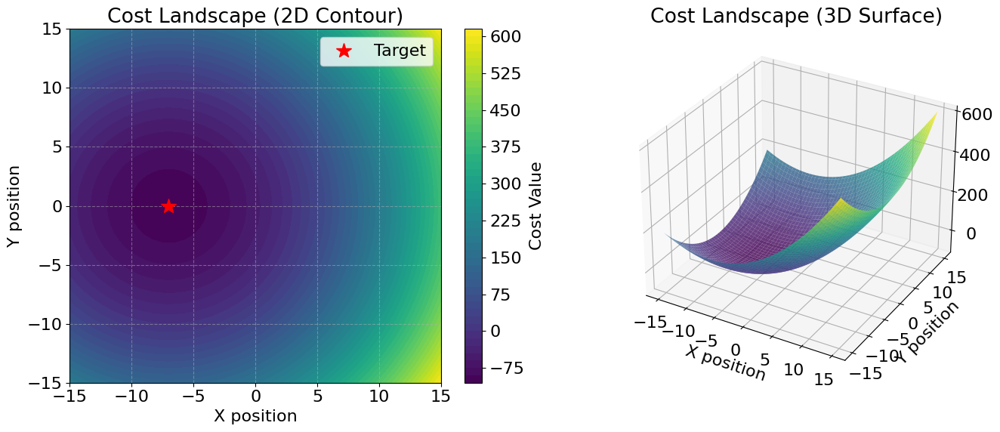

In [5]:
def plot_cost_landscape(target):
    """
    Plots the 2D contour and 3D surface of the cost function 
    by directly calling the cost() function.
    Assumes control input u = [0, 0].
    """
    
    # Zero control effort for visualization
    u_val = [0.0, 0.0]
    
    # Evaluate the original cost() function point by point on a grid deifned in a pervious code section 
    for i in range(XX.shape[0]):
        for j in range(XX.shape[1]):
            # Current state on the grid
            x_val = [XX[i, j], YY[i, j]] 
            
            # Call your CasADi cost function and cast the result to a Python float
            cost_value = cost(x_val, u_val, target)
            Z[i, j] = float(cost_value)

    # Create the plots
    fig = plt.figure(figsize=(14, 6))

    # --- Plot 1: 2D Contour (Heatmap) ---
    ax1 = fig.add_subplot(1, 2, 1)
    contour = ax1.contourf(XX, YY, Z, levels=50, cmap='viridis')
    fig.colorbar(contour, ax=ax1, label='Cost Value')
    
    # Plot the target position as a red star
    ax1.plot(target[0], target[1], 'r*', markersize=15, label='Target')
    ax1.set_title("Cost Landscape (2D Contour)")
    ax1.set_xlabel("X position")
    ax1.set_ylabel("Y position")
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    # --- Plot 2: 3D Surface ---
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    surf = ax2.plot_surface(XX, YY, Z, cmap='viridis', edgecolor='none', alpha=0.8)
    ax2.set_title("Cost Landscape (3D Surface)")
    ax2.set_xlabel("X position")
    ax2.set_ylabel("Y position")
    
    plt.tight_layout()
    plt.show()
   

# Function call
plot_cost_landscape(target=target_pos)

The obstacles are defined as 3 ellipses forming a C shape.

 An elliptical constraint can be modeled as: 
$$\frac{(x - x_c)^2}{a^2} + \frac{(y - y_c)^2}{b^2} - 1 \ge 0$$

With: 
* $x_c, y_c$: Coordinates of the center of the ellipse.
* $a$: Length of the semi-axis along the X direction (horizontal "radius").
* $b$: Length of the semi-axis along the Y direction (vertical "radius").

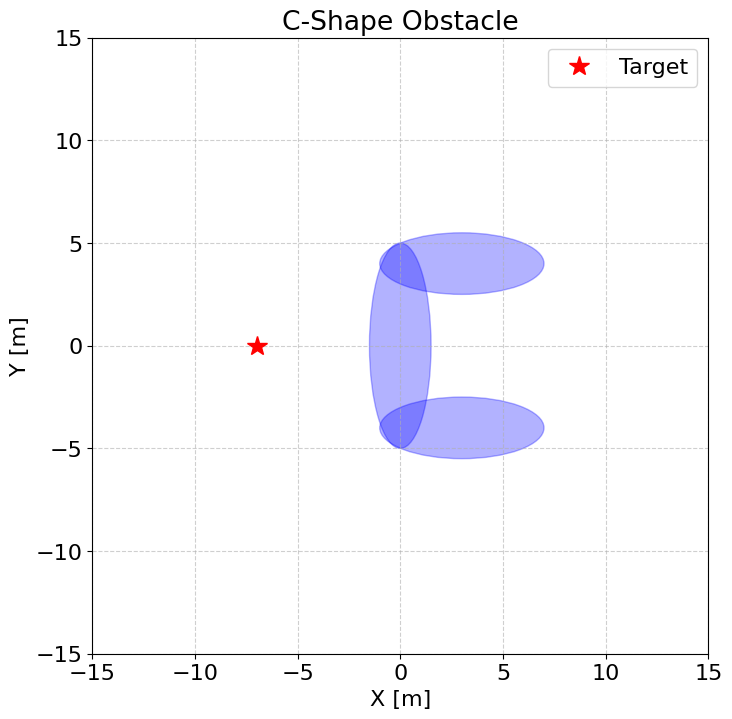

In [6]:
def elliptical_constraints(x_next, ellips_params, backend ='casadi'):
    """
    Generate the mathematical constraint equations using CasADi.
    Allows to compute the constraints using either CasADi or JAX by changing the 'backend' argument.

    args:
        x_next: The next state of the system (position) for which we want to evaluate the constraints.
        ellips_params: A list of dictionaries, where each dictionary contains the parameters of an ellipse
        backend: A string that specifies the library to use for computations. It can be 'casadi' or 'jax'.

    returns:
        A list of inequality expressions representing the constraints for each ellipse.  
    """

    x_pos = x_next[0]
    y_pos = x_next[1]

    constraints = []
    for param in ellips_params:
        x_term = ((x_pos - param['x_ob'])**2) / (param['a']**2)
        y_term = ((y_pos - param['y_ob'])**2) / (param['b']**2)

        g_ellipse = x_term + y_term - 1
        constraints.append(g_ellipse)
        
    if backend == 'jax':
        return jnp.array(constraints)
    else:   
        return constraints


def plot_ellipses(ellips_params, ax=None, target=None):
    """
    Plots filled ellipses.
    If 'ax' is provided, it plots on that axis. 
    Otherwise, it creates a new standalone figure.
    """
    # If no ax is passed create a newe one
    show_plot = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))
        show_plot = True

    # Draw the ellipses 
    for param in ellips_params:
        ellipse = Ellipse(xy=(param['x_ob'], param['y_ob']), 
                          width=param['a']*2, height=param['b']*2, 
                          edgecolor='blue', facecolor='blue', alpha=0.3)
        ax.add_patch(ellipse)

    # Draw target 
    if target is not None:
        ax.plot(target[0], target[1], 'r*', markersize=15, label='Target')

    # Settings
    ax.set_aspect('equal') 
    ax.set_xlim(-15, 15)
    ax.set_ylim(-15, 15)
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title("C-Shape Obstacle")
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Legend
    handles, labels = ax.get_legend_handles_labels()
    if labels:
        ax.legend()
    
    if show_plot:
        plt.show()

# 1. CasADi Constraints
X = ca.SX.sym('X')
Y = ca.SX.sym('Y')
state_sym = ca.vertcat(X, Y)
constraints_eq = elliptical_constraints(state_sym, obstacle_parameters)

# 2. Plot call
plot_ellipses(obstacle_parameters, target=target_pos)

## Define a class for solving the optimal control problem with the optimal control library Casadi

The discrete-time Optimal Control Problem over an horizon $N$ can be mathematically formulated as follows:$$\begin{aligned}
\min_{\mathbf{x}, \mathbf{u}} \quad & \sum_{i=0}^{N-1} \ell(x_i, u_i, x_{\text{target}}) + \ell(x_N, \mathbf{0}, x_{\text{target}}) \\
\text{s.t.} \quad & x_0 = x_{\text{init}} \\
& x_{i+1} = f(x_i, u_i), \quad \forall i \in \{0, \dots, N-1\} \\
& g_k(x_i) \ge 0, \quad \forall i \in \{0, \dots, N\}, \; \forall k \in \{1, \dots, M\} \\
& x_N = x_{\text{target}} \\
& -u_{max} \le u_i \le u_{max} \quad \forall i \in \{0, \dots, N-1\}
\end{aligned}$$

Notation and Variables:
* Decision Variables:
  - $\mathbf{x} = \{x_0, x_1, \dots, x_N\}$ is the state sequence, where $x_i \in \mathbb{R}^{n_x}$.
  - $\mathbf{u} = \{u_0, u_1, \dots, u_{N-1}\}$ is the control sequence, where $u_i \in \mathbb{R}^{n_u}$.

* Objective Function (Cost):
  - $\ell(x_i, u_i, x_{\text{target}})$ represents the running cost function evaluated at each step $i$.The terminal cost is computed using the same cost function $\ell$, but applying a zero control input $\mathbf{0}$ at the final step $N$.
* Constraints:
  - Initial Condition: $x_0 = x_{\text{init}}$ ensures the trajectory starts from the given initial state.
  - System Dynamics: $x_{i+1} = f(x_i, u_i)$ defines the state transition. For a single integrator system, this typically represents standard integration, e.g., $x_{i+1} = x_i + u_i \Delta t$.
  - Obstacle Avoidance: $g_k(x_i) \ge 0$ requires the state to remain outside or on the boundary of the $M = 3$ defined elliptical obstacles at all times.
  - Control limits: $-u_{max} \le u_i \le u_{max}$

In [7]:
class OcpSingleIntegrator:
    '''
    A class to solve an Optimal Control Problem (OCP) for a single integrator.
    '''

    def __init__(self, target, cost_params, obstacle_params):

        self.target = target
        self.cost_params = cost_params
        self.obstacle_params = obstacle_params

    def solve(self, x_init, N, X_guess=None, U_guess=None):
        self.opti = ca.Opti() # Use casadi
        
        # create the state and control variables
        self.x = self.opti.variable(n_x, N+1) 
        self.u = self.opti.variable(n_u, N)
        x = self.x
        u = self.u

        # warm-start the solver with the provided initial guess (if any)
        if(X_guess is not None):
            for i in range(N+1):
                self.opti.set_initial(x[:, i], X_guess[i,:])
        else:
            # otherwise initialize the state trajectory with the initial state
            for i in range(N+1):
                self.opti.set_initial(x[:, i], x_init)
        if(U_guess is not None):
            for i in range(N):
                self.opti.set_initial(u[:, i], U_guess[i,:])
        else:
            # otherwise initialize the control at 0
            for i in range(N):
                self.opti.set_initial(u[:, i], 0.0) 
        # define the cost function
        self.cost = 0
        self.running_costs = [None,]*(N+1) # Preallocate a list
        
        for i in range(N+1):
            if(i<N):
                self.running_costs[i] = cost(x[:, i], u[:, i], self.target, self.cost_params)
            else:
                # the final cost is the same as the running cost but with zero control inputs
                zero_u = ca.vertcat(0.0, 0.0)
                self.running_costs[i] = cost(x[:, i], zero_u, self.target, self.cost_params)
            self.cost += self.running_costs[i]
            
            # Elliptical obstacles constraints
            obs_constraints = elliptical_constraints(x[:, i], self.obstacle_params)
            for g in obs_constraints:
                self.opti.subject_to(g >= 0)
        

        # Define the dynamics constraints and teh controls constraints 
        for i in range(N):            
            
            self.opti.subject_to( x[:, i+1]== dynamic_1d(x[:, i], u[:, i]) )
            self.opti.subject_to( self.opti.bounded(-U_MAX, u[:, i], U_MAX) ) # Control limits

        # Set the initial state
        self.opti.subject_to(x[:, 0]==x_init)
        
        # Set final state constraint
        self.opti.subject_to(x[:, -1] == self.target)
        # NOTE: if the final consrt is used you get failed trajectories (not wanted)
        
        self.opti.minimize(self.cost)

        # Solve the problem with IpOpt
        opts = {'ipopt.print_level': 0, 'print_time': 0, 'ipopt.sb': 'yes'}
        self.opti.solver("ipopt", opts)

        return self.opti.solve()

## Try to solve some OCPs

Create an OCP solver and start evaluating it w/o initial guess. We can see how the solver fails in the "hard zone", thus inside the C formed by the ellipses.

Solver failed for init state [5. 0.]
Solver failed for init state [6.  1.5]
Solver failed for init state [ 6.  -1.5]
Solver failed for init state [5.5 2.5]
Solver failed for init state [ 5.5 -2.5]
Solver failed for init state [2. 0.]
Solver failed for init state [1.5 1. ]
Solver failed for init state [ 1.5 -2. ]
Solver failed for init state [2.3 1. ]
Solver failed for init state [ 3. -1.]
Solver failed for init state [4. 2.]
Solver failed for init state [ 4. -2.]
Solver failed for init state [3.4 0.8]
Solver failed for init state [10.  5.]
Solver failed for init state [10. -5.]


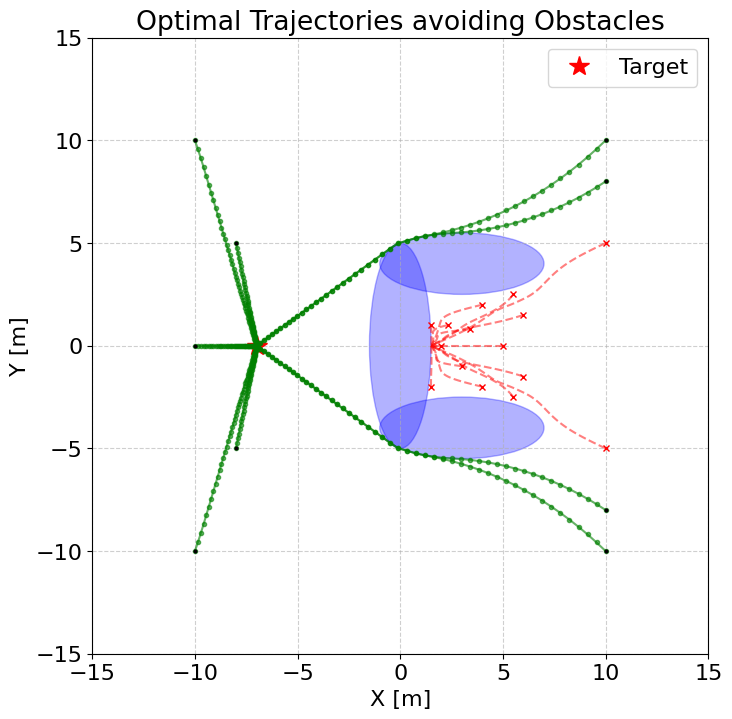

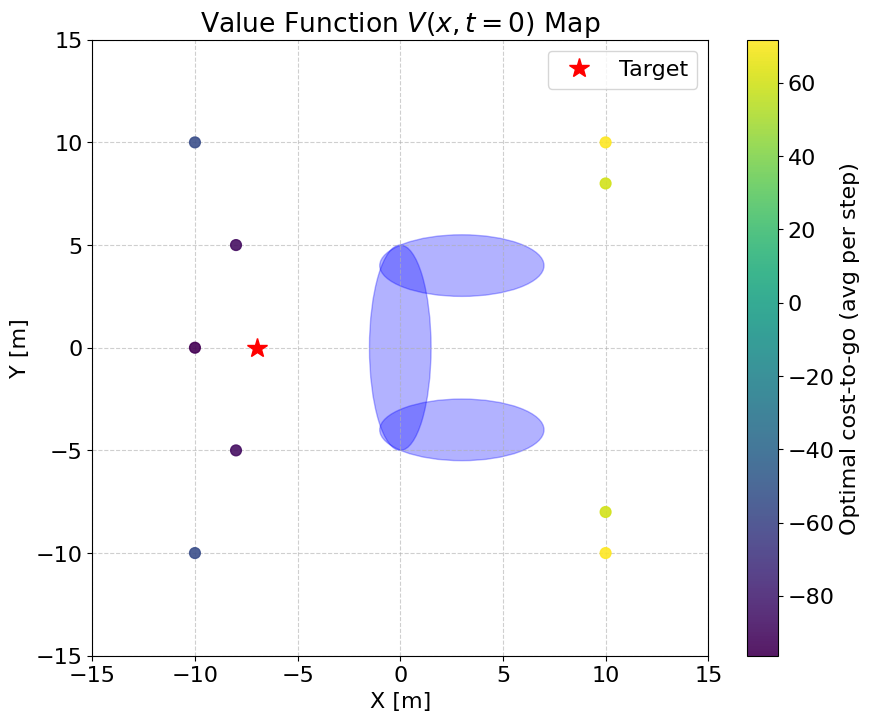

In [8]:
# 1. Initialize the OCP solver passing the required arguments
ocp = OcpSingleIntegrator(target=target_pos, cost_params=cost_weights, obstacle_params=obstacle_parameters)


V = np.empty((len(X_init_grid), CACTO_ITERS+1)) # Value function at each state for each CACTO iteration


# PLOT 1: OPTIMAL TRAJECTORIES IN 2D SPACE
fig, ax = plt.subplots(figsize=(10, 8))

# Plot obstacles
plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)
ax.set_title("Optimal Trajectories avoiding Obstacles")

# Solve the OCP for the given initial states x_init and horizon N 
for i, x_init in enumerate(np.array(X_init_grid)):
    try:
        sol = ocp.solve(x_init, N)   
        V[i, 0] = sol.value(ocp.cost) 
        x_traj = sol.value(ocp.x) 
        
        ax.plot(x_traj[0, :], x_traj[1, :], alpha=0.6, linewidth=1.5, 
                color='green', marker='o', markersize=3)
        
        ax.plot(x_init[0], x_init[1], 'k.', markersize=4)
        
    except Exception as e:
        print(f"Solver failed for init state {x_init}")
        
        V[i, 0] = np.nan 
        
        ax.plot(x_init[0], x_init[1], 'rx', markersize=4)
        
        x_traj_failed = ocp.opti.debug.value(ocp.x)
        
        ax.plot(x_traj_failed[0, :], x_traj_failed[1, :], 'r--', 
                alpha=0.5, linewidth=1.5)

ax.legend(loc='best')
plt.show()


# PLOT 2: Value function map
fig, ax = plt.subplots(figsize=(10, 8))

# Plot obstacles 
plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

# Title
ax.set_title("Value Function $V(x, t=0)$ Map")

# Plot the value function
scatter = ax.scatter(np.array(X_init_grid)[:, 0], np.array(X_init_grid)[:, 1], 
                     c=V[:, 0]/(N+1), cmap='viridis', s=60, alpha=0.9, zorder=3)

# Add colorbar to show the scale
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Optimal cost-to-go (avg per step)")

plt.show()

## Replay buffer
Define a class representing the replay buffer. Data is stored using Python lists, but when retrieved with the "get" methods it is converted to Jax arrays, so that it can be directly used to train/evaluate the neural networks.

In [9]:
class ReplayBuffer:
    def __init__(self, name):
        self.name = name
        self.X = []
        self.Out = []

    def append(self, x, out):
        self.X.append(x)
        self.Out.append(out)

    def getX(self):
        return jnp.array(self.X)
    
    def getOut(self):
        out_array = jnp.array(self.Out)
        if out_array.ndim == 1:
            return out_array.reshape((len(self.Out), 1))
        return out_array
    
    def clean(self):
        self.X = []
        self.Out = []

## Neural networks structure
Define a class representing a standard Multi-Layer Perceptron neural network based on Flax. This neural network will be used to represent the critic and the actor. We use the ELU activation function, which is a smooth version of the ReLU (Rectified Linear Unit) function.


**NOTES**: 
* A perceptron is essentially a neuron 
* JAX: A high-performance mathematical computation library (essentially a super-powered NumPy with GPU/TPU support and automatic differentiation).
* Flax: A Neural Network framework built on top of JAX. While JAX handles the raw math, Flax provides the ready-to-use building blocks (layers, activation functions, parameter management) needed to easily construct and train ML models.

So JAX is similar to Numpy but more powefull, so it is a tool for mathematical computation. Flax introduces the tools, methos ecc. based on JaX to buid Neural Networks.

In [10]:
# A multi-layer perceptron using ELU activation functions
class MLP(nn.Module):
  '''
  A Multi-Layer Perceptron model.

  Args:
      features: A sequence of integers defining the number of neurons in each layer.
                Example: [64, 32, 2] creates two hidden layers and one output layer.
  
  Returns:
      The output of the network (logits/predictions) after the forward pass.
  '''
  features: Sequence[int]

  @nn.compact
  def __call__(self, x):
    for feat in self.features[:-1]:
      x = nn.elu(nn.Dense(feat)(x))
    x = nn.Dense(self.features[-1])(x)
    return x
  
# NO MORE NEED FOR THIS FUNCTION SINCE WE ARE USING OPTAX
# # Function to update the weights of the network
# @jax.jit
# def update_params(params, learning_rate, grads):
#   params = jax.tree_util.tree_map(
#       lambda p, g: p - learning_rate * g, params, grads)
#   return params


1. Building the Neural Network (using Flax) 

  This part of the code is used to "draw" the structure of our artificial brain.

  * `class MLP(nn.Module):` This class defines our Neural Network (Multi-Layer Perceptron), building it on top of the base module provided by the Flax library.
  * `features: Sequence[int]`: This is a simple list of numbers that determines the size of the network. For example, passing `[64, 32, 2]` tells Flax to create a first hidden layer with 64 neurons, a second with 32, and a final output layer with 2 neurons.
  * `@nn.compact`: A very convenient decorator exclusive to Flax. In traditional libraries, you usually have to declare the layers first and then connect them later. This command allows you to define and use the layers at the exact same time the data passes through them (inside the `__call__` function), saving a lot of boilerplate code.
  * `self.features[:-1]` (The Slicing): In Python, `[:-1]` means "take the whole list except the very last item". If your features list is `[64, 32, 2]`, this loop will only iterate over 64 and 32. We do this because the inside layers (hidden layers) need an activation function to learn complex patterns, but the final output layer (the 2) needs to output raw, unactivated numbers.
  * `nn.Dense(feat)(x)` (Create & Apply): Thanks to the `@nn.compact` decorator, this specific part does two things simultaneously: it defines a new fully-connected layer with `feat` neurons (e.g., 64), and immediately feeds the current input data `x` into it.
  * `nn.elu(...)` (The Activation): The mathematical output of the Dense layer is immediately wrapped inside the ELU (Exponential Linear Unit) function. This introduces non-linearity.
  * So `x = nn.elu(nn.Dense(feat)(x))` creates a fully connected (dense) layer with input _x_ and activation function ELU.
  * `x = nn.Dense(self.features[-1])(x)`: the last layer. It is just afully connected layer, no activation.


2. Learning and Updating Weights (using JAX) (NO MORE USED)

  This part of the code is the "engine" that allows the network to correct its mistakes and learn, exploiting the mathematical speed of JAX.

  * `@jax.jit`: Stands for Just-In-Time compilation. By putting this line above the function, JAX takes your Python code and translates it into super-optimized machine language (XLA) right before running it. This makes computation very fast, especially on a GPU.
  * `jax.tree_util.tree_map`: Unlike other libraries, in Flax the millions of network "weights" and their respective errors (gradients) are not stored inside the network itself. They are saved in large, tree-structured dictionaries called PyTrees. This function is used to apply a mathematical rule to all the numbers inside these dictionaries at once, without having to write slow `for` loops.
  * `lambda p, g: p - learning_rate * g`: This is the classic mathematical formula that neural networks use to learn (called Gradient Descent). In simple terms, it means: "Take the old weight (`p`), and subtract the error made (`g`) scaled by how fast we want the network to learn (`learning_rate`). The result is the new, corrected weight."

**More about `jax.tree_util.tree_map`:**

It updates the entire set of network weights (`params`) by applying the information stored in the gradients (`grads`) using the rule/formula `f` (in this case, gradient descent).

Call:
`jax.tree_util.tree_map(f, tree, *rest, is_leaf=None)`

In my case:
`jax.tree_util.tree_map(lambda p, g: p - learning_rate * g, params, grads)`

* `f`: `lambda p, g: p - learning_rate * g`. It defines how to combine the data. Since I provided two trees, the lambda must take two arguments (`p` for params and `g` for grads).
* `tree`: `params`. The Pytree that contains the current weights of the neural network.
* `*rest`: `grads`. The Pytree that contains the calculated gradients of the cost function.

Note: `lambda` is a keyword used to define an anonymous, one-line function on the fly.
<br>
<br>
<br>

### Define a class that contains a neural network and the standard machinery for training the network to fit a given target using a Mean-Squared Error loss. 

$ \text{loss}(\theta) = \sum_{i=0}^{k-1} \frac{1}{2} || V_\theta(x_i) - \bar{V}_i ||^2$

This class will be used for the critic, which needs to be trained in a standard supervised-learning fashion.
<br>
<br>
<br>

**NOTES:** 
* I need to initialize the weights (parameters) and to define dummy/fake inputs. The latter is needed because doing so JAX can compute the number of weights of the network that depends on the input size. So, instead of giving the input size to the class, with JAX I just define fake inputs so it computes this value by itself.

  To do this, I need to randomly generate these values. To do so, JAX needs a random key for each random operation. So, 2 in this case.

  I use the method `k1, k2 = random.split(random.PRNGKey(random_seed))` that allows me to split a seed into as many random keys as I want. Doing so, I can randomly initialize the weights and define the fake inputs.

  Once i've generated the keys i can initialize the parameters by calling the `init(key, dummy_input)` function. 

  For more see: [Flax basics site](https://flax-linen.readthedocs.io/en/latest/guides/flax_fundamentals/flax_basics.html)

* `pred = self.model.apply(params, x)` fucntion that given the parameters (weights) and inputs gives the predictions of the model (outputs). Method from Flax
* `jax.vmap(fun, ...)`: 
  It automatically transforms a function written for a single data point (`fun`) into a new function that can process an entire batch of data at once. By mapping the function over the argument axes, it eliminates the need for slow `for` loops. This allows JAX to compute the results for all items in the batch simultaneously and in parallel, maximizing the computational power of the CPU/GPU.
* `jax.value_and_grad(fun)`: 
  It takes a function (like the `mse` loss) and returns a new function. When called, this new function evaluates the original one to return the actual output/value (the Loss in this case) and simultaneously computes the gradient of that function. 
* `def __call__(self, x): return self.model.apply(self.params, x)`: \_\_call\_\_ is a special method (dunder method) that makes the objecgt callable like a funztion. So instaed of doing a call like _my_network.prediction(x)_ i can just do _predictions = my_network(x)_.
* `assert( condition )`: if the condition is true the code continues.ì, if it is false it rises an exception.


In [11]:
class NeuralNetwork:
    """
    Initializes the Neural Network, setting up the model architecture, 
    parameters, and the functions required for training.

    Args:
        name (str): The name identifier for the neural network.
        in_dim (int): The dimensionality of the input data.
        out_dim (int): The dimensionality of the output predictions.
        layer_sizes (list of int): A list specifying the number of neurons in each hidden layer.
        learning_rate (float, optional): The step size used for updating weights during gradient descent.
        random_seed (int, optional): The seed used to initialize JAX's pseudo-random number generator for reproducible 
        weights. Defaults to 0.
    """
    
    def __init__(self, name, in_dim, out_dim, layer_sizes, learning_rate=0.1, random_seed=0):
        # Set problem dimensions.
        self.name = name
        self.random_seed = random_seed
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.learning_rate = learning_rate
        
        # Set up the optimizer using Optax with gradient clipping and Adam optimization.
        self.optimizer = optax.chain(
            optax.clip_by_global_norm(1.0),
            optax.adam(self.learning_rate)
        )

        self.model = MLP(layer_sizes + [out_dim])
        k1, k2 = random.split(random.PRNGKey(random_seed))
        x = random.normal(k1, (in_dim,)) # Dummy input data
        self.params = self.model.init(k2, x) # Initialization call
        jax.tree_util.tree_map(lambda x: x.shape, self.params) # Checking output shapes
        
        self.opt_state = self.optimizer.init(self.params)

        # Mean-Squared Error loss function
        @jax.jit
        def mse(params, x_batched, y_batched):
            # Define the squared loss for a single pair (x,y)
            def squared_error(x, y):
                pred = self.model.apply(params, x)
                return jnp.sum(jnp.square(pred - y)) / 2.0 # computes the scalar product between 2 vectors
            # Vectorize the previous to compute the average of the loss on all samples.
            return jnp.mean(jax.vmap(squared_error)(x_batched,y_batched), axis=0)
        
        # function computing both the loss and its gradient
        self.loss_grad_fn = jax.value_and_grad(mse)
        # function computing the loss
        self.loss = mse


    def __call__(self, x):
       return self.model.apply(self.params, x)


    def train(self, in_samples, out_samples, n_epochs=1, minibatch_size=128, print_every=5):
        """
        Train the network using epochs and sequential minibatches.
        """
        N = in_samples.shape[0]
        indices = np.arange(N)
        
        for epoch in range(n_epochs):
            # 1. Shuffle dataset indices at the start of each epoch
            np.random.shuffle(indices)
            
            # 2. Sequential minibatch loop
            for start_idx in range(0, N, minibatch_size):
                end_idx = min(start_idx + minibatch_size, N)
                batch_indices = indices[start_idx:end_idx]
                
                in_batched = in_samples[batch_indices, :]
                out_batched = out_samples[batch_indices, :]
                
                # 3. Gradient update
                loss_val, grads = self.loss_grad_fn(self.params, in_batched, out_batched)
                updates, self.opt_state = self.optimizer.update(grads, self.opt_state, self.params)
                self.params = optax.apply_updates(self.params, updates)

            # 4. Periodic logging of MSE and RMSE
            if (epoch + 1) % print_every == 0 or epoch == 0:
                current_mse = self.loss(self.params, in_samples, out_samples)
                rmse = jnp.sqrt(current_mse)
                print(f"Epoch {epoch+1}/{n_epochs} | MSE: {current_mse:.4f} | RMSE: {rmse:.4f}")
            
        return self.loss(self.params, in_samples, out_samples)

### Define a class containing the actor network and the code for training it. 

Since the actor is trained by minimizing the Q function, we need to pass it the cost $l(x,u)$, the Value network model $V(\cdot)$ and the dynamic model $f(x,u)$, because the Q function is computed as:

$Q(x,u) = l(x,u) + V(f(x,u))$

Thus my loss is the mean of the Q function over a batch: 

$$\mathcal{L}(\theta) = \frac{1}{S} \sum_{i=1}^{S} \Big( \ell(x_i, u_i) + V_\phi(f(x_i, u_i)) \Big)$$

Where:
- $\theta$ are the parameters of the actor.
- $u_i = \pi(x_i,  \theta)$ is the action predicted the Actor itself.
- $\ell(x_i, u_i)$ is the immediate running cost.
- $f(x_i, u_i)$ represents the system dynamics that yield the future state.
- $V_\phi$ is the value estimated by the Critic.

In [12]:
class ActorNetwork:
    def __init__(self, name, in_dim, out_dim, layer_sizes, cost, V_model, dynamic, learning_rate=0.001, random_seed=0):
        self.name = name
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.learning_rate = learning_rate

        self.model = MLP(layer_sizes + [out_dim])
        self.V_model = V_model
        self.dynamic = dynamic
        self.cost = cost

        k1, k2 = jax.random.split(jax.random.PRNGKey(random_seed))
        x = jax.random.normal(k1, (in_dim,)) 
        self.params = self.model.init(k2, x)

        self.optimizer = optax.chain(
            optax.clip_by_global_norm(1.0),
            optax.adam(self.learning_rate)
        )
        self.opt_state = self.optimizer.init(self.params)

        # --- Define JIT-compiled functions here to avoid recompiling during training ---
        def Q_batch(params, x_batched):           
            def Q_single(x):
                # We use the model to get control u
                u = self.model.apply(params, x)
                # Q = running_cost + V(next_state)
                return self.cost(x, u) + self.V_model(self.dynamic(x, u))[0]
            return jnp.mean(jax.vmap(Q_single)(x_batched), axis=0)

        self.loss_grad_fn = jax.jit(jax.value_and_grad(Q_batch))
        self.loss_fn = jax.jit(Q_batch)

    def __call__(self, x):
        return self.model.apply(self.params, x)
    
    def train(self, in_samples, n_epochs=1, minibatch_size=32, print_every=5):
        """
        Trains the Actor network using an epoch-based approach with sequential minibatches.
        """
        N = in_samples.shape[0]
        if minibatch_size > N:
            minibatch_size = N
            
        # Create an array of indices covering the entire dataset
        indices = np.arange(N)
        
        print(f"--- Starting Actor training for {n_epochs} epochs ---")

        for epoch in range(n_epochs):
            # 1. Shuffle indices at the start of each epoch to prevent order-bias
            np.random.shuffle(indices)
            
            # 2. Process the dataset in sequential minibatches
            for start_idx in range(0, N, minibatch_size):
                end_idx = min(start_idx + minibatch_size, N)
                batch_indices = indices[start_idx:end_idx]
                
                # Extract the current batch of states
                x_batched = in_samples[batch_indices, :]
                
                # 3. Compute loss and gradients
                loss_val, grads = self.loss_grad_fn(self.params, x_batched)
                
                # 4. Apply gradient updates to the network parameters
                updates, self.opt_state = self.optimizer.update(grads, self.opt_state, self.params)
                self.params = optax.apply_updates(self.params, updates)

            # --- Periodic Logging ---
            if (epoch + 1) % print_every == 0 or epoch == 0:
                # Evaluate the total loss across the entire dataset for accurate monitoring.
                # Note: For the Actor, the "loss" represents the mean Q-value.
                total_q_val = self.loss_fn(self.params, in_samples)
                print(f"Epoch {epoch + 1}/{n_epochs} | Actor Loss (Mean Q-value): {total_q_val:.4f}")

        # Return the final loss evaluated on the whole dataset
        return self.loss_fn(self.params, in_samples)

## Notes on constraints (Augmented Lagrangian actor)

### AL Theory:
#### Quadratic Penalty Method
The Quadratic Penalty Method (QPM) transforms a constrained optimization problem into an unconstrained one by adding a penalty term that "punishes" the solver only when constraints are violated.

Consider a standard problem with inequality constraints:

$$\min_x f(x) \quad \text{s.t.} \quad g(x) \le 0$$

Instead of solving this directly, we define a new unconstrained objective function:

$$\Phi(x) = f(x) + \frac{1}{2} \rho \max(0, g(x))^2$$


The $\max(0, g(x))$ ensures we only penalize actual violations ($g(x) > 0$).  The therm $\rho > 0$ is the penalty parameter.

The idea is to minimize the new function starting with small values of $\rho$, allowing slight constraint violations. Then, $\rho$ is gradually increased at each iteration, resulting in a massive penalty that strictly forces the final solution into the feasible region.

**Problem:** As $\rho$ becomes massive (e.g., $10^6$), the problem becomes ill-conditioned. Gradients near the constraint boundary explode, causing gradient-based solvers (like Adam) to oscillate violently or fail completely. 

#### AL Method

The Augmented Lagrangian Method (ALM) improves upon the QPM by adding an extra term involving Lagrange multipliers ($\lambda$). 
This allows the solver to satisfy constraints accurately without requiring the penalty parameter $\rho$ to go to infinity.

The unconstrained objective function is redefined as:

$$\mathcal{L}_A(x, \lambda, \rho) = f(x) + \lambda^T  \max(0, g(x)) + \frac{1}{2} \rho \max(0, g(x))^2$$

The term $\lambda \ge 0$ estimates the "force" required to keep the solution on the boundary of the constraint.
The idea is to update $\lambda$ after each optimization step based on the measured violation. By shifting the focus onto $\lambda$, we can achieve feasibility even with moderate values of $\rho$, avoiding the numerical instability and ill-conditioning (exploding gradients) typical of the pure Penalty Method.


So in this case the Augmented Lagrangian Function was defined as:

$$\mathcal{L}_A(u_t, x_t, \lambda, \rho) = Q(u_t, x_t) + \lambda^T \max(0, g(x_{t+1})) + \frac{1}{2} \rho \|\max(0, g(x_{t+1}))\|^2$$

Where $x_{t+1} = f(u_t, x_t)$ is the dynamics function.


Note: that the number of `lambda` terms is equal to the number of constraints, so 3 in this case.

**Augmented Lagrangian Parameter Updates**

In this implementation, the Augmented Lagrangian (AL) parameters are updated within the training loop to bias the policy away from collisions using the following logic:

1. Penalty Terms
For each obstacle $i$, the violation is defined as $g_i(x) = \max(0, -\text{elliptic\_constr}_i(x))$. NB: i have minus because when the constraint is violated it assumes negative value. 

The parameters are updated as:
* Multiplier Update: $\lambda_{i} \leftarrow \lambda_{i} + \rho_{i} g_i(x)$
* Penalty Update: $\rho_{i} \leftarrow \gamma \rho_{i}$ (where $\gamma \geq 1$ is a growth factor)

2. Implementation Strategy
* Initialization: $\lambda$ and $\rho$ are initialized in the `ConsActorNetwork` class. .
* In this experiment, $\gamma$ is kept near $1$ and saturation limits were required. So upper limits of the walues of $\rho$ and $\lambda$ were imposed.

### Control Limits

To account for control limits a very basic approach was used.

 The raw output of the network is passed through a squashing function to ensure it stays within the feasible range $[-u_{max}, u_{max}]$.

We multiply the output of the network by:

$$u = u_{max} \cdot \tanh(y)$$

In [13]:
class ConsActorNetwork:
    
    def __init__(self, name, in_dim, out_dim, layer_sizes, cost, V_model, dynamic, constraint_fn, learning_rate=0.1, random_seed=0):
        
        # Set problem dimensions
        self.name = name
        self.random_seed = random_seed
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.learning_rate = learning_rate
        self.u_max = U_MAX
        
        # Augmented Lagrangian parameters
        self.rho_x = 1000.0  # Penalty coefficient 
        self.constraint = constraint_fn
        self.model = MLP(layer_sizes + [out_dim])
        self.V_model = V_model
        self.dynamic = dynamic
        self.cost = cost

        # Network initialization
        k1, k2 = jax.random.split(jax.random.PRNGKey(random_seed))
        x = jax.random.normal(k1, (in_dim,)) # Dummy input data
        self.params = self.model.init(k2, x)
        
        # Auto-detect number of constraints
        dummy_g = self.constraint(x)
        num_constraints = len(dummy_g)
        
        # Initialize Lagrange multipliers for state constraints
        self.lambda_x = jnp.zeros(num_constraints)
        
        # Set up the optimizer using Optax with gradient clipping and Adam optimization
        self.optimizer = optax.chain(
            optax.clip_by_global_norm(50.0),
            optax.adam(self.learning_rate)
        )
        self.opt_state = self.optimizer.init(self.params)


    def __call__(self, x):
       raw_u = self.model.apply(self.params, x)
       return self.u_max * jnp.tanh(raw_u) # Apply tanh to ensure the output is within control limits [-u_max, u_max]
    
    def train(self, in_samples, n_epochs=1, minibatch_size=32, print_every=5, grad_Q_vmap=None):
        N = in_samples.shape[0]
        if N == 0:
            raise ValueError("ConsActorNetwork.train: in_samples is empty.")
        if minibatch_size > N:
            minibatch_size = N

        # 1. JAX-Safe Loss Function: We MUST pass lambda_x and rho_x as arguments.
        # Otherwise, jax.jit will "freeze" them at their initial values!
        def Q_batch(params, x_batched, lam, rho):
            def Q_single(x):
                raw_u = self.model.apply(params, x)  # Actor output
                u = self.u_max * jnp.tanh(raw_u)     # Apply tanh to ensure control limits
                instant_cost = self.cost(x, u)       # Instantaneous cost
                x_next = self.dynamic(x, u)          # Next state
                V_next = self.V_model(x_next)[0]     # Critic evaluation at next state
        
                # Augmented Lagrangian
                g_raw = self.constraint(x_next)      # Constraint violation
                g = jnp.maximum(0.0, - g_raw)        # NB: -g_raw because when we enter the obstacle g_raw is negative, 
                                                     #     but we want to penalize only positive violations
                
                # Multivariate ALM penalty
                aug = jnp.dot(lam, g) + 0.5 * rho * jnp.sum(g * g)
                return instant_cost + V_next + aug
                
            return jnp.mean(jax.vmap(Q_single)(x_batched), axis=0)

        # value_and_grad with respect to params (argnums=0)
        loss_grad_fn = jax.jit(jax.value_and_grad(Q_batch, argnums=0))

        # 2. JAX-Safe Constraint Evaluation Function
        def g_batch(params, x_batched):
            def g_single(x):
                raw_u = self.model.apply(params, x)
                u = self.u_max * jnp.tanh(raw_u)
                
                x_next = self.dynamic(x, u)
                g_raw = self.constraint(x_next) 
                return jnp.maximum(0.0, -g_raw)  # NB: -g_raw because when we enter the obstacle g_raw is negative, 
                                                 #       but we want to penalize only positive violations
            return jax.vmap(g_single)(x_batched)
            
        g_batch_jit = jax.jit(g_batch)

        # --- EPOCH TRAINING LOOP ---
        indices = np.arange(N)
        print(f"--- Starting Constrained Actor training for {n_epochs} epochs ---")

        for epoch in range(n_epochs):
            np.random.shuffle(indices)

            # --- 1. PRIMAL UPDATE (Train Actor sui minibatch) ---
            for start_idx in range(0, N, minibatch_size):
                end_idx = min(start_idx + minibatch_size, N)
                batch_indices = indices[start_idx:end_idx]
                x_mb = in_samples[batch_indices, :]
        
                loss_val, grads = loss_grad_fn(self.params, x_mb, self.lambda_x, self.rho_x)
                updates, self.opt_state = self.optimizer.update(grads, self.opt_state, self.params)
                self.params = optax.apply_updates(self.params, updates)
        
            # --- 2. DUAL UPDATE (UNA SOLA VOLTA A FINE EPOCA!) ---
            g_vals = g_batch_jit(self.params, in_samples)
            g_avg = jnp.mean(g_vals, axis=0)  
            
            # Dual ascent step for Lambda
            self.lambda_x = jnp.clip(self.lambda_x + self.rho_x * g_avg, 0.0, lam_max)
            
            # Penalty growth step for Rho
            max_violation = float(jnp.max(g_avg))
            if max_violation > tolerance:
                self.rho_x = float(min(self.rho_x * rho_growth, rho_max))

            # --- Periodic Logging ---
            if (epoch + 1) % print_every == 0 or epoch == 0:
                total_q_val = Q_batch(self.params, in_samples, self.lambda_x, self.rho_x)
                log_str = f"Epoch {epoch + 1}/{n_epochs} | Mean Q+ALM: {total_q_val:.4f} | Max Viol: {max_violation:.5f} | Rho: {self.rho_x:.1f}"
                
                if grad_Q_vmap is not None:
                    U_pred = self(in_samples)
                    dQdu = grad_Q_vmap(U_pred, in_samples)
                    dQdu_norm = jnp.mean(jnp.linalg.norm(dQdu, axis=1))
                    log_str += f" | dQ/du norm: {dQdu_norm:.6f}"
                    
                print(log_str)

        # Return final loss and ALM parameters
        return Q_batch(self.params, in_samples, self.lambda_x, self.rho_x), self.lambda_x, self.rho_x

## Create main components of CACTO:
* Critic network
* Actor network
* Replay buffer

Note that the input size of the actor and critic network is equal to the size of the state plus one, to account for the time. We create also a second replay buffer to store the optimal control inputs just for plots.


In [14]:
critic = NeuralNetwork("Critic", n_x+1, 1, critic_layers, learning_rate_critic, RANDOM_SEED)
actor  = ActorNetwork("Policy", n_x+1, n_u, actor_layers, cost_aug, critic, dynamic_aug, 
                    learning_rate_actor, RANDOM_SEED)

# Define the constraint function for the actor network using the previously defined elliptical_constraints function
constr_for_ALnet = lambda x: elliptical_constraints(x, obstacle_parameters, backend='jax')

cons_actor  = ConsActorNetwork("Policy", n_x+1, n_u, actor_layers, cost_aug, critic, dynamic_aug,                  constr_for_ALnet, learning_rate_actor, RANDOM_SEED)
replay_buffer = ReplayBuffer("V")
control_buffer = ReplayBuffer("U")

# Start CACTO's main loop

### 1) Solve a batch of TO problems
Solve a batch of TO problems starting from random initial states and initial times. However, rather than sampling the horizon length in $[1, N]$ (as in the original CACTO algorithm) we fix it to $N-1$. The reason why we do it is that in this notebook we are interested in getting a good policy for $t=0$, therefore we should get a good critic for $t=1$, so we mainly care about exploring the state space for $t=1$, which is the initial time when the horizon is $N-1$. However we should acknowledge that fixing the horizon length to N-1 is problematic, as we may not explore the whole state space for time steps greater than 1. However, for the purpose of this notebook, this is fine.

**This was kept as Vinay did it. It is OK?**

In [15]:
def compute_initial_guess(X_samples, t0_samples, N_horiz, n_x, n_u, actor):
    ''' 
    Computes initial guesses for an entire batch of states simultaneously.
    
    Args:
        X_samples (array): Array of initial states for the system [Batch, n_x]. Batch = number of initial states.
        t0_samples (array): Array of initial times for the system [Batch].
        N_horiz (int): Time horizon for the trajectory.
        n_x (int): Dimensionality of the state space.
        n_u (int): Dimensionality of the control input space.
        actor (ConsActorNetwork): The constrained actor network used to generate the trajectory.
        
    Returns:
        X_guess (array): The state trajectory generated by rolling out the constrained actor's policy.
        U_guess (array): The control trajectory generated by the constrained actor's policy.
        V_cons (float): The total cost accumulated along the trajectory.
    
    '''
    B = X_samples.shape[0] # Batch size (= initial states num = 300)
    
    # Create the augmented state for all samples in the batch
    t0_col = np.array(t0_samples).reshape(B, 1)
    X_aug_t = np.concatenate([X_samples, t0_col], axis=1) # Shape: (B, n_x + 1)
    
    # Initialize arrays to store the trajectories and costs
    X_guess_seq = [X_aug_t[:, :-1]] # Store only the state part (exclude time) at each step
    U_guess_seq = []
    V_cons = np.zeros(B)
    
    # Rollout loop for the entire horizon
    # At each step, we compute the quantities for all samples in the batch simultaneously
    for t in range(N_horiz):
        
        # Get control input from the constrained actor for the current augmented state
        U_t = actor(X_aug_t) 
        U_guess_seq.append(U_t)
        
        # Add the cost for the current step
        V_cons += np.array(actor.cost(X_aug_t, U_t)).flatten()
        
        # Compute the next state using the dynamics
        X_aug_t = actor.dynamic(X_aug_t, U_t)
        X_guess_seq.append(X_aug_t[:, :-1]) # Store only the state part (exclude time)
        
    # Terminal cost for the final state
    V_cons += np.array(actor.cost(X_aug_t, np.zeros((B, n_u)))).flatten()
    
    #Reshape data from [time, batch, dim] to [batch, time, dim]
    X_guess_all = np.array(X_guess_seq).swapaxes(0, 1)
    U_guess_all = np.array(U_guess_seq).swapaxes(0, 1)
    
    return list(X_guess_all), list(U_guess_all), list(V_cons)

In [16]:
def solve_TO_problems(use_actor_to_warm_start=False, actor=None):
    '''
    Solves N_OCP trajectory optimization problems and fills the replay buffer with the resulting state-cost pairs.
    
    Args:
        use_actor_to_warm_start (bool): If True, uses the constrained actor to generate an initial guess for the solver. If False, no warm start is used.
        actor (ConsActorNetwork, optional): The constrained actor network used for warm starting. Required if use_actor_to_warm_start is True.
    '''
    
    print("Start solving %d TO problems" % N_OCP)
    replay_buffer.clean() # empty replay buffer for simplicity even though CACTO does not do that
    control_buffer.clean()
    start_time = timeit.default_timer()
    
    # sample initial states and initial times
    init_min = np.array([x_min, y_min])
    init_max = np.array([x_max, y_max])
    X_samples = generate_valid_initial_states(N_OCP, init_min, init_max, obstacle_parameters, n_x)
    N_samples = np.random.randint(N-1, N, size=N_OCP) # sample in [N-1, N] TODO: maybe we can sample in a wider range to have more diversity in the trajectories and costs? IMPORTANTE
    t0_samples = N - N_samples # initial time is the complement of the horizon (since we want to end at time N)
    
    #NOTE: now t0 always = 0 but we could sample it in a wider range to have more diversity in the trajectories and costs (e.g. t0 in [0, N-1])

    # Initialize the guess for the solver (if warm start is enabled)
    X_guess, U_guess = N_OCP*[None,], N_OCP*[None,]
    
    if(use_actor_to_warm_start): # compute initial guess
        
        # Calculate the initial guesses by calling the compute_initial_guess function
        print("Computing warm start guesses via Actor...")
        X_guess_batch, U_guess_batch, _ = compute_initial_guess(
            X_samples,  
            t0_samples,
            N, 
            n_x,
            n_u, 
            actor
        )
            
        # Convert the lists of trajectories into the format expected by the OCP solver (list of arrays)
        X_guess = [np.array(x) for x in X_guess_batch]
        U_guess = [np.array(u) for u in U_guess_batch]

    # solve an OCP for every sampled initial state-time
    success_count = 0
    
    # tqdm for progess bar
    for i in tqdm(range(N_OCP), desc="Risoluzione OCP", unit="traj"):
        try:
            sol = ocp.solve(X_samples[i,:], N_samples[i], X_guess[i], U_guess[i])
            success_count += 1
        except RuntimeError as e:
            # IPOPT failed
            tqdm.write(f"i={i}, X={X_samples[i,:]}: OCP failed | {str(e).splitlines()[-1]}")
            continue # we skip the rest of the loop and do not add any data to the buffer for this sample
        
        # recover the whole optimal trajectory
        J = 0
        for j in range(N_samples[i], -1, -1): # we iterate backward to compute the cost-to-go at each step
            
            # Data extraction and augmentation for the replay buffer
            x_val = np.array(sol.value(ocp.x[:, j])).flatten() 
            t_val = np.array([N - N_samples[i] + j])
            x_aug = jnp.concatenate([x_val, t_val])        
            
            # compute the optimal cost-to-go using Monte Carlo estimation (sum of running costs along the trajectory)
            if j < N_samples[i]:
                J += float(sol.value(ocp.running_costs[j]))
            
            # add the element to the replay buffer
            replay_buffer.append(x_aug, J)

            # save optimal control inputs for plots
            if(j < N_samples[i]):
                u_val = np.array(sol.value(ocp.u[:, j])).flatten()
                control_buffer.append(x_aug, u_val)

# FINAL CHECK
    duration = timeit.default_timer() - start_time
    print(f"--- Finished ---")
    print(f"Successfully solved: {success_count} / {N_OCP}")
    print(f"States Buffer size: {replay_buffer.getX().shape} samples")
    print(f"Time taken: {duration:.3f} s")

In [17]:
# First solve the TO problems and fill the replay buffer with the resulting state-cost pairs

# Iter counter
iter_count = 0
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=False)


--- CACTO Iteration 0 ---

Start solving 300 TO problems


Risoluzione OCP:  12%|█▏        | 35/300 [00:13<01:39,  2.66traj/s]

i=34, X=[9.23992122 1.24077798]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  13%|█▎        | 38/300 [00:15<02:16,  1.93traj/s]

i=37, X=[ 8.58052187 -1.72653079]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=288, X=[14.73744023 -9.96727739]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|█████████▉| 299/300 [01:45<00:00,  3.65traj/s]

i=298, X=[10.09082435 -2.81662106]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [01:45<00:00,  2.84traj/s]


--- Finished ---
Successfully solved: 263 / 300
States Buffer size: (13150, 3) samples
Time taken: 105.622 s


## 2) Train the critic network

Define a function to plot the critic network for a certain time, together with the data computed with TO.

In [18]:
def plot_critic(crit, t=0, show=True):
    # Get data from replay buffer
    X = replay_buffer.getX()          # Shape: [N, 3] -> [x, y, t]
    V_true = replay_buffer.getOut()   
    
    # Filter points at time 't'
    ind = jnp.where(X[:, 2] == t)[0]  
    X_t = X[ind, :2]                  
    V_t = V_true[ind]

    # Create 2D grid for the Critic
    x_lin = np.linspace(x_min, x_max, 50)
    y_lin = np.linspace(y_min, y_max, 50)
    X_mesh, Y_mesh = np.meshgrid(x_lin, y_lin)
    
    # Flatten grid and add time column
    grid_flat = np.c_[X_mesh.ravel(), Y_mesh.ravel()]
    time_col = np.full((grid_flat.shape[0], 1), t)
    X_aug = jnp.hstack([grid_flat, time_col])

    # Predict values on the grid
    V_crit = crit(X_aug).reshape(X_mesh.shape)

    # --- Plotting ---
    plt.figure(figsize=(10, 8))
    
    # Critic heatmap
    cp = plt.contourf(X_mesh, Y_mesh, V_crit, levels=40, cmap='viridis', alpha=0.8)
    plt.colorbar(cp, label="Critic Value (Normalized)")

    # True values from buffer
    if len(ind) > 0:
        plt.scatter(X_t[:, 0], X_t[:, 1], c=V_t, cmap='viridis', 
                    edgecolors='k', marker='o', s=50, label='True Value (CasADi)')

    # Draw obstacles
    for param in obstacle_parameters:
        ellipse = Ellipse((param['x_ob'], param['y_ob']), 2*param['a'], 2*param['b'], 
                          color='red', alpha=0.5)
        plt.gca().add_patch(ellipse)
        
    # Draw target
    plt.plot(target_pos[0], target_pos[1], 'r*', markersize=15, label='Target')

    plt.title(f"Critic '{crit.name}' prediction at t={t}")
    plt.xlabel("X Position")
    plt.ylabel("Y Position")
    plt.legend()
    
    if show:
        plt.show()

Start the training using the data from the buffer.

In [19]:
def train_critic():
    print("--- Start training critic ---")
    
    # 1. Get the data from the buffer
    X_aug, V_buffer = replay_buffer.getX(), replay_buffer.getOut() 
    
    # 2. Start the training using epochs and sequential minibatches
    final_mse = critic.train(
        X_aug, 
        V_buffer, 
        n_epochs=max_critic_iter, # Use max_critic_iter as the number of epochs
        minibatch_size=minibatch_size,
        print_every=5              # Print progress every 5 epochs
    )
    
    # 3. Final summary
    final_rmse = np.sqrt(final_mse)
    print(f"Final Critic MSE: {final_mse:.2f}")
    print(f"Final Critic RMSE: {final_rmse:.2f}")
    print("--- Critic training has finished ---")
        
        
print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_critic()


--- CACTO Iteration 0 ---

--- Start training critic ---
Epoch 1/50 | MSE: 198892.7969 | RMSE: 445.9740
Epoch 5/50 | MSE: 11065.5869 | RMSE: 105.1931
Epoch 10/50 | MSE: 17302.0996 | RMSE: 131.5374
Epoch 15/50 | MSE: 2652.6130 | RMSE: 51.5035
Epoch 20/50 | MSE: 1804.5099 | RMSE: 42.4795
Epoch 25/50 | MSE: 2905.9954 | RMSE: 53.9073
Epoch 30/50 | MSE: 1820.5931 | RMSE: 42.6684
Epoch 35/50 | MSE: 402.0233 | RMSE: 20.0505
Epoch 40/50 | MSE: 5615.3599 | RMSE: 74.9357
Epoch 45/50 | MSE: 2077.6692 | RMSE: 45.5815
Epoch 50/50 | MSE: 359.5162 | RMSE: 18.9609
Final Critic MSE: 359.52
Final Critic RMSE: 18.96
--- Critic training has finished ---


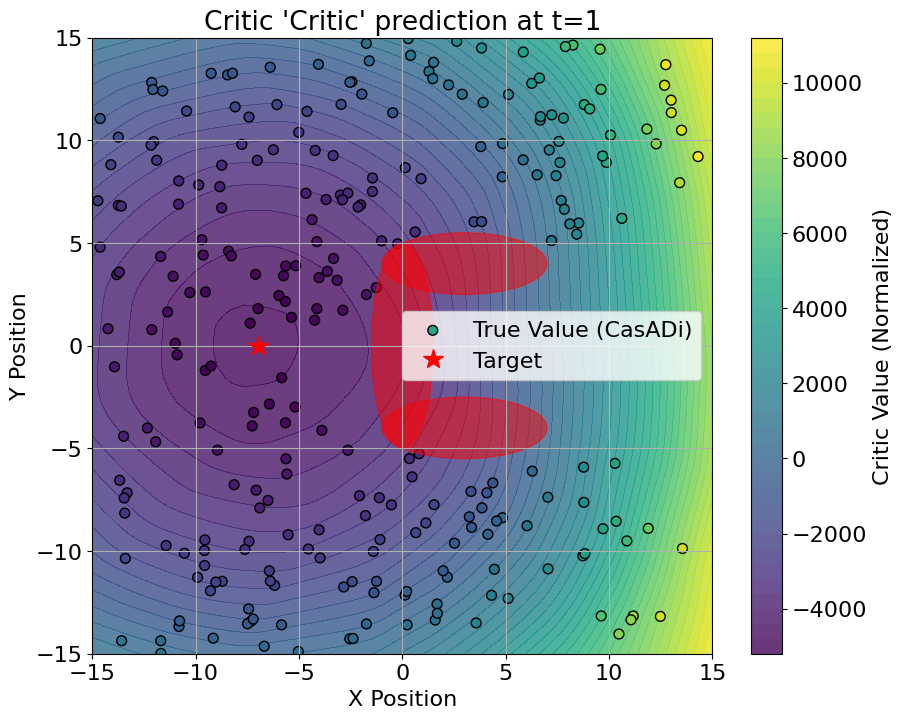

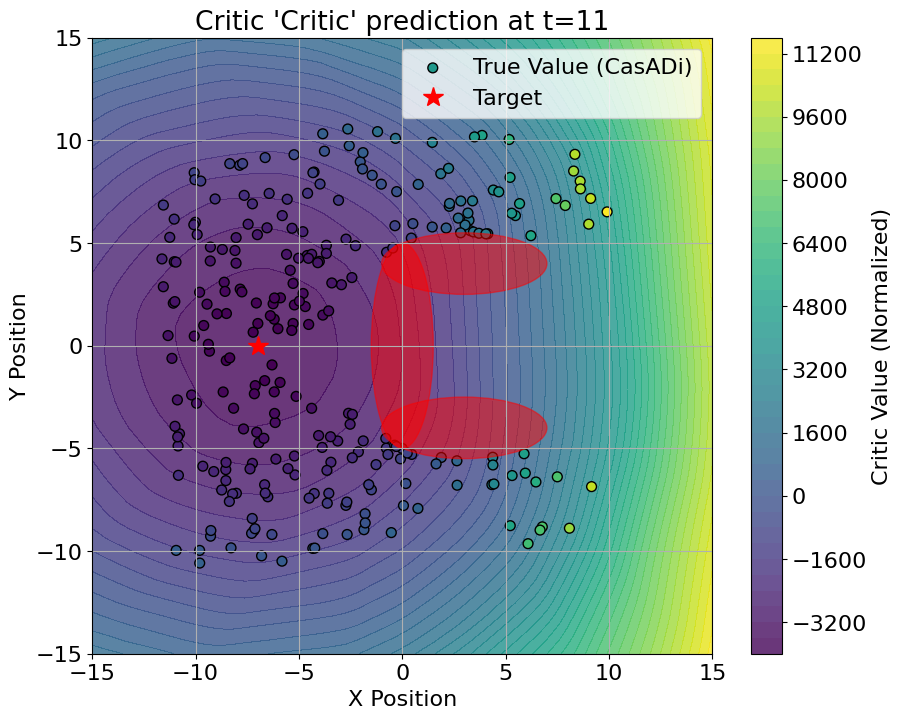

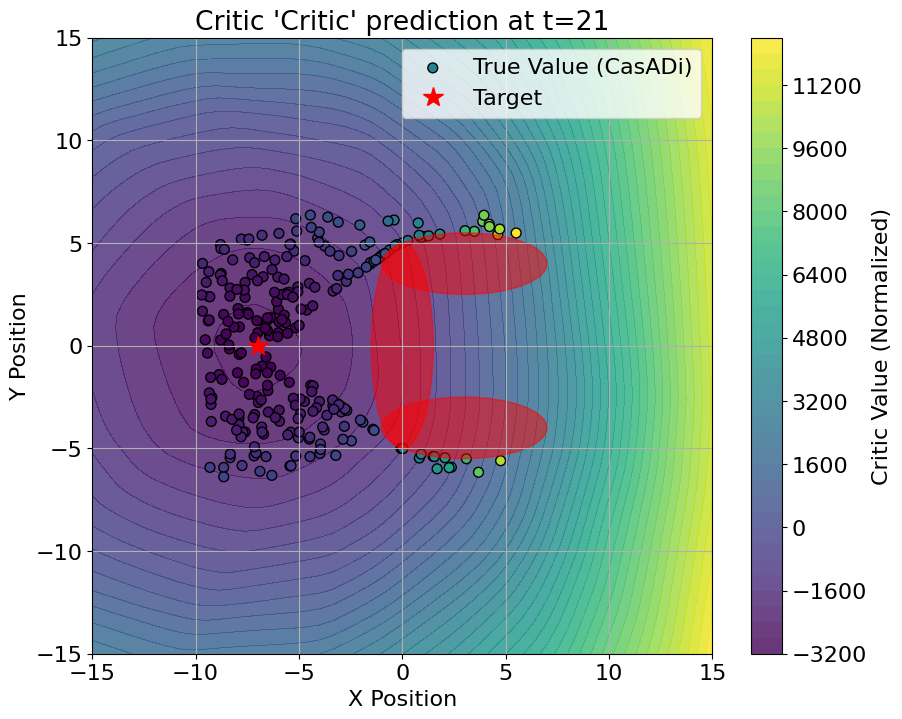

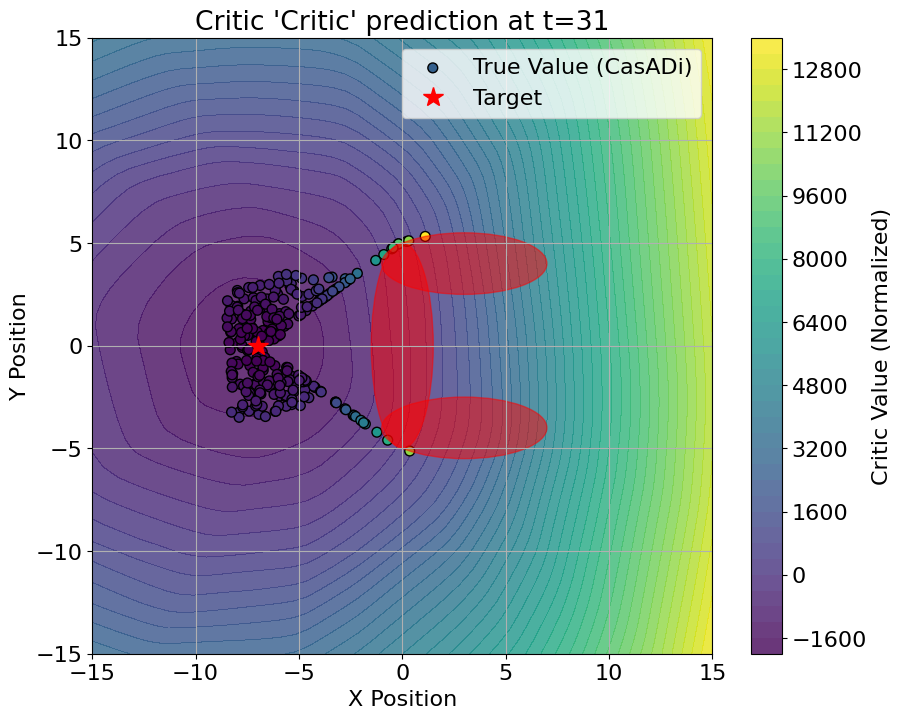

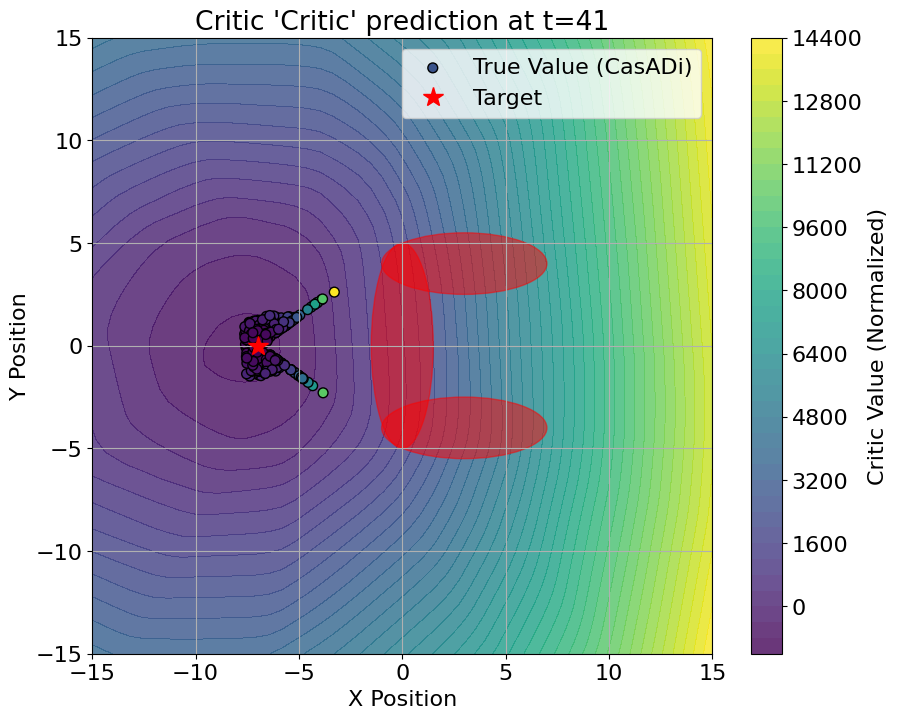

In [20]:
for t in range(1, N, 10):
    plot_critic(critic, t, show=False)

## 3a) Train the actor network

Uncomment the last line to train the unconstrained actor.

In [21]:
def plot_actor(t=0, show=True, plot_u_ocp=True):
    """
    Visualizes the Actor's policy at a specific time 't' using a Quiver plot.
    """
    # 1. Prepare the 2D grid for prediction
    t_vec = t * jnp.ones((X_grid_2d.shape[0], 1))
    X_aug_grid = jnp.hstack([X_grid_2d, t_vec])
    
    # 2. Get Actor predictions (Control inputs) across the grid
    u_pred = actor(X_aug_grid) # Expected shape: (N*N, 2)
    
    plt.figure(figsize=(10, 8))
    
    # 3. Plot obstacles for reference
    theta = np.linspace(0, 2*np.pi, 100)
    for obs in obstacle_parameters:

        x_obs = obs['x_ob'] + obs['a'] * np.cos(theta)
        y_obs = obs['y_ob'] + obs['b'] * np.sin(theta)
        plt.plot(x_obs, y_obs, 'r-', linewidth=2)
        
    # 4. Quiver Plot: Visualize control vectors as arrows
    # 'skip' prevents the plot from being too crowded
    skip = 3 
    plt.quiver(X_grid_2d[::skip, 0], X_grid_2d[::skip, 1], 
               u_pred[::skip, 0], u_pred[::skip, 1], 
               color='blue', alpha=0.6, label='Actor Policy (u)')

    # 6. Formatting
    plt.plot(target_pos[0], target_pos[1], 'r*', markersize=15, label='Target')
    plt.title(f"Actor Policy Visualization (Quiver Plot) at t={t}")
    plt.xlabel("Position x")
    plt.ylabel("Position y")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    
    if show:
        plt.show()

In [22]:
def train_actor():
    print("--- Start training the actor ---")
    start_time = timeit.default_timer()
    
    # 1. Fetch training data from the buffer (we only need states X to minimize Q)
    X_train_aug = control_buffer.getX() 
    
    # Safety check: ensure the buffer is not empty
    if X_train_aug.shape[0] == 0:
        print("WARNING: Control Buffer is empty! Skipping Actor training.")
        return
        
    # 2. Define the Q-function for diagnostics using explicit parameters
    # Note: Ensure 'dt', 'target_pos', and 'training_params' are accessible in this scope.
    @jax.jit
    def Q_func(u, x_aug):
        x_next_aug = dynamic_aug(x_aug, u)
        return cost_aug(x_aug, u) + critic(x_next_aug)[0]
    
    # Compute the gradient of Q with respect to the control input 'u' (argnums=0)
    grad_Q = jax.jit(jax.grad(Q_func, argnums=0))
    
    # 3. Execute the epoch-based training directly through the Actor class
    # We pass max_actor_iter as the total number of epochs.
    actor_loss = actor.train(
        X_train_aug, 
        n_epochs=max_actor_iter, 
        minibatch_size=minibatch_size,
        print_every=5
    ) 
    
    # 4. Diagnostic: Evaluate how well the actor minimizes the Critic's Value
    # Calculate the mean gradient norm dQ/du across the entire buffer
    U_pred = actor(X_train_aug)
    dQdu = jax.vmap(grad_Q)(U_pred, X_train_aug)
    dQdu_norm = jnp.mean(jnp.linalg.norm(dQdu, axis=1)) 
    
    print(f"Final Actor loss (Mean Q): {actor_loss:.6f} \t Final dQ/du norm: {dQdu_norm:.6f}")

            
    duration = timeit.default_timer() - start_time
    print(f"--- Finished training actor ({duration:.3f} s) ---")

# Run the training  UNCOMMENT TO TRAIN TH UNCONSTRAINED ACTOR NETWORK
#train_actor()  

In [23]:
#for t in range(1, N, 25):
    #plot_actor(t, show=True, plot_u_ocp=True)

## 3b) Train the constrained actor network

In [24]:
def plot_constr_actor(t=0, show=True, plot_u_ocp=True):
    """
    Visualizes the Actor's policy at a specific time 't' using a Quiver plot.
    """
    # 1. Prepare the 2D grid for prediction
    t_vec = t * jnp.ones((X_grid_2d.shape[0], 1))
    X_aug_grid = jnp.hstack([X_grid_2d, t_vec])
    
    # 2. Get Actor predictions (Control inputs) across the grid
    u_pred = cons_actor(X_aug_grid) # Expected shape: (N*N, 2)
    
    plt.figure(figsize=(10, 8))
    
    # 3. Plot obstacles for reference
    theta = np.linspace(0, 2*np.pi, 100)
    for obs in obstacle_parameters:

        x_obs = obs['x_ob'] + obs['a'] * np.cos(theta)
        y_obs = obs['y_ob'] + obs['b'] * np.sin(theta)
        plt.plot(x_obs, y_obs, 'r-', linewidth=2)
        
    # 4. Quiver Plot: Visualize control vectors as arrows
    # 'skip' prevents the plot from being too crowded
    skip = 3 
    plt.quiver(X_grid_2d[::skip, 0], X_grid_2d[::skip, 1], 
               u_pred[::skip, 0], u_pred[::skip, 1], 
               color='blue', alpha=0.6, label='Actor Policy (u)')

    # 6. Formatting
    plt.plot(target_pos[0], target_pos[1], 'r*', markersize=15, label='Target')
    plt.title(f"Actor Policy Visualization (Quiver Plot) at t={t}")
    plt.xlabel("Position x")
    plt.ylabel("Position y")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    
    if show:
        plt.show()

In [25]:
def train_constr_actor():
    print("--- Start training the constrained actor ---")
    start_time = timeit.default_timer()
    
    # 1. Fetch training data from the buffer
    X_train_aug = control_buffer.getX() 
    
    # Safety check: ensure the buffer is not empty
    if X_train_aug.shape[0] == 0:
        print("WARNING: Control Buffer is empty! Skipping Actor training.")
        return
        
    # 2. Define the Q-function for diagnostics using the actor's internal functions
    @jax.jit
    def Q_func(u, x_aug):
        # Usiamo i metodi dell'attore per coerenza matematica
        x_next_aug = cons_actor.dynamic(x_aug, u)
        return cons_actor.cost(x_aug, u) + critic(x_next_aug)[0]
    
    # Compute the gradient of Q and vmap it for batch processing
    grad_Q = jax.jit(jax.grad(Q_func, argnums=0))
    grad_Q_vmap = jax.jit(jax.vmap(grad_Q))
    
    # 3. Execute the epoch-based training directly through the Actor class
    actor_loss, final_lam, final_rho = cons_actor.train(
        X_train_aug, 
        n_epochs=max_actor_iter, 
        minibatch_size=minibatch_size,
        print_every=5,
        grad_Q_vmap=grad_Q_vmap  
    ) 
    
    # 4. Diagnostic: Evaluate how well the actor minimizes the Critic's Value
    U_pred = cons_actor(X_train_aug)
    dQdu_final = grad_Q_vmap(U_pred, X_train_aug)
    dQdu_norm_final = jnp.mean(jnp.linalg.norm(dQdu_final, axis=1)) 
    
    print(f"Final Constrained Actor loss (Mean Q): {actor_loss:.6f} \t Final dQ/du norm: {dQdu_norm_final:.6f}")
    print(f"Final ALM Parameters -> Lambda: {final_lam} | Rho: {final_rho}")
            
    duration = timeit.default_timer() - start_time
    print(f"--- Finished training constrained actor ({duration:.3f} s) ---")

# Run the training
print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_constr_actor()


--- CACTO Iteration 0 ---

--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1472.3947 | Max Viol: 0.00691 | Rho: 1200.0 | dQ/du norm: 12.875690
Epoch 5/50 | Mean Q+ALM: -1510.7401 | Max Viol: 0.00102 | Rho: 2488.3 | dQ/du norm: 3.120633
Epoch 10/50 | Mean Q+ALM: -1510.4547 | Max Viol: 0.00028 | Rho: 6191.7 | dQ/du norm: 3.022290
Epoch 15/50 | Mean Q+ALM: -1509.9485 | Max Viol: 0.00065 | Rho: 15407.0 | dQ/du norm: 3.480600
Epoch 20/50 | Mean Q+ALM: -1509.9579 | Max Viol: 0.00031 | Rho: 38337.6 | dQ/du norm: 3.576293
Epoch 25/50 | Mean Q+ALM: -1509.4865 | Max Viol: 0.00013 | Rho: 95396.2 | dQ/du norm: 3.695769
Epoch 30/50 | Mean Q+ALM: -1508.6810 | Max Viol: 0.00009 | Rho: 197813.6 | dQ/du norm: 3.789513
Epoch 35/50 | Mean Q+ALM: -1508.3350 | Max Viol: 0.00012 | Rho: 200000.0 | dQ/du norm: 4.058283
Epoch 40/50 | Mean Q+ALM: -1509.4939 | Max Viol: 0.00012 | Rho: 200000.0 | dQ/du norm: 3.795525
Epoch 45/50 | M

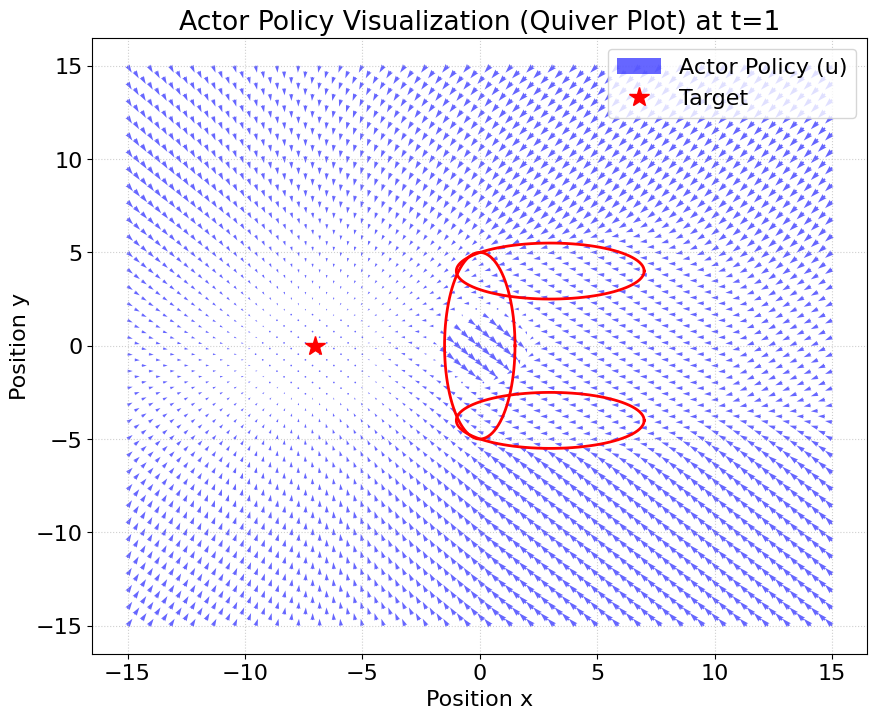

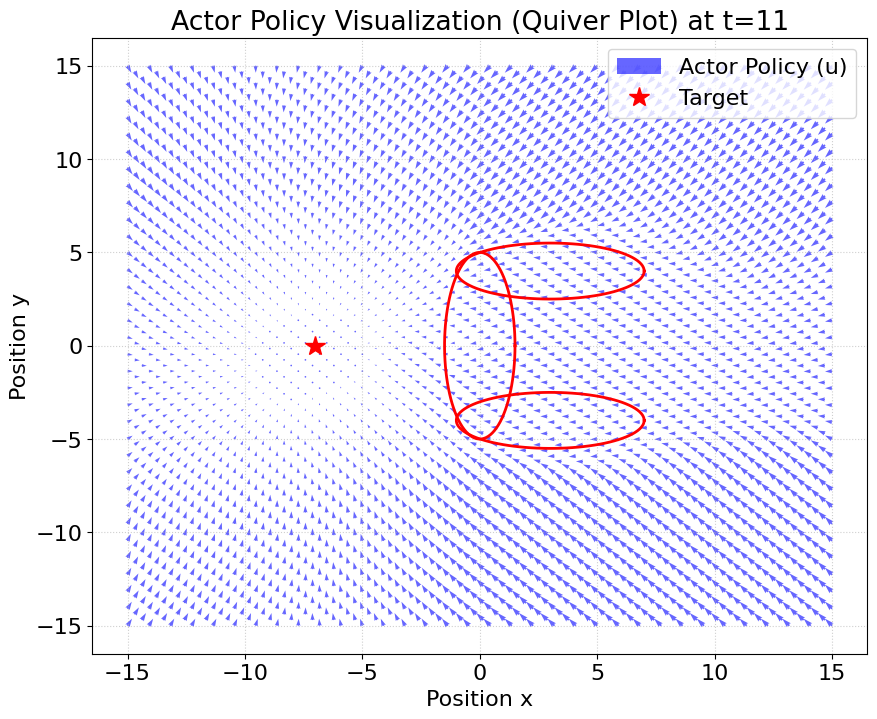

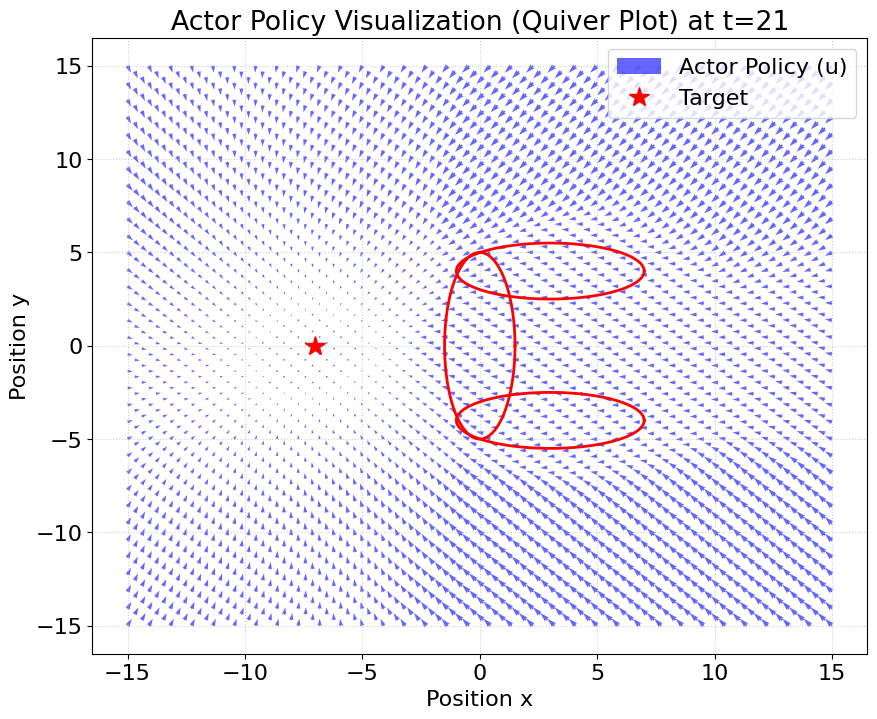

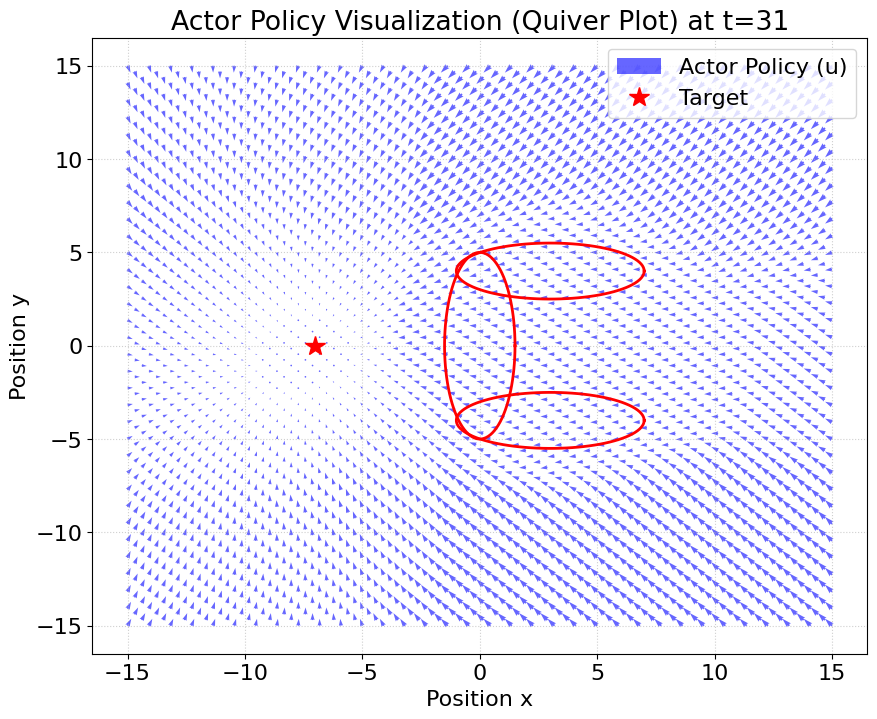

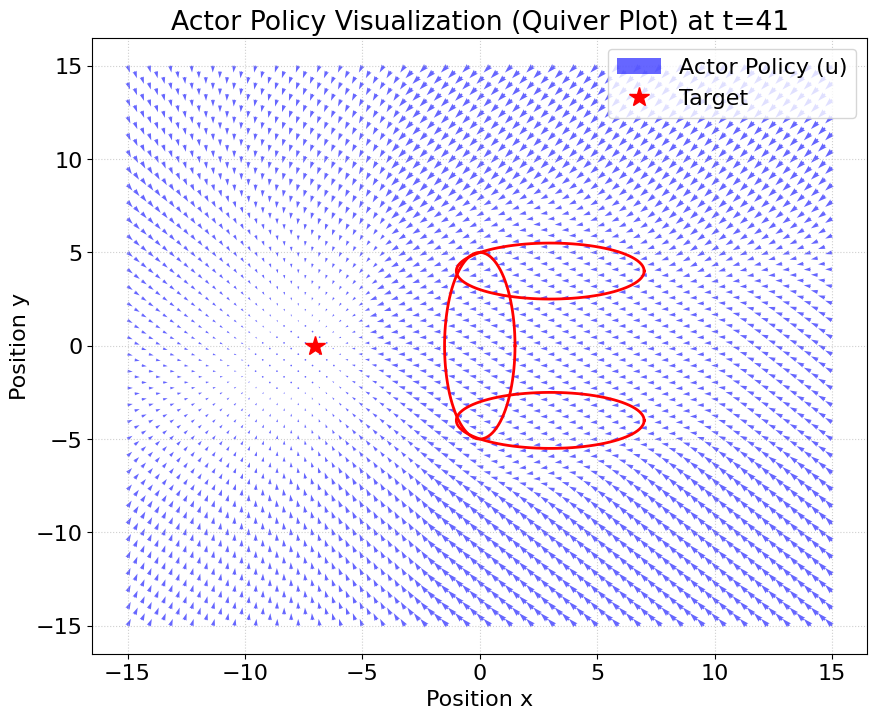

In [26]:
for t in range(1, N, 10):
    plot_constr_actor(t, show=True, plot_u_ocp=True)

## 4) Evaluate TO with constrained actor's initial guess

First compute the initial guesses by getting the cotnrols form the constrined actor and the corresponding states from the dynamics.

In [27]:
def check_2d_constraints(X_traj, obstacles_params, tol=1e-4):
    """
    Helper function to check if a given trajectory violates the elliptical constraints defined by the obstacles.
    Returns: feasible (bool), max_violation (float)
    """
    max_viol = 0.0
    
    # Evaluate every point in the trajectory
    for state in X_traj:
        # Get the g(x) values for all the trajectory points with respect to all obstacles
        g_vals = elliptical_constraints(state, obstacles_params, backend='numpy')
        
        for g in g_vals:
            # If g < 0, we are inside the ellipse (violation)
            viol = max(0.0, -g) 
            if viol > max_viol:
                max_viol = viol
            
    feasible = max_viol <= tol
    return feasible, max_viol

Plot the constrained actor rollouts to see the resulting trajectories.

Actor Only -> Feasible: 9/24 | Violating: 15/24
Actor Only -> Avg. max violation: 0.5218


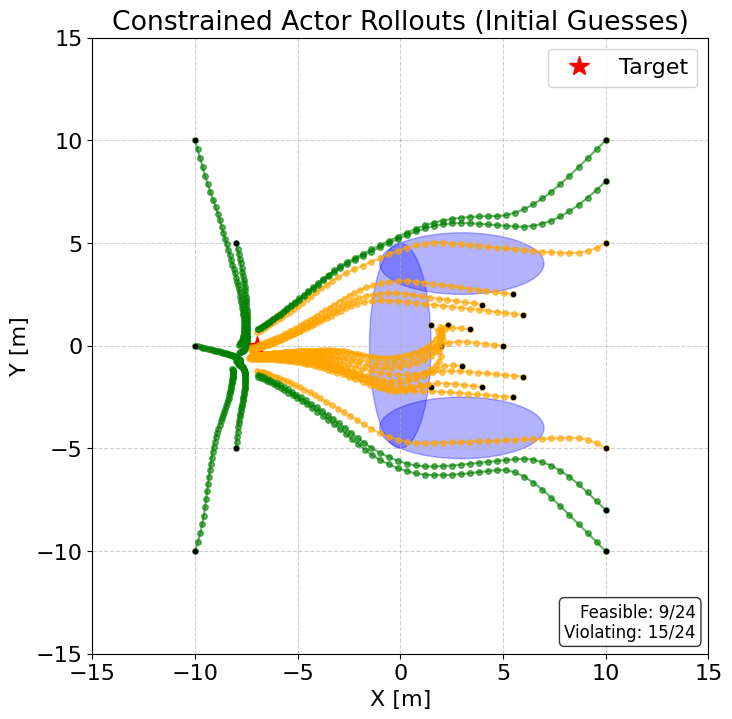

In [28]:
def plot_cons_actor_rollouts():
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 1. Draw obstacles and target using YOUR function!
    plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

    n_total = len(X_init_grid)
    n_feasible, n_violating = 0, 0
    maxv_list = []

    # Array of initial times (all zeros since we are starting at t=0 for all trajectories)
    t0_grid = np.zeros(n_total)
    
    # Compute the initial guesses for all trajectories in a batch using the constrained actor
    X_guess_list, _, _ = compute_initial_guess(X_init_grid, t0_grid, N, n_x, n_u, cons_actor)


    # Check constraints and plot each trajectory
    for i, X_guess in enumerate(X_guess_list):
        x_init = X_init_grid[i] 
        
        # Check 2D constraints
        feasible, maxv = check_2d_constraints(X_guess, obstacle_parameters)
        n_feasible += int(feasible)
        n_violating += int(not feasible)
        maxv_list.append(maxv)

        color = 'green' if feasible else 'orange'
        ax.plot(X_guess[:, 0], X_guess[:, 1], color=color, alpha=0.6, linewidth=1.5, marker='o', markersize=4)
        ax.plot(x_init[0], x_init[1], 'ko', markersize=3) # Start point

    print(f"Actor Only -> Feasible: {n_feasible}/{n_total} | Violating: {n_violating}/{n_total}")
    print(f"Actor Only -> Avg. max violation: {np.mean(maxv_list):.4f}")

    # Add text box with stats
    ax.text(0.98, 0.02, f"Feasible: {n_feasible}/{n_total}\nViolating: {n_violating}/{n_total}",
            transform=ax.transAxes, fontsize=12, ha="right", va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

    ax.set_title("Constrained Actor Rollouts (Initial Guesses)")
    plt.show()
    
plot_cons_actor_rollouts()

Now solve the TO with the consrained actor trajectoris for warm start.
Uses as initial states the ones defined at the beginning (variable `init_pos`).

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=9: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. 

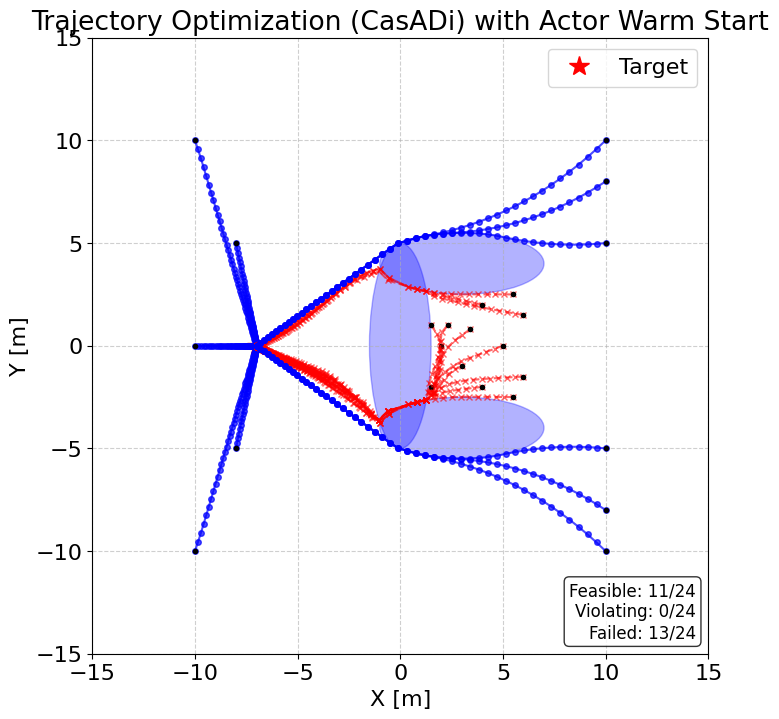

In [29]:
def evaluate_TO_w_cons_warm_start():
    '''
    Evaluates the performance of the trajectory optimization solver when warm-started with the constrained 
    actor's rollouts.
    For each initial state in the grid, it computes the initial guess using the constrained actor, solves the OCP, 
    and checks for constraint violations.
    It also visualizes the resulting trajectories and prints summary statistics about feasibility and solver success.
    '''

    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 1. Draw obstacles and target 
    plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

    # Variables initialization
    V_TO = np.full(len(X_init_grid), np.nan)
    n_total = len(X_init_grid)
    n_feasible, n_violating, n_failed = 0, 0, 0
    maxv_list = []
    all_cons_x_trajs = []

    start_time = timeit.default_timer()
    
    # Compute initial guesses for warm start in batch using the constrained actor
    print("Computing initial guesses in batch...")
    t0_grid = np.zeros(n_total)
    X_guess_batch, U_guess_batch, _ = compute_initial_guess(
        X_init_grid, t0_grid, N, n_x, n_u, cons_actor
    )

    # Solve OCP for each initial state using the corresponding warm start and check constraints
    for i, x_init in enumerate(X_init_grid):
        
        X_guess = np.array(X_guess_batch[i])
        U_guess = np.array(U_guess_batch[i])

        try:
            sol = ocp.solve(x_init, N, X_guess, U_guess)
        except Exception as e:
            n_failed += 1
            print(f"Skip i={i}: OCP failed | Error: {str(e).splitlines()[-1]}")
            
            x_traj_failed = ocp.opti.debug.value(ocp.x).T
                
            # Plot the failed trajectory in red dashed line with 'x' markers
            ax.plot(x_traj_failed[:, 0], x_traj_failed[:, 1], color='red', linestyle='--', alpha=0.6, linewidth=1.5, marker='x', markersize=4)
            ax.plot(x_init[0], x_init[1], 'ko', markersize=3)
            continue

        V_TO[i] = sol.value(ocp.cost)
        x_traj_opt = sol.value(ocp.x).T 
        all_cons_x_trajs.append(x_traj_opt)

        feasible, maxv = check_2d_constraints(x_traj_opt, obstacle_parameters)
        n_feasible += int(feasible)
        n_violating += int(not feasible)
        maxv_list.append(maxv)

        color = 'blue' if feasible else 'red'
        ax.plot(x_traj_opt[:, 0], x_traj_opt[:, 1], color=color, alpha=0.7, linewidth=1.5, marker='o', markersize=4)
        ax.plot(x_init[0], x_init[1], 'ko', markersize=3)

    print(f"TO + Warm Start -> Time: {timeit.default_timer() - start_time:.3f} s")
    print(f"TO + Warm Start -> Feasible: {n_feasible}/{n_total} | Failed: {n_failed}/{n_total}")
    

    ax.text(0.98, 0.02, f"Feasible: {n_feasible}/{n_total}\nViolating: {n_violating}/{n_total}\nFailed: {n_failed}/{n_total}",
            transform=ax.transAxes, fontsize=12, ha="right", va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

    ax.set_title("Trajectory Optimization (CasADi) with Actor Warm Start")
    plt.show()

    return V_TO, all_cons_x_trajs

# --- RUN ---
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

## Re-iterate the procedure

Now we repeat the stesp 1), 2), 3b) and 4) unitll we get good results.

In [30]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
iter_count += 1
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)


--- CACTO Iteration 1 ---

Start solving 300 TO problems
Computing warm start guesses via Actor...


Risoluzione OCP:   0%|          | 1/300 [00:00<02:07,  2.34traj/s]

i=0, X=[11.26191696 -2.62065266]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:   8%|▊         | 23/300 [00:06<01:32,  2.98traj/s]

i=22, X=[11.0187738  1.3430866]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=284, X=[ 4.46387123 -0.18589639]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  98%|█████████▊| 293/300 [01:25<00:02,  2.73traj/s]

i=292, X=[11.7165258  -0.41479193]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [01:27<00:00,  3.44traj/s]


--- Finished ---
Successfully solved: 259 / 300
States Buffer size: (12950, 3) samples
Time taken: 89.896 s



--- CACTO Iteration 1 ---

--- Start training critic ---
Epoch 1/50 | MSE: 3061.0818 | RMSE: 55.3270
Epoch 5/50 | MSE: 3121.0786 | RMSE: 55.8666
Epoch 10/50 | MSE: 2183.0967 | RMSE: 46.7236
Epoch 15/50 | MSE: 402.6860 | RMSE: 20.0670
Epoch 20/50 | MSE: 1129.9020 | RMSE: 33.6140
Epoch 25/50 | MSE: 2160.0164 | RMSE: 46.4760
Epoch 30/50 | MSE: 1587.3253 | RMSE: 39.8413
Epoch 35/50 | MSE: 1016.3312 | RMSE: 31.8799
Epoch 40/50 | MSE: 1409.0819 | RMSE: 37.5377
Epoch 45/50 | MSE: 1167.1991 | RMSE: 34.1643
Epoch 50/50 | MSE: 1215.6735 | RMSE: 34.8665
Final Critic MSE: 1215.67
Final Critic RMSE: 34.87
--- Critic training has finished ---


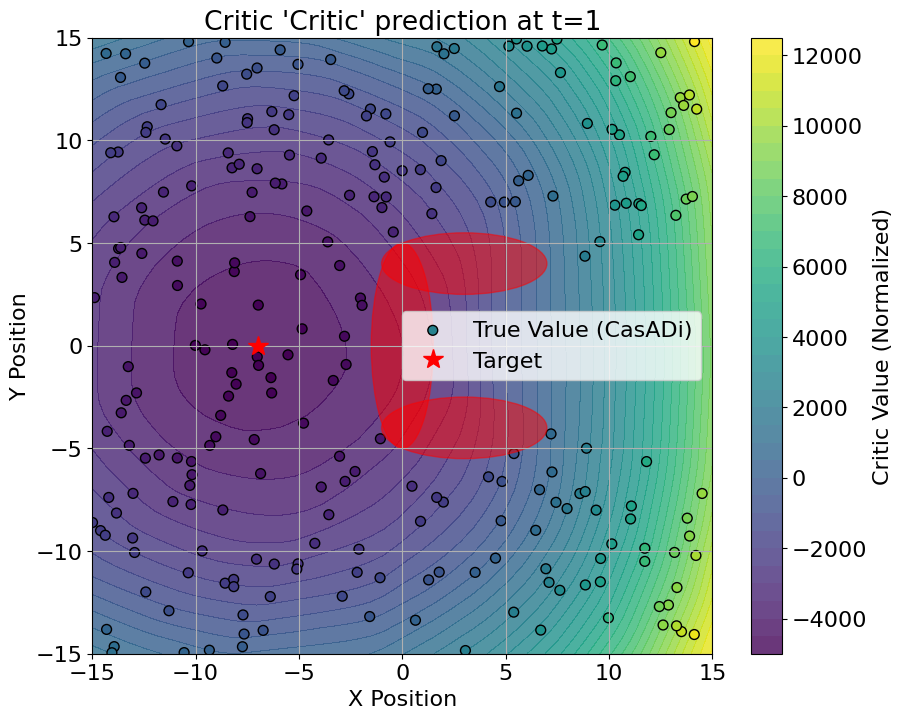

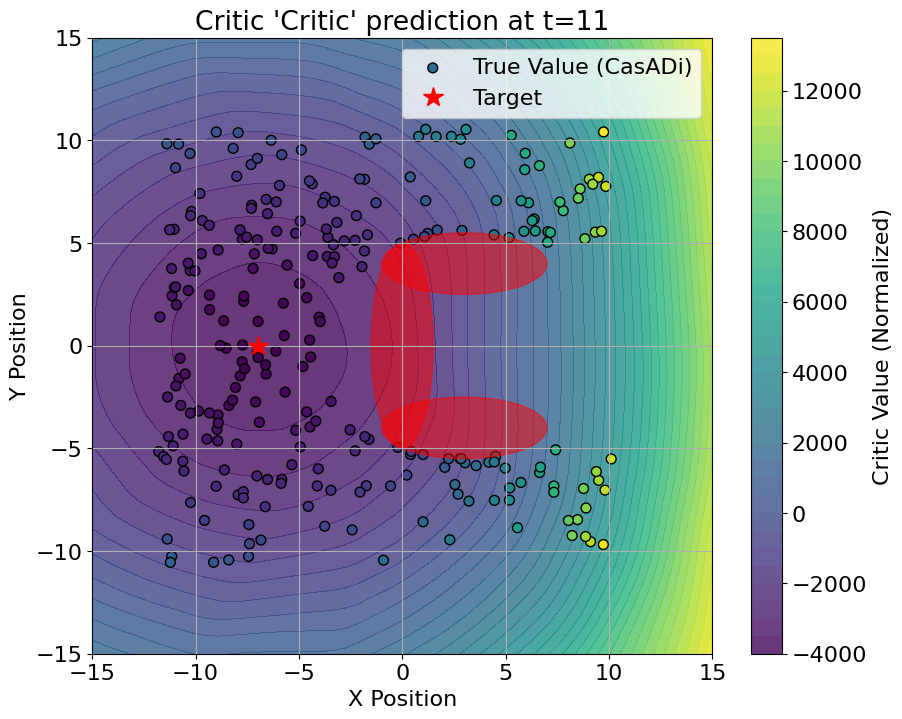

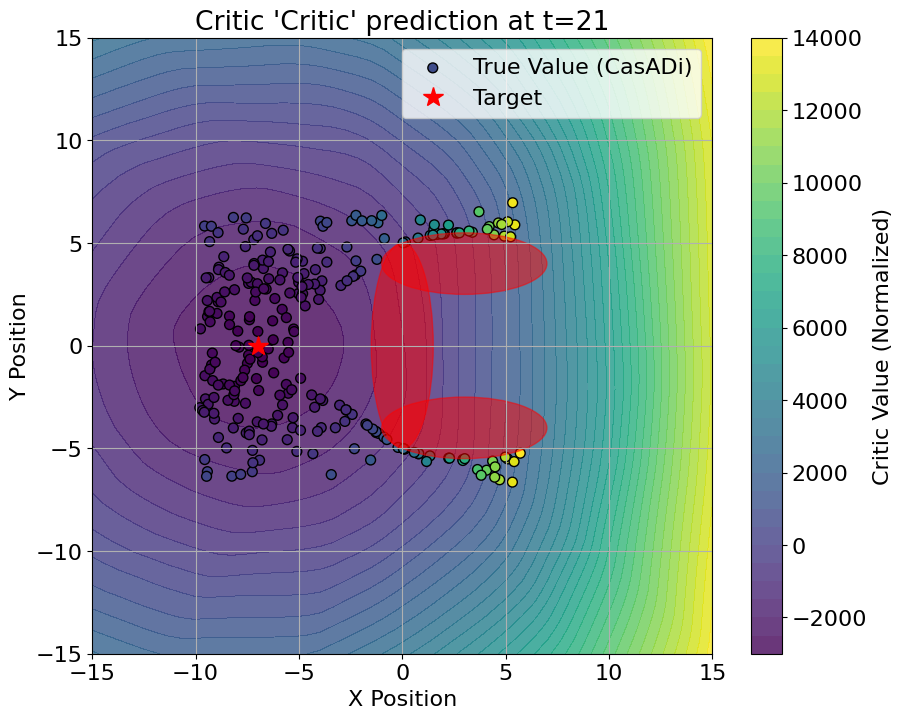

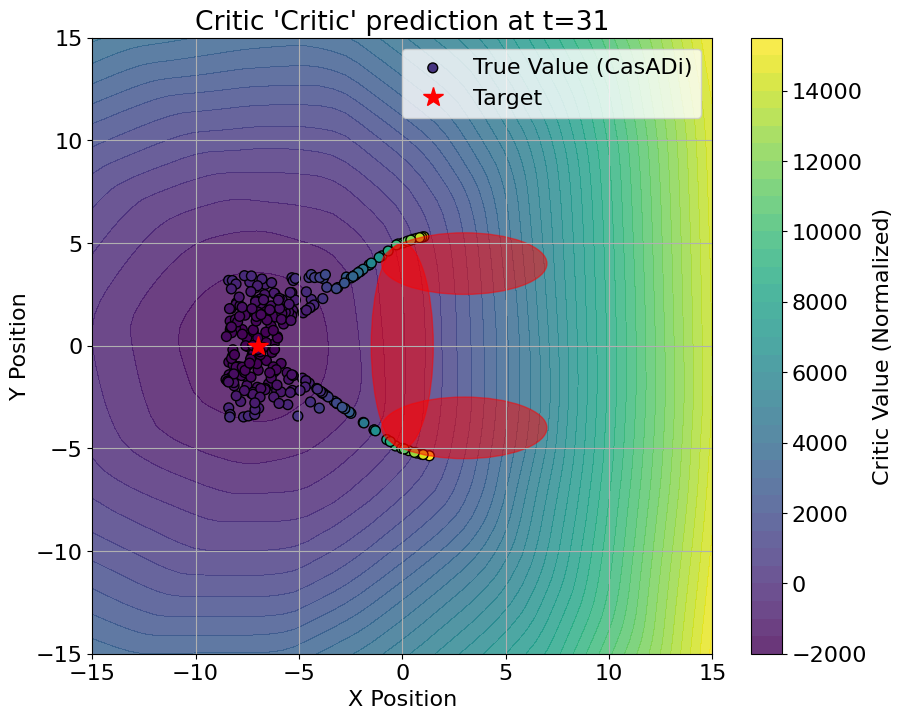

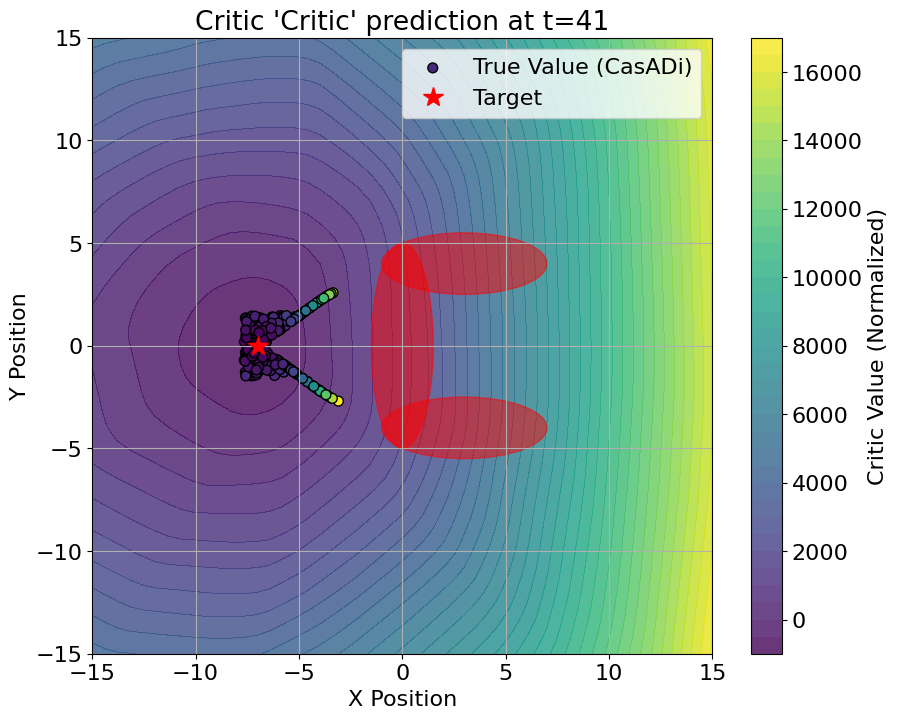

In [31]:
# Train the critic again with the new data in the buffer 
print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_critic()

for t in range(1, N, 10):
  plot_critic(critic, t, show=False)


--- CACTO Iteration 1 ---

--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1191.2859 | Max Viol: 0.00168 | Rho: 1200.0 | dQ/du norm: 4.690570
Epoch 5/50 | Mean Q+ALM: -1191.9738 | Max Viol: 0.00071 | Rho: 2488.3 | dQ/du norm: 3.826495
Epoch 10/50 | Mean Q+ALM: -1191.2762 | Max Viol: 0.00058 | Rho: 6191.7 | dQ/du norm: 4.502461
Epoch 15/50 | Mean Q+ALM: -1190.9102 | Max Viol: 0.00037 | Rho: 15407.0 | dQ/du norm: 4.565854
Epoch 20/50 | Mean Q+ALM: -1191.2279 | Max Viol: 0.00029 | Rho: 31948.0 | dQ/du norm: 4.290694
Epoch 25/50 | Mean Q+ALM: -1188.2885 | Max Viol: 0.00002 | Rho: 66247.4 | dQ/du norm: 6.281432
Epoch 30/50 | Mean Q+ALM: -1189.8906 | Max Viol: 0.00038 | Rho: 164844.7 | dQ/du norm: 4.040393
Epoch 35/50 | Mean Q+ALM: -1190.4103 | Max Viol: 0.00012 | Rho: 200000.0 | dQ/du norm: 4.337960
Epoch 40/50 | Mean Q+ALM: -1190.4584 | Max Viol: 0.00001 | Rho: 200000.0 | dQ/du norm: 4.681671
Epoch 45/50 | Me

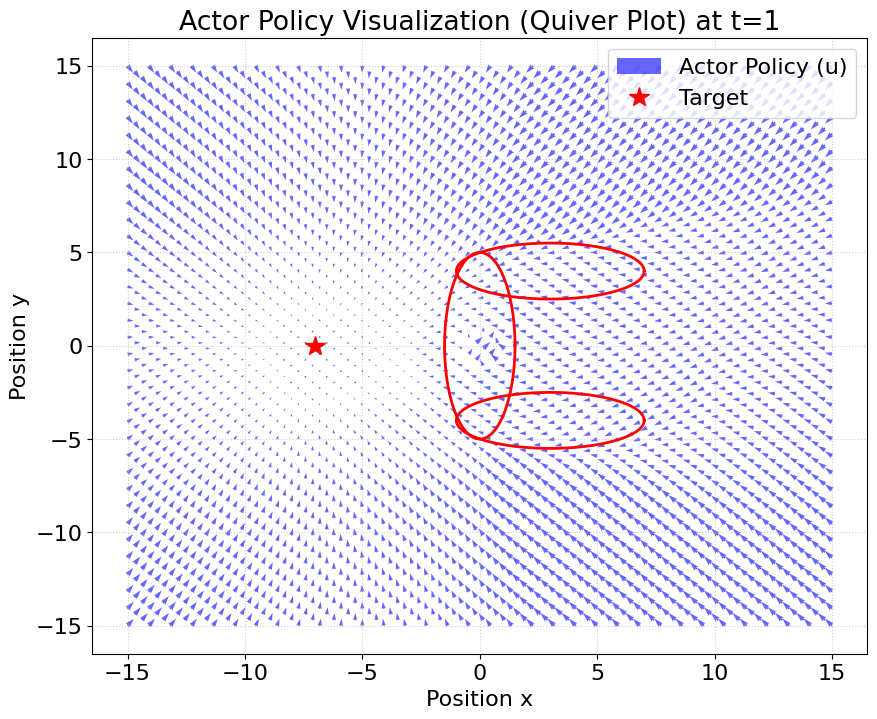

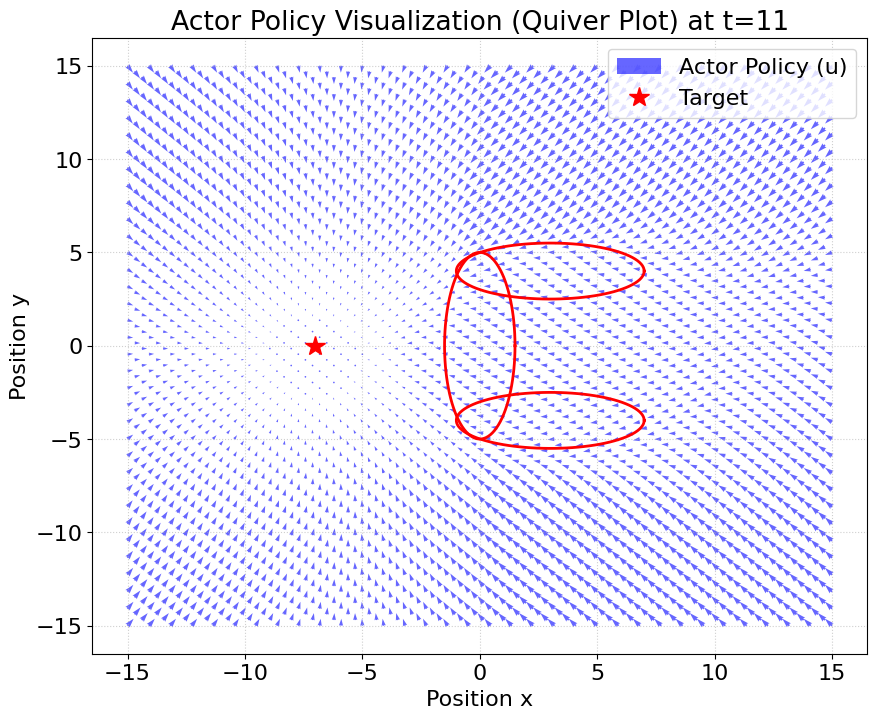

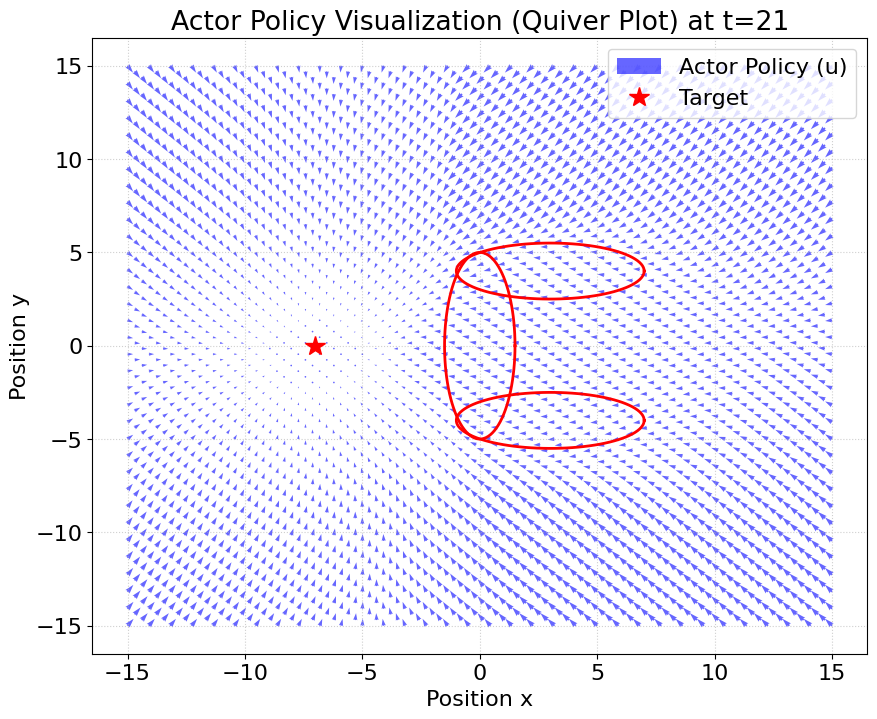

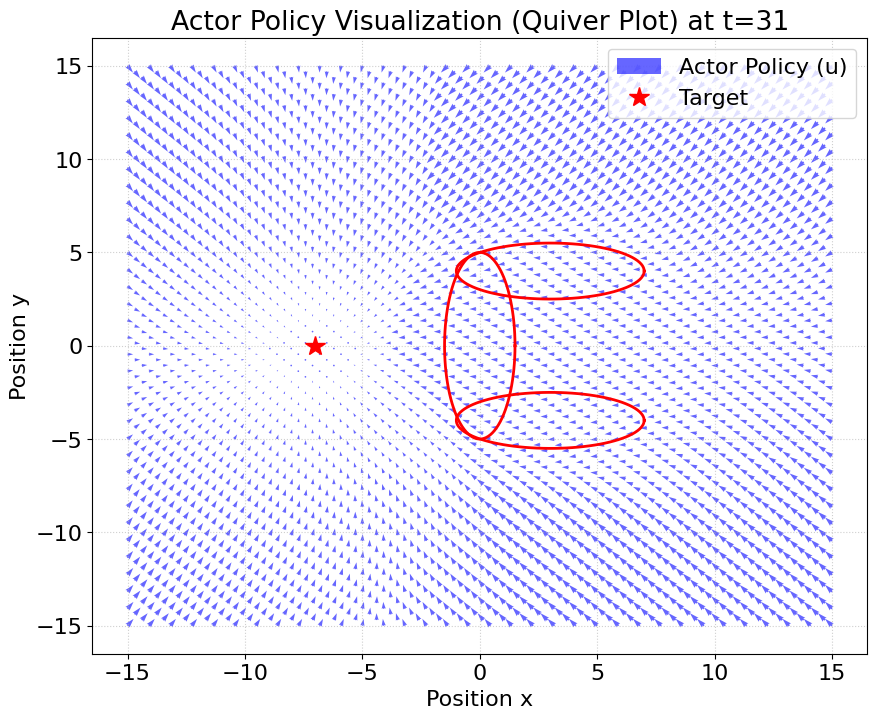

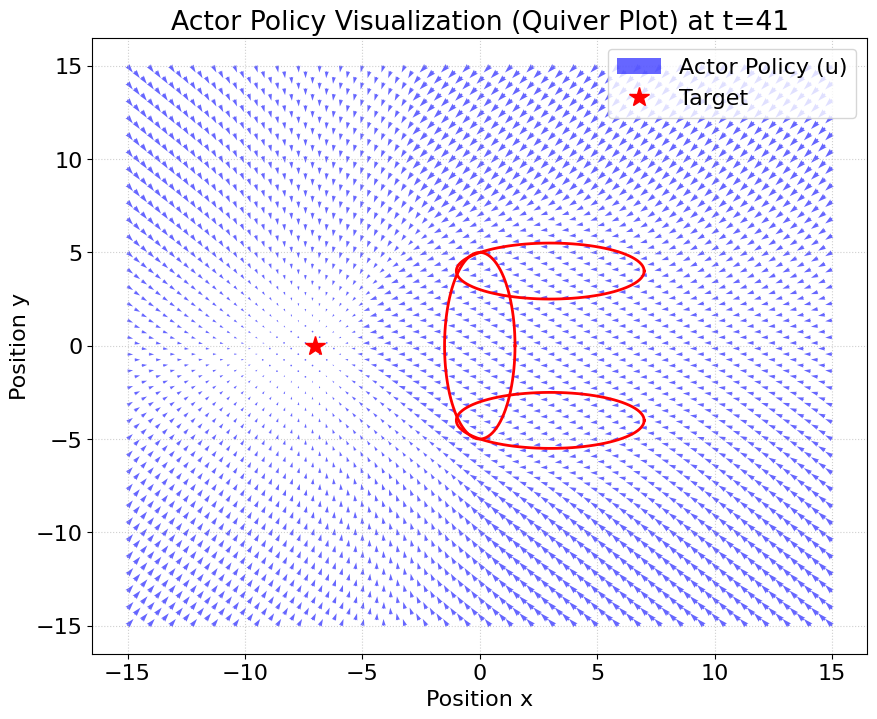

In [32]:
# Train the constrained actor again with the new critic

# Augmented Lagrangian parameters reset 
cons_actor.rho_x = 1000.0   
cons_actor.lambda_x = jnp.zeros_like(cons_actor.lambda_x) 

print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_constr_actor()

for t in range(1, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 8/24 | Violating: 16/24
Actor Only -> Avg. max violation: 0.5013


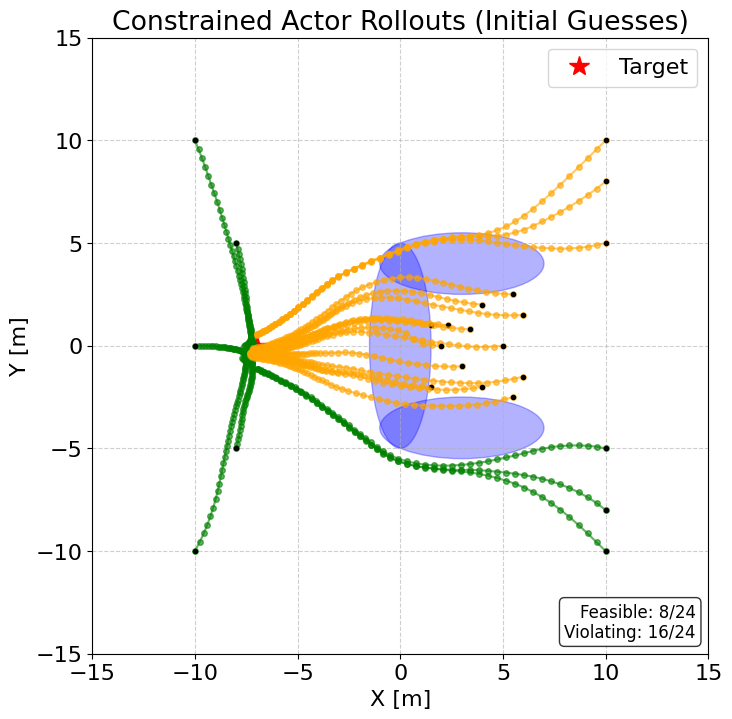

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=9: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. 

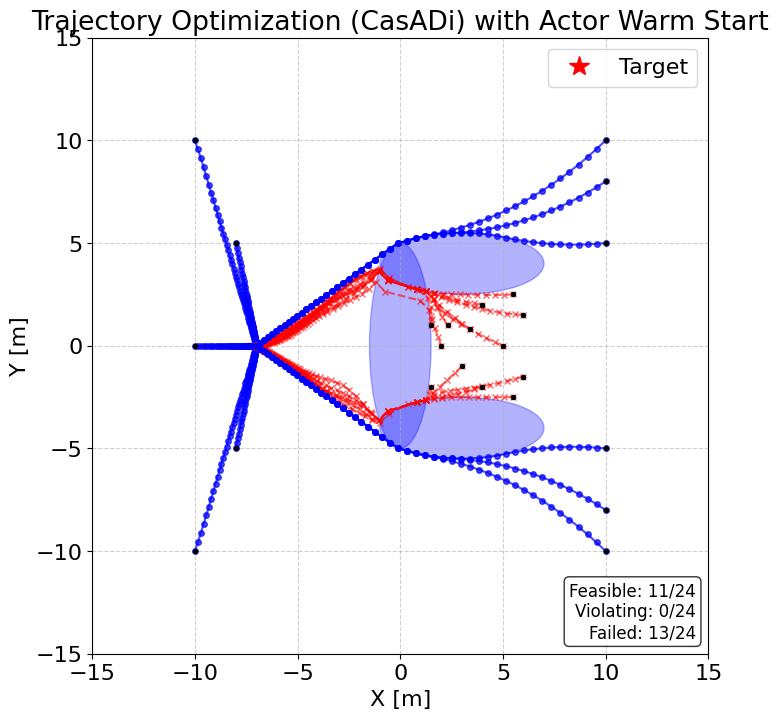

In [33]:
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

In [34]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
iter_count += 1
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)


--- CACTO Iteration 2 ---

Start solving 300 TO problems
Computing warm start guesses via Actor...


Risoluzione OCP:   7%|▋         | 21/300 [00:06<02:09,  2.16traj/s]

i=20, X=[14.07724854 -0.12247078]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  12%|█▏        | 37/300 [00:12<01:55,  2.27traj/s]

i=36, X=[14.13316142 -0.13329162]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=285, X=[ 14.60094565 -13.52975091]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  99%|█████████▊| 296/300 [01:35<00:01,  3.14traj/s]

i=295, X=[10.95791288 -1.87596472]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [01:36<00:00,  3.11traj/s]


--- Finished ---
Successfully solved: 270 / 300
States Buffer size: (13500, 3) samples
Time taken: 98.421 s



--- CACTO Iteration 2 ---

--- Start training critic ---
Epoch 1/50 | MSE: 1225.2004 | RMSE: 35.0029
Epoch 5/50 | MSE: 506.1692 | RMSE: 22.4982
Epoch 10/50 | MSE: 617.5770 | RMSE: 24.8511
Epoch 15/50 | MSE: 1080.9965 | RMSE: 32.8785
Epoch 20/50 | MSE: 903.3068 | RMSE: 30.0551
Epoch 25/50 | MSE: 347.0783 | RMSE: 18.6300
Epoch 30/50 | MSE: 502.6327 | RMSE: 22.4195
Epoch 35/50 | MSE: 319.1000 | RMSE: 17.8634
Epoch 40/50 | MSE: 338.9236 | RMSE: 18.4099
Epoch 45/50 | MSE: 1106.4517 | RMSE: 33.2634
Epoch 50/50 | MSE: 648.6830 | RMSE: 25.4693
Final Critic MSE: 648.68
Final Critic RMSE: 25.47
--- Critic training has finished ---


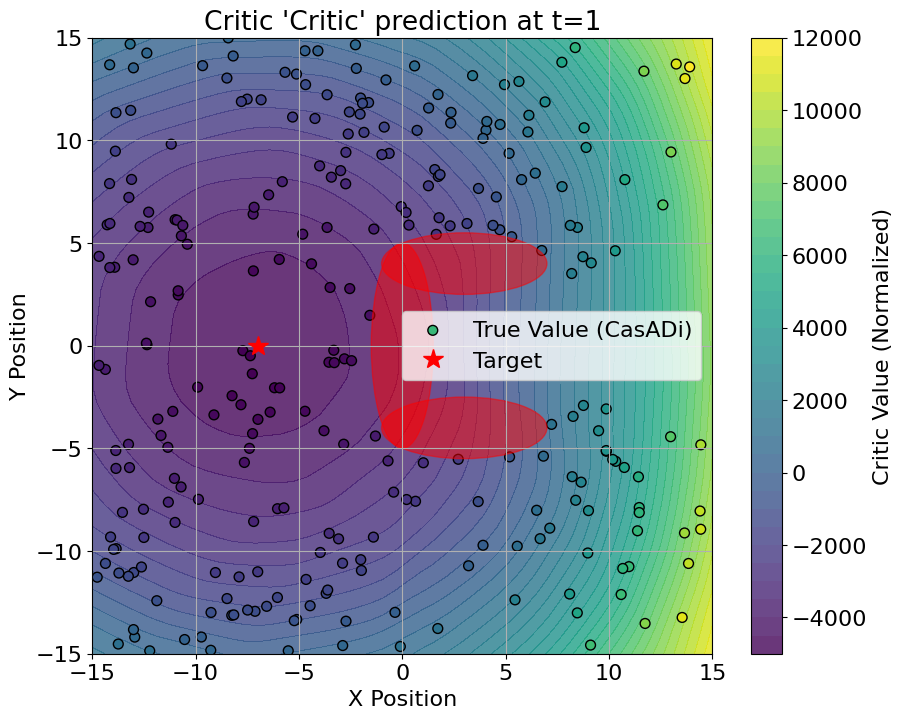

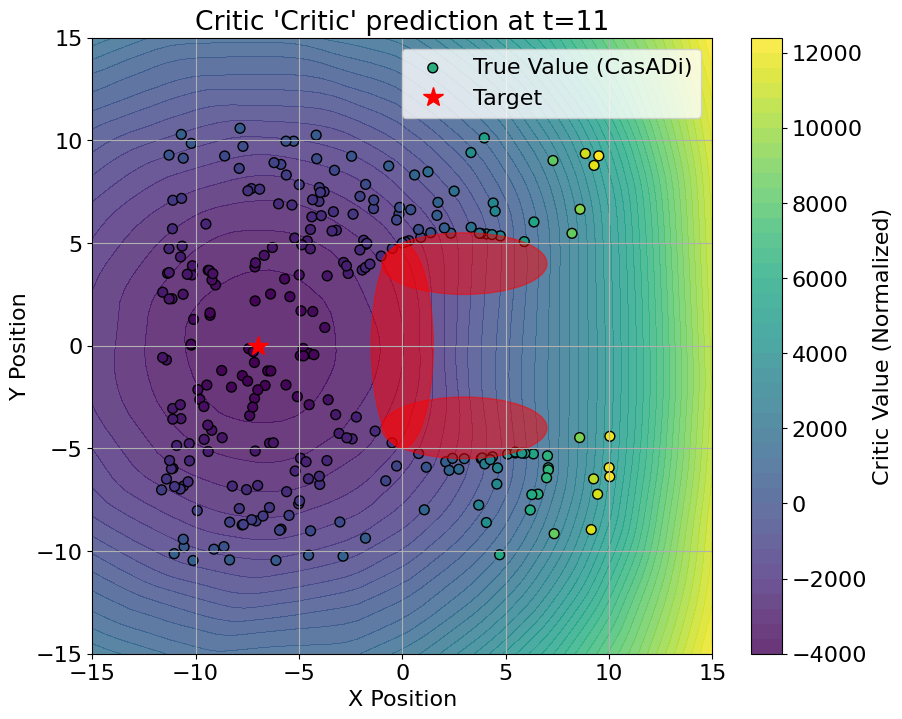

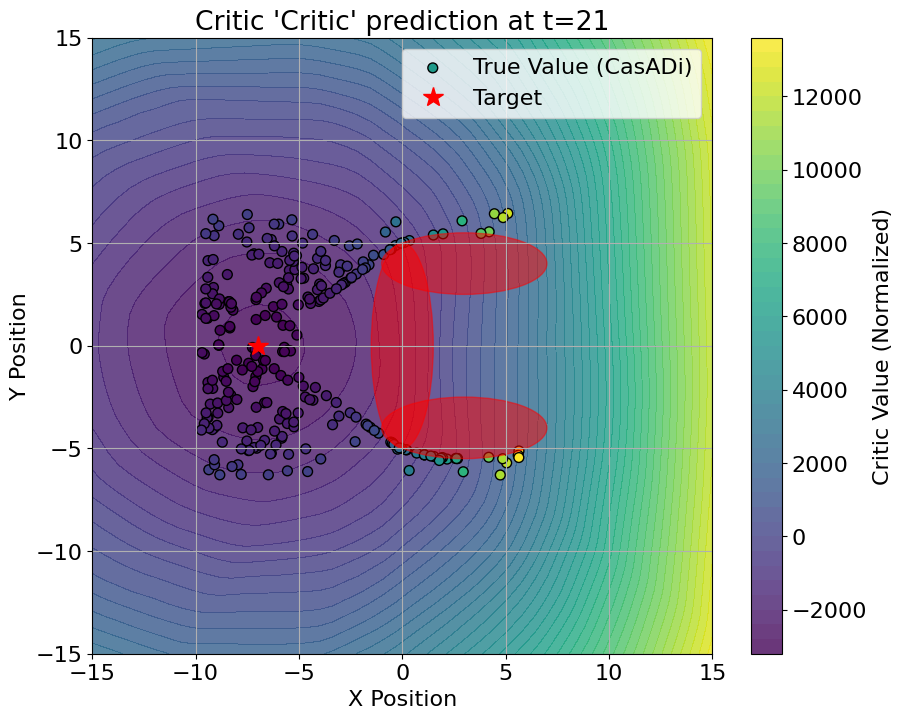

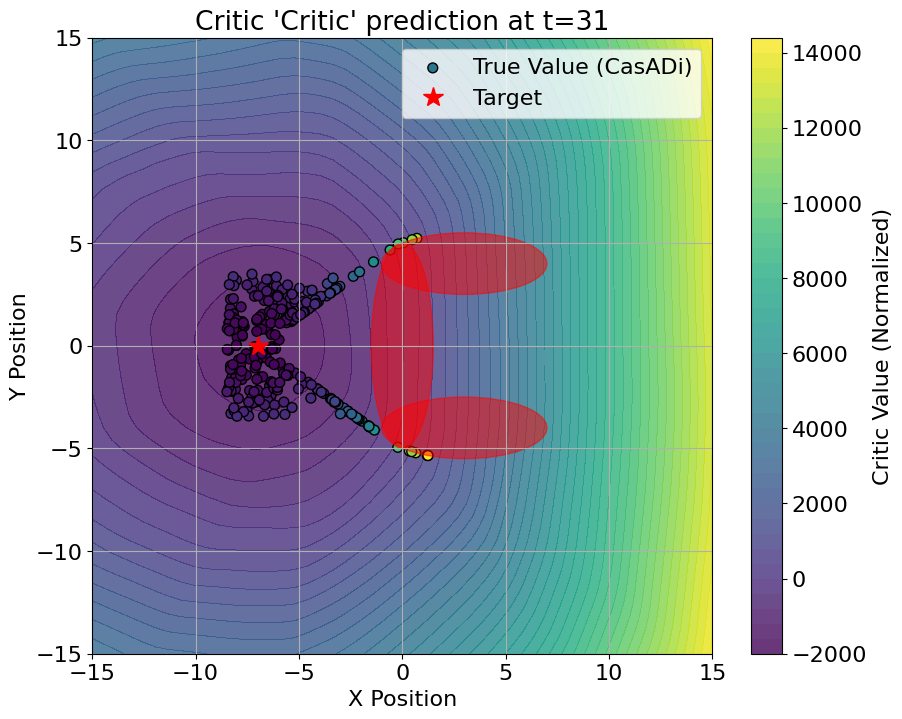

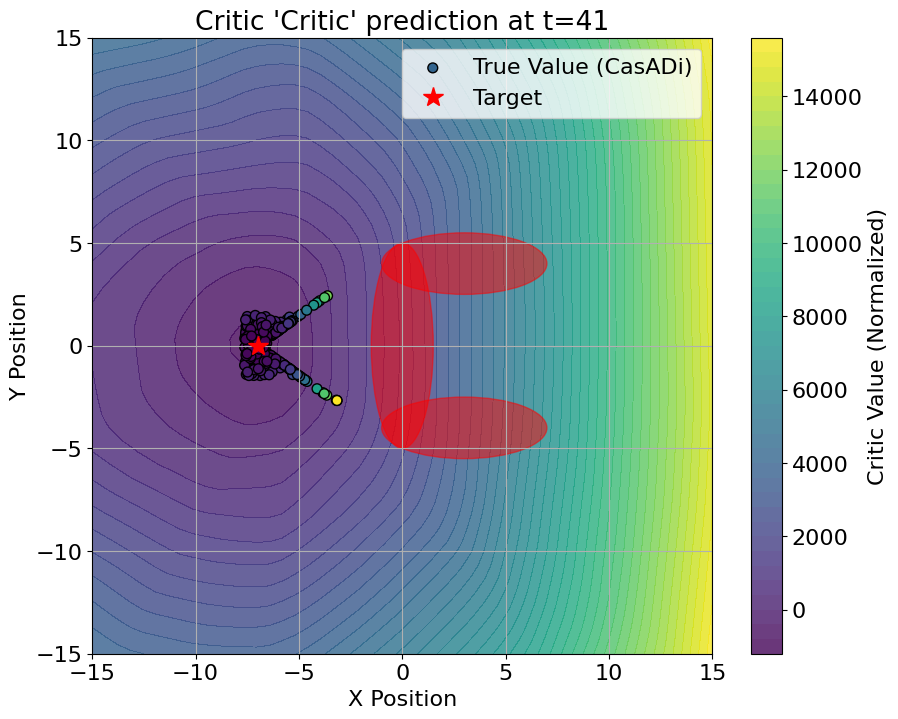

In [35]:
# Train the critic again with the new data in the buffer 
print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_critic()

for t in range(1, N, 10):
  plot_critic(critic, t, show=False)


--- CACTO Iteration 2 ---

--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1426.0638 | Max Viol: 0.00128 | Rho: 1200.0 | dQ/du norm: 3.096319
Epoch 5/50 | Mean Q+ALM: -1426.2549 | Max Viol: 0.00101 | Rho: 2488.3 | dQ/du norm: 2.884437
Epoch 10/50 | Mean Q+ALM: -1425.9761 | Max Viol: 0.00032 | Rho: 6191.7 | dQ/du norm: 2.926158
Epoch 15/50 | Mean Q+ALM: -1425.1764 | Max Viol: 0.00119 | Rho: 15407.0 | dQ/du norm: 3.216074
Epoch 20/50 | Mean Q+ALM: -1425.4480 | Max Viol: 0.00018 | Rho: 38337.6 | dQ/du norm: 3.328631
Epoch 25/50 | Mean Q+ALM: -1425.4325 | Max Viol: 0.00008 | Rho: 66247.4 | dQ/du norm: 3.434307
Epoch 30/50 | Mean Q+ALM: -1425.3923 | Max Viol: 0.00007 | Rho: 137370.6 | dQ/du norm: 3.122960
Epoch 35/50 | Mean Q+ALM: -1425.3514 | Max Viol: 0.00003 | Rho: 137370.6 | dQ/du norm: 3.196984
Epoch 40/50 | Mean Q+ALM: -1425.4319 | Max Viol: 0.00005 | Rho: 137370.6 | dQ/du norm: 3.267612
Epoch 45/50 | Me

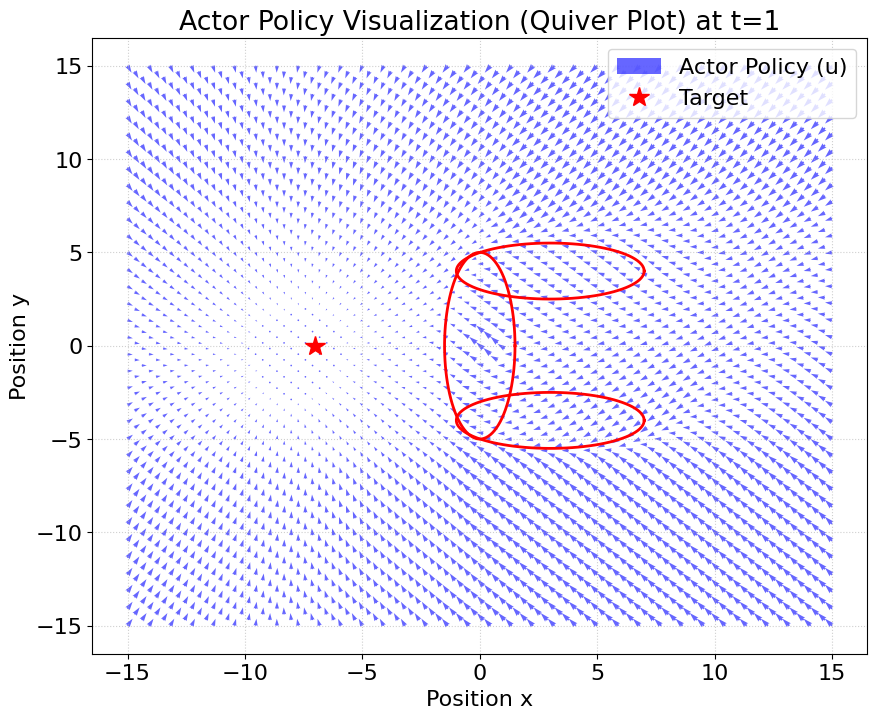

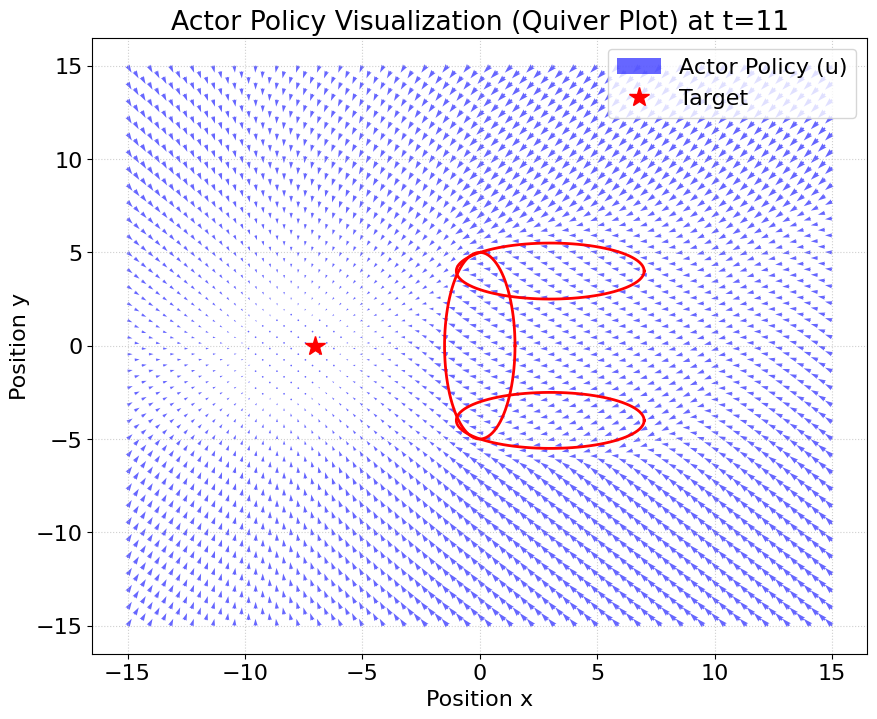

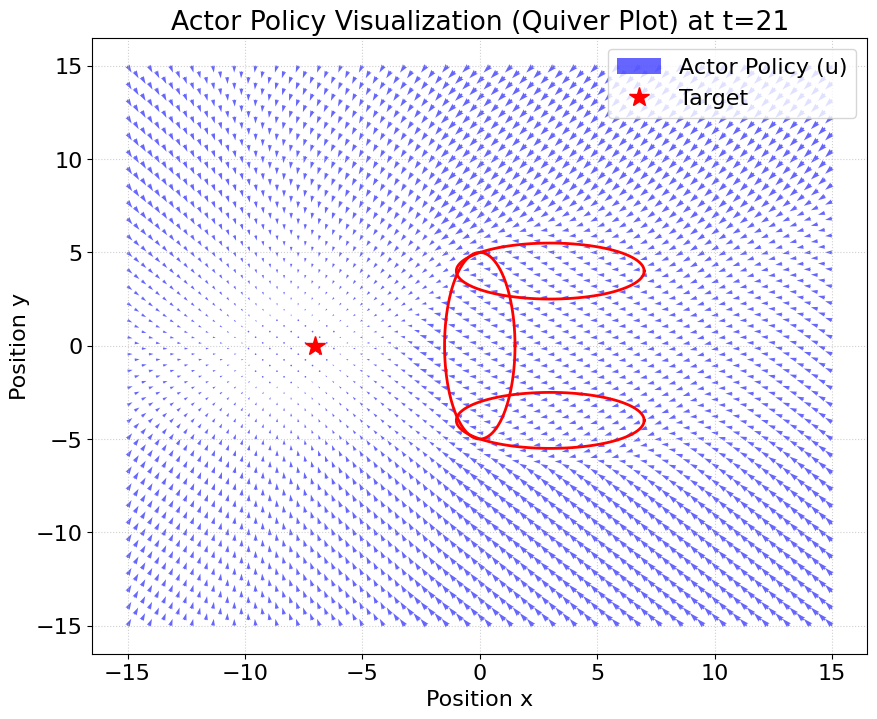

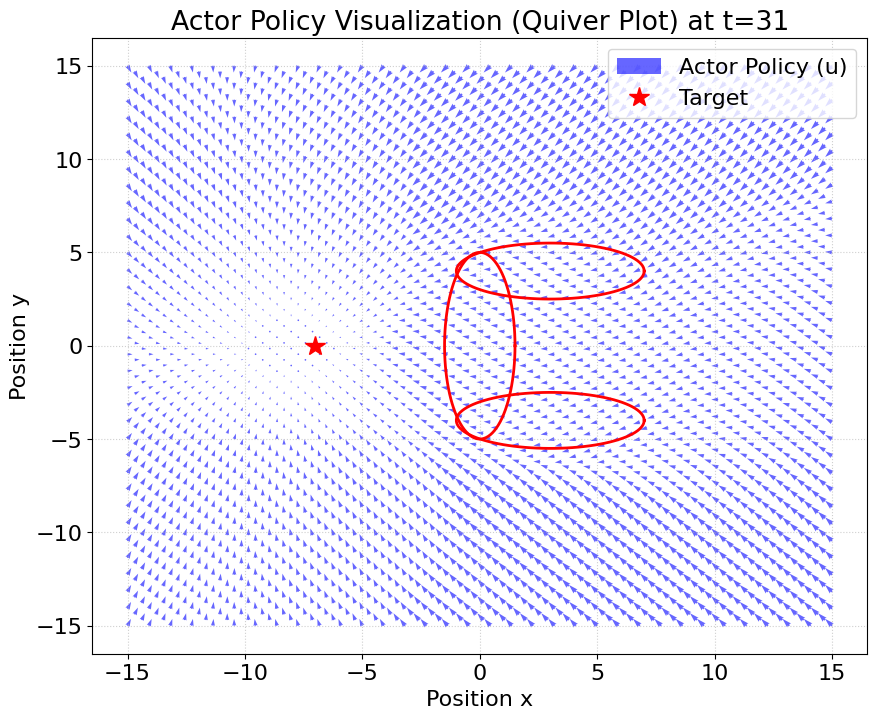

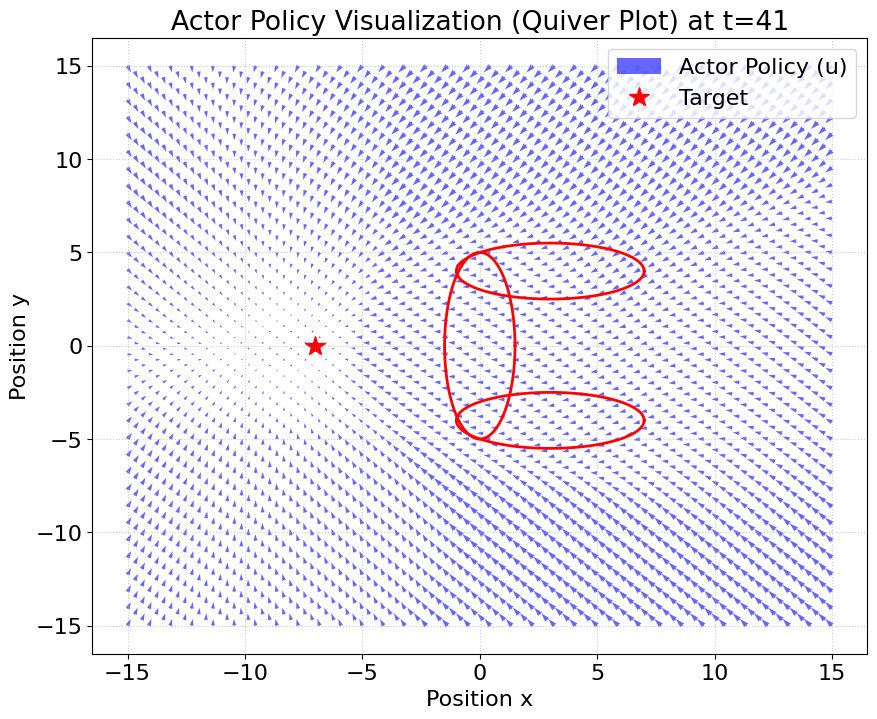

In [36]:
# Train the constrained actor again with the new critic

# Augmented Lagrangian parameters reset 
cons_actor.rho_x = 1000.0   
cons_actor.lambda_x = jnp.zeros_like(cons_actor.lambda_x)

print(f"\n--- CACTO Iteration {iter_count} ---\n")
train_constr_actor()

for t in range(1, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/24 | Violating: 13/24
Actor Only -> Avg. max violation: 0.4582


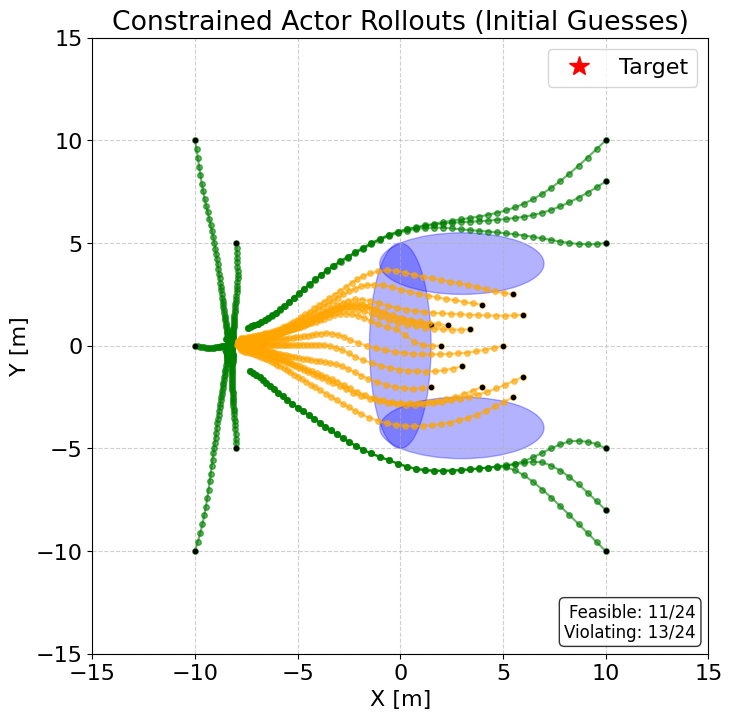

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=9: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. 

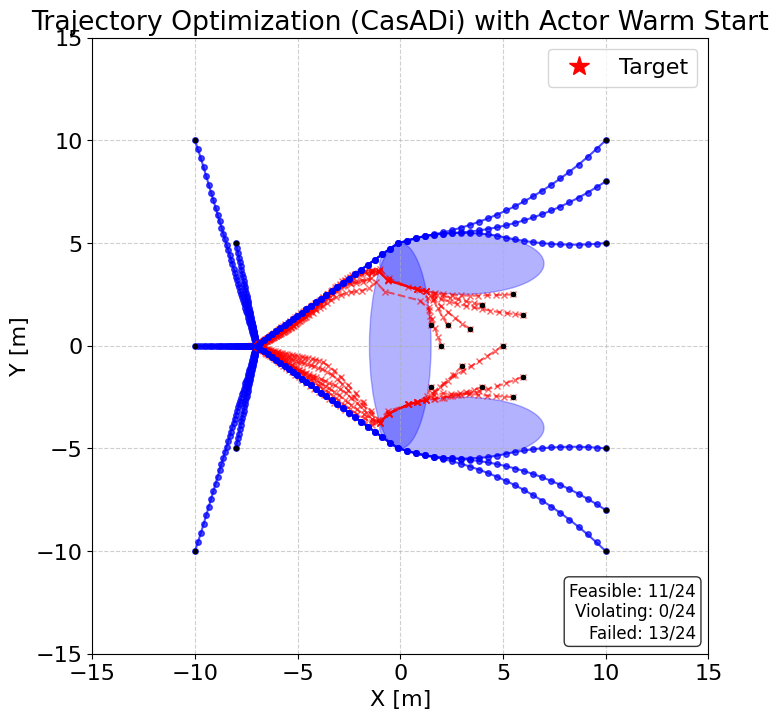

In [37]:
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()


--- CACTO Iteration 3 ---

Start solving 300 TO problems
Computing warm start guesses via Actor...


Risoluzione OCP:   8%|▊         | 23/300 [00:08<02:07,  2.18traj/s]

i=22, X=[8.93746257 0.61904609]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:   8%|▊         | 25/300 [00:09<01:59,  2.30traj/s]

i=24, X=[11.59016851  2.68501442]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=276, X=[12.8611172   4.04312204]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  96%|█████████▋| 289/300 [01:42<00:04,  2.24traj/s]

i=288, X=[ 2.60234135 -0.6783698 ]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [01:46<00:00,  2.83traj/s]


--- Finished ---
Successfully solved: 265 / 300
States Buffer size: (13250, 3) samples
Time taken: 107.982 s
--- Start training critic ---
Epoch 1/50 | MSE: 703.8374 | RMSE: 26.5299
Epoch 5/50 | MSE: 443.9759 | RMSE: 21.0707
Epoch 10/50 | MSE: 1166.1915 | RMSE: 34.1495
Epoch 15/50 | MSE: 799.4094 | RMSE: 28.2738
Epoch 20/50 | MSE: 908.7422 | RMSE: 30.1454
Epoch 25/50 | MSE: 792.3328 | RMSE: 28.1484
Epoch 30/50 | MSE: 361.2849 | RMSE: 19.0075
Epoch 35/50 | MSE: 734.1423 | RMSE: 27.0951
Epoch 40/50 | MSE: 707.1923 | RMSE: 26.5931
Epoch 45/50 | MSE: 714.0194 | RMSE: 26.7211
Epoch 50/50 | MSE: 159.7585 | RMSE: 12.6396
Final Critic MSE: 159.76
Final Critic RMSE: 12.64
--- Critic training has finished ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1359.6953 | Max Viol: 0.00186 | Rho: 1200.0 | dQ/du norm: 3.388573
Epoch 5/50 | Mean Q+ALM: -1357.9641 | Max Viol: 0.00063 | Rho: 2488.3 | dQ/du norm: 4.960649
Ep

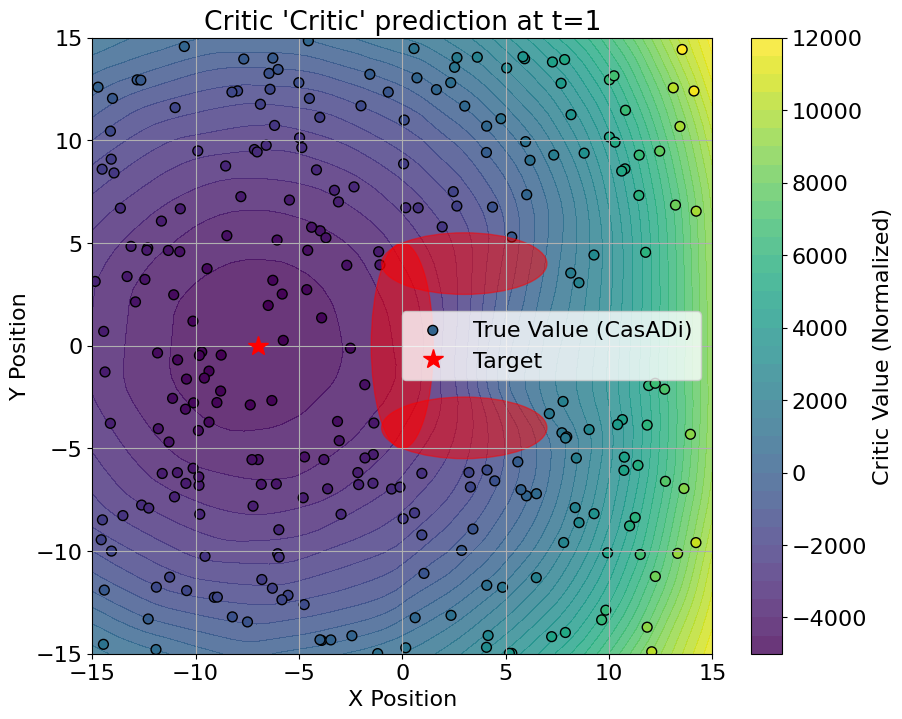

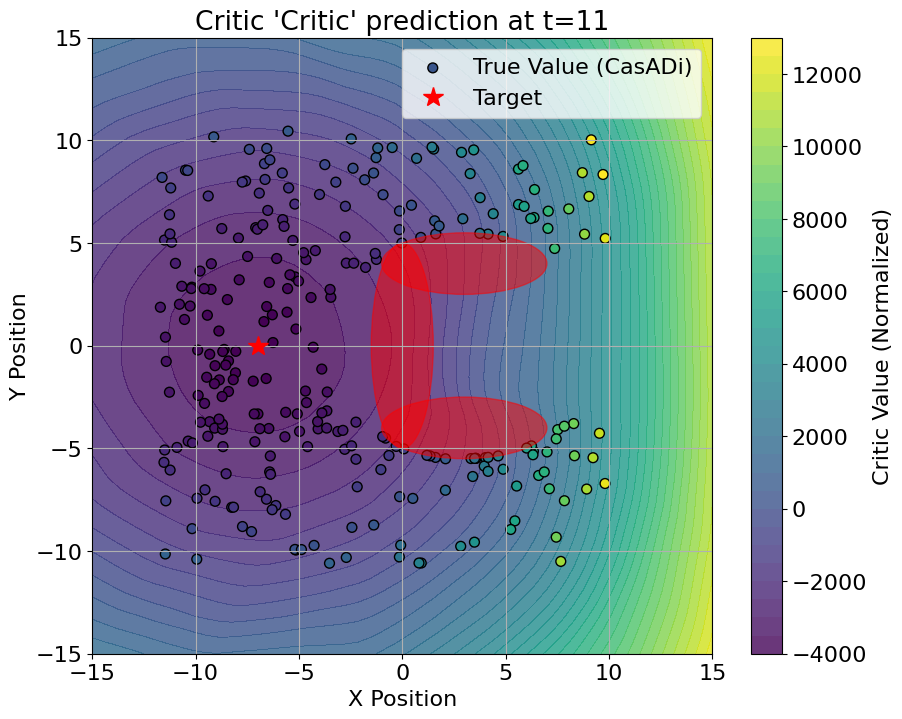

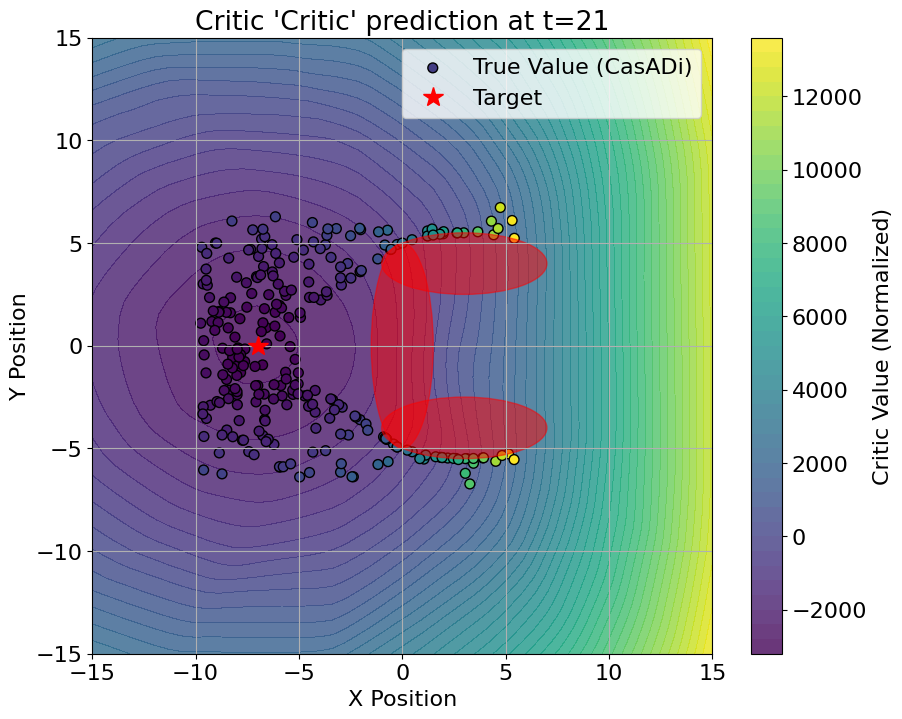

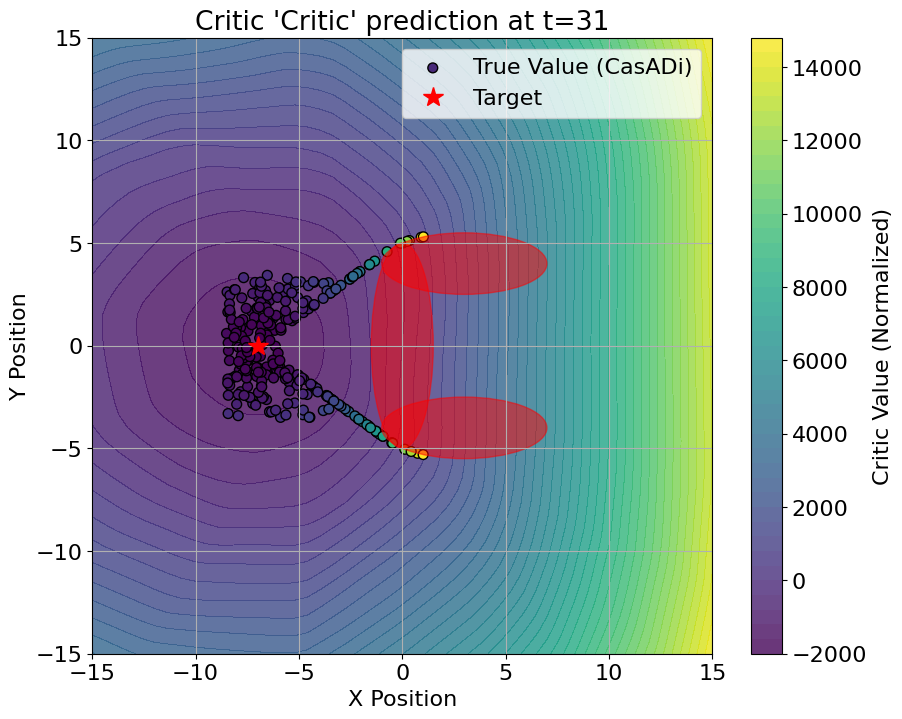

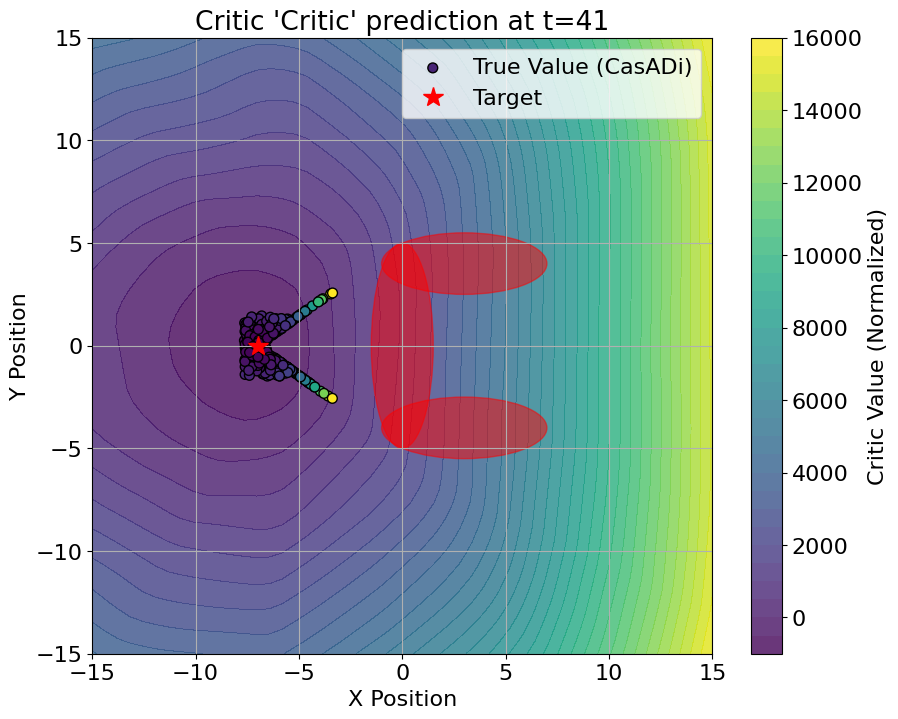

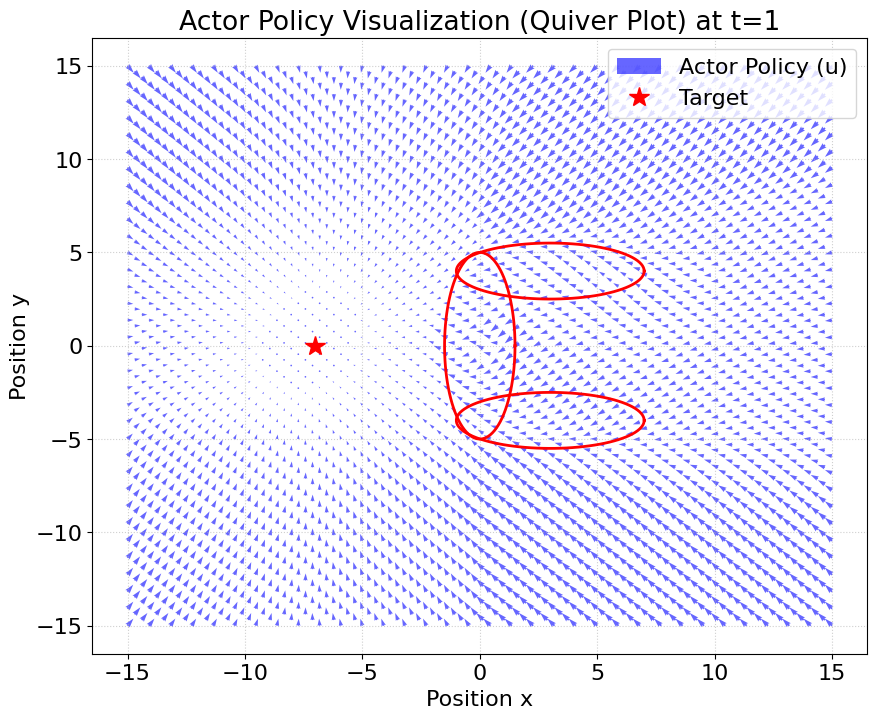

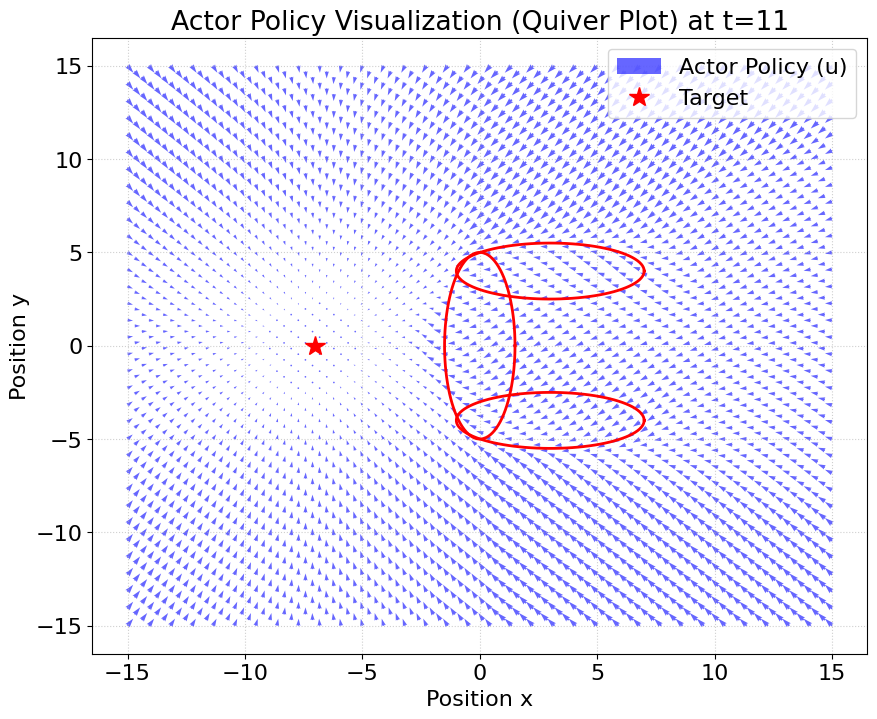

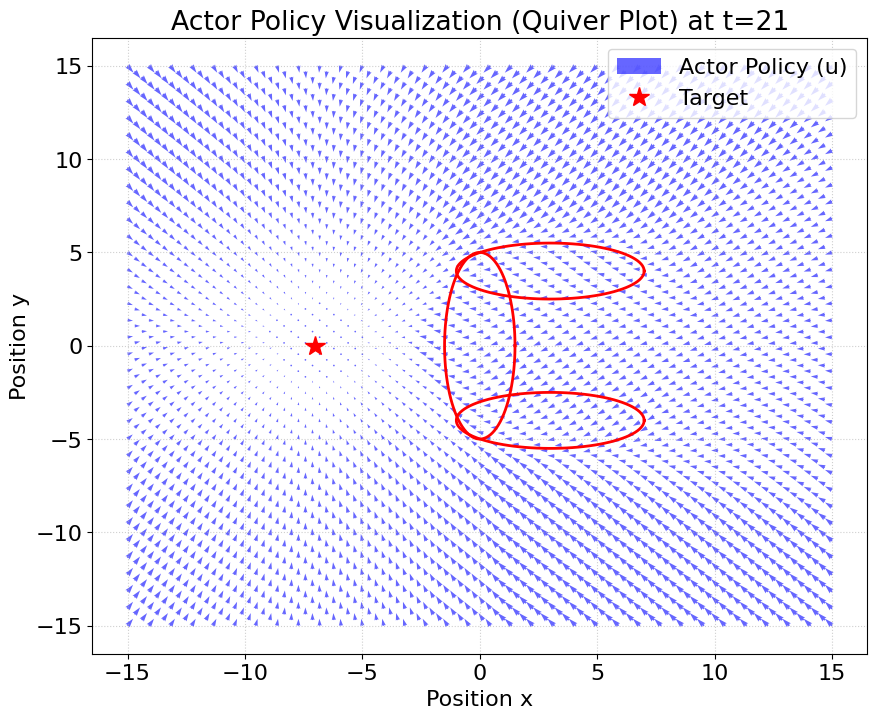

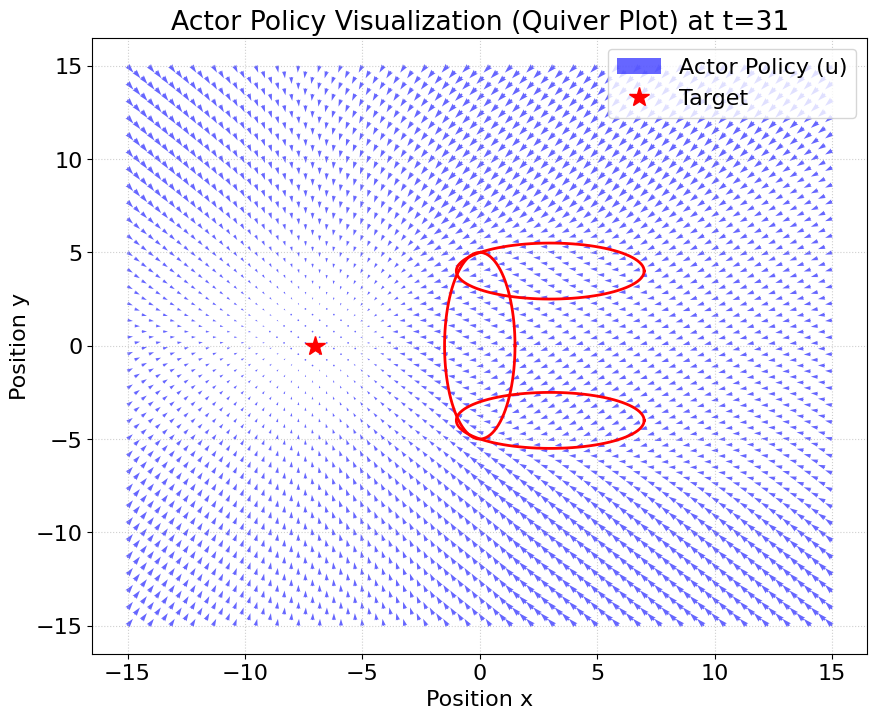

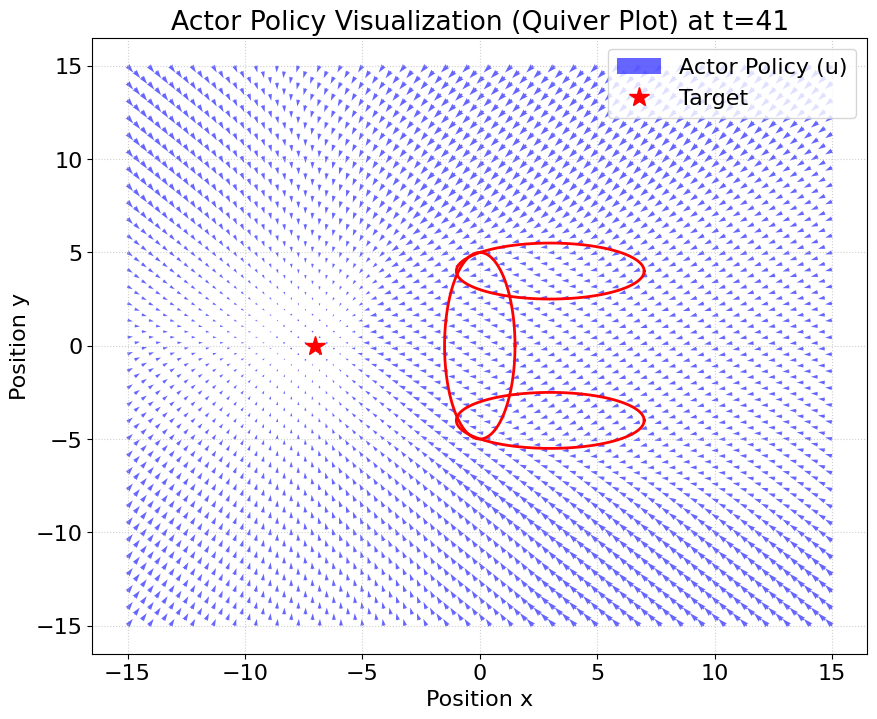

In [38]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
iter_count += 1
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

# Train the critic again with the new data in the buffer 
train_critic()

for t in range(1, N, 10):
  plot_critic(critic, t, show=False)
  
  
# Train the constrained actor again with the new critic

# Augmented Lagrangian parameters reset 
cons_actor.rho_x = 1000.0   
cons_actor.lambda_x = jnp.zeros_like(cons_actor.lambda_x)

train_constr_actor()

for t in range(1, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 8/24 | Violating: 16/24
Actor Only -> Avg. max violation: 0.4866


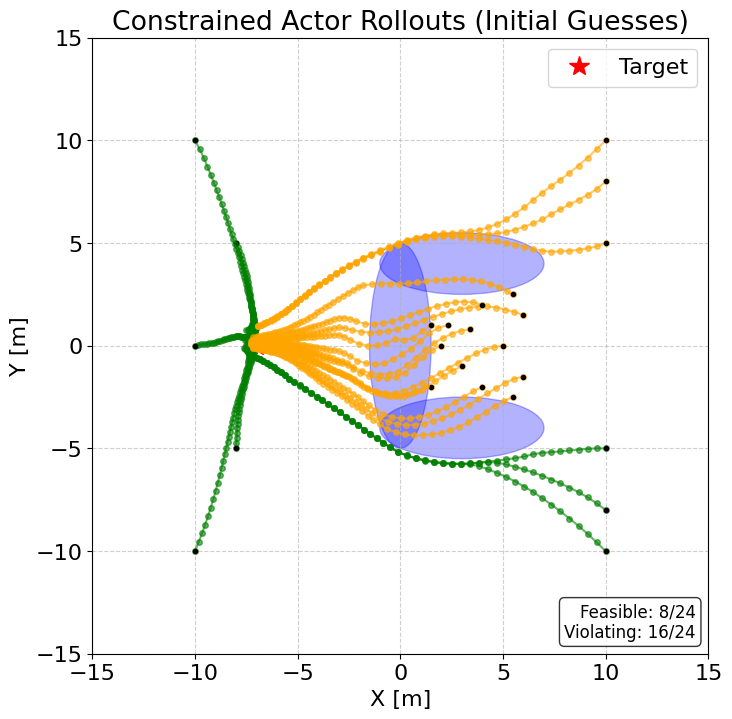

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables.

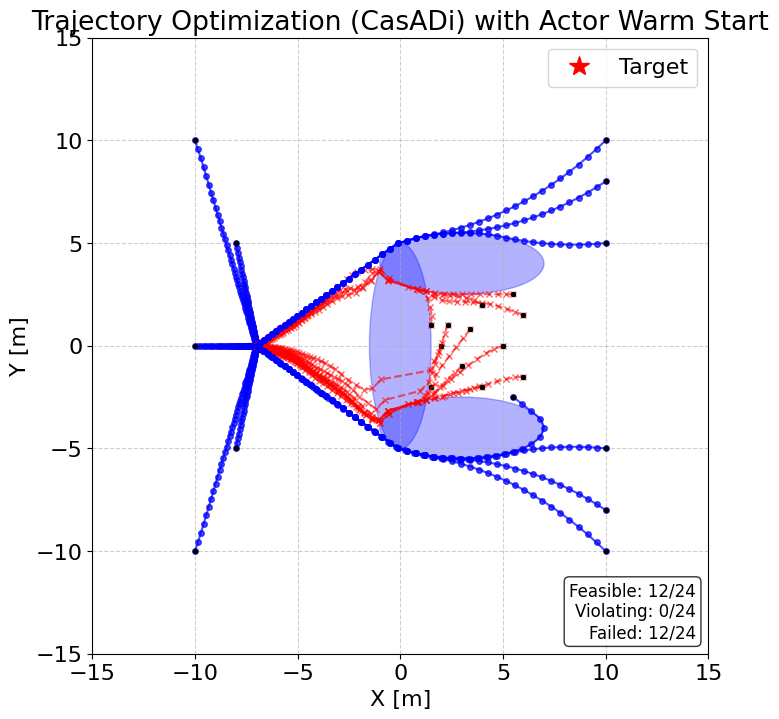

In [39]:
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()


--- CACTO Iteration 4 ---

Start solving 300 TO problems
Computing warm start guesses via Actor...


Risoluzione OCP:   2%|▏         | 6/300 [00:02<02:07,  2.31traj/s]

i=5, X=[14.60267098 11.24036121]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:   6%|▋         | 19/300 [00:07<02:02,  2.29traj/s]

i=18, X=[13.06818726  0.18559605]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=285, X=[ 7.7703362  -0.35597842]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  99%|█████████▊| 296/300 [01:52<00:01,  2.59traj/s]

i=295, X=[6.1288766  0.41651736]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [01:53<00:00,  2.63traj/s]


--- Finished ---
Successfully solved: 273 / 300
States Buffer size: (13650, 3) samples
Time taken: 115.902 s
--- Start training critic ---
Epoch 1/50 | MSE: 480.6027 | RMSE: 21.9227
Epoch 5/50 | MSE: 504.7368 | RMSE: 22.4663
Epoch 10/50 | MSE: 418.9565 | RMSE: 20.4684
Epoch 15/50 | MSE: 198.6012 | RMSE: 14.0926
Epoch 20/50 | MSE: 380.0522 | RMSE: 19.4949
Epoch 25/50 | MSE: 549.0897 | RMSE: 23.4327
Epoch 30/50 | MSE: 859.7031 | RMSE: 29.3207
Epoch 35/50 | MSE: 221.6140 | RMSE: 14.8867
Epoch 40/50 | MSE: 287.6368 | RMSE: 16.9599
Epoch 45/50 | MSE: 731.4805 | RMSE: 27.0459
Epoch 50/50 | MSE: 283.1614 | RMSE: 16.8274
Final Critic MSE: 283.16
Final Critic RMSE: 16.83
--- Critic training has finished ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1295.6016 | Max Viol: 0.00161 | Rho: 1200.0 | dQ/du norm: 3.445156
Epoch 5/50 | Mean Q+ALM: -1294.4080 | Max Viol: 0.00144 | Rho: 2488.3 | dQ/du norm: 4.789831
Epo

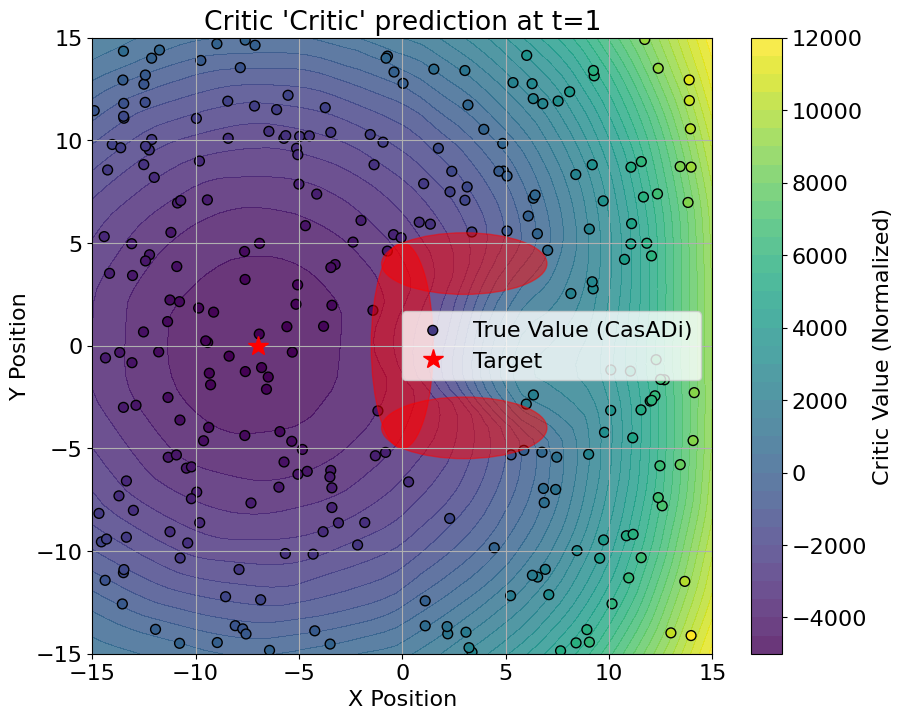

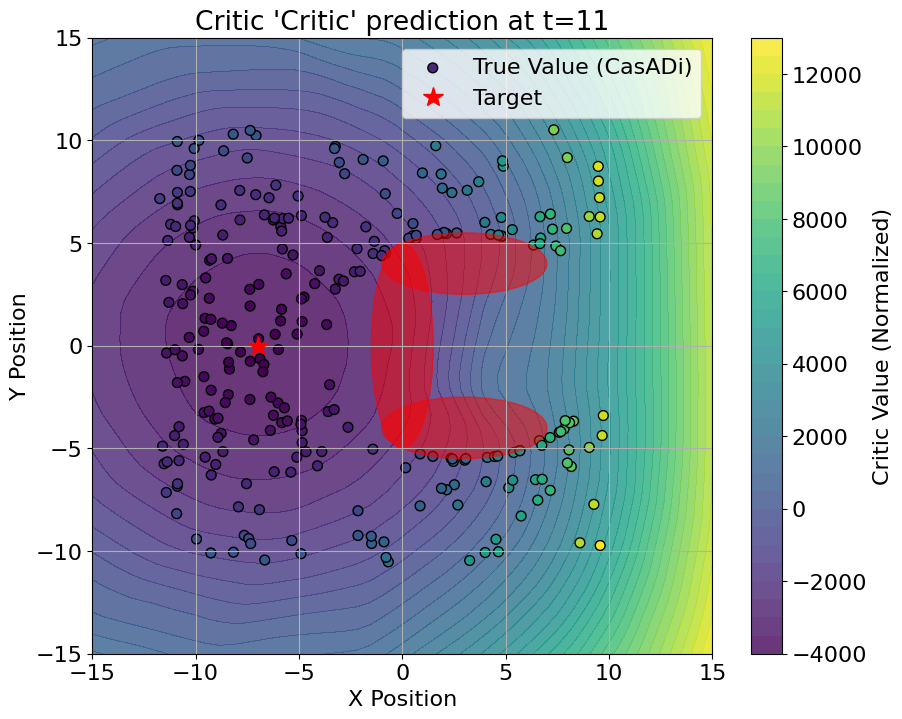

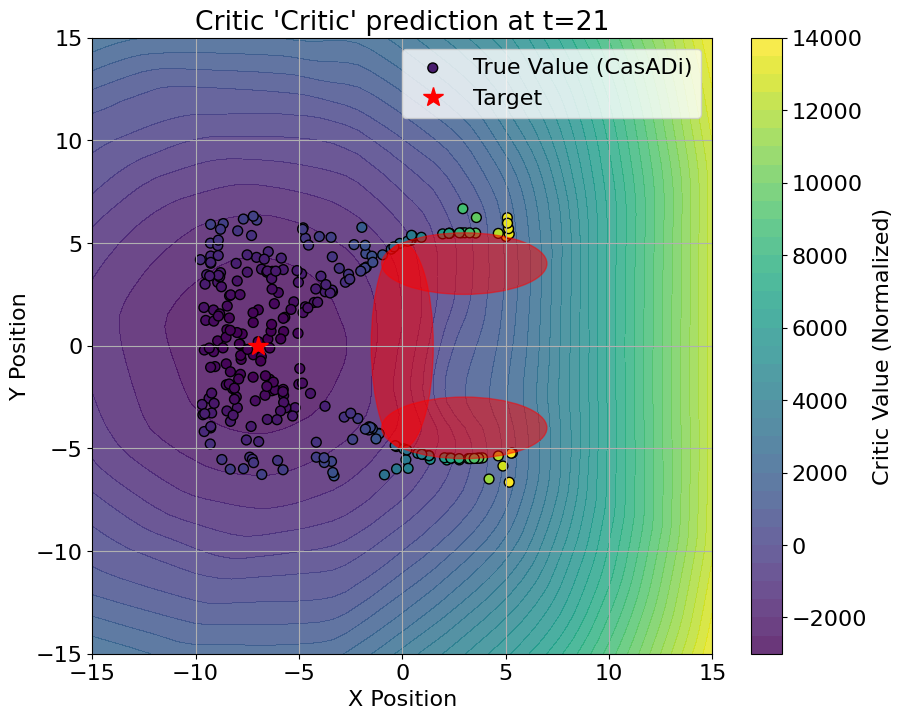

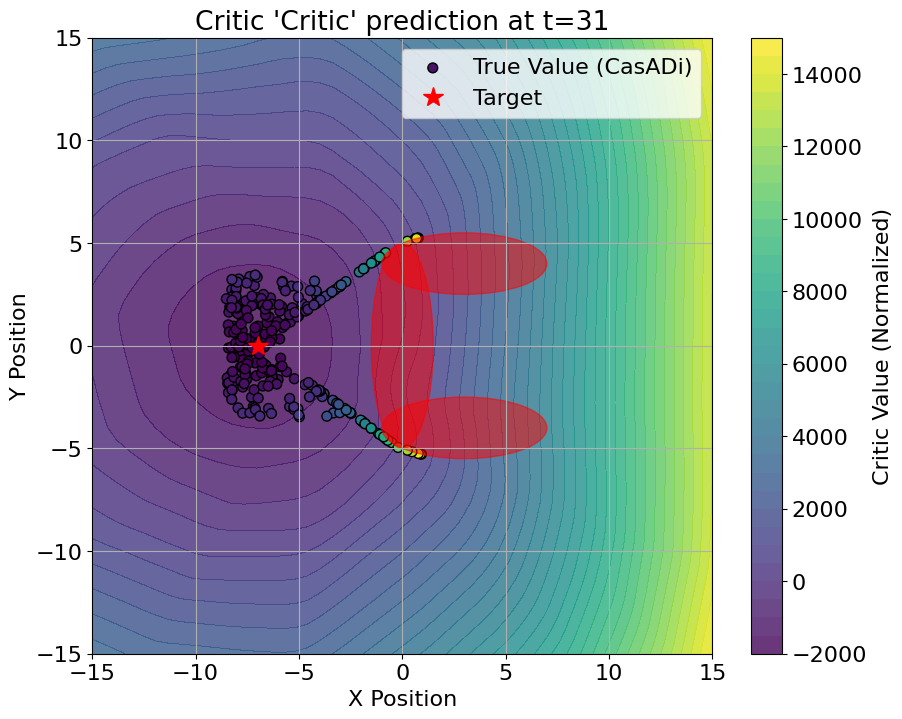

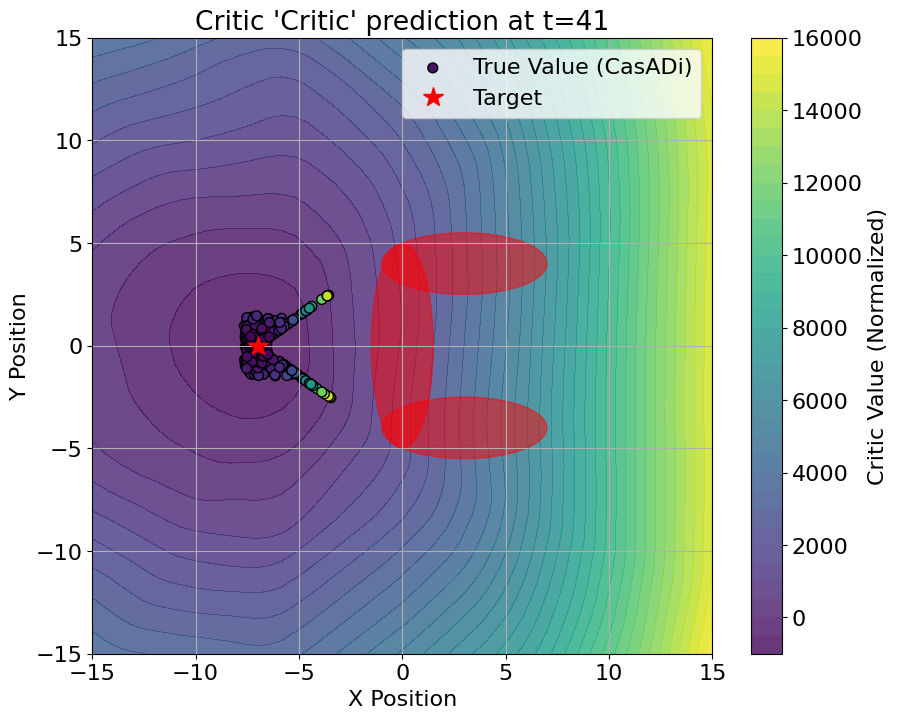

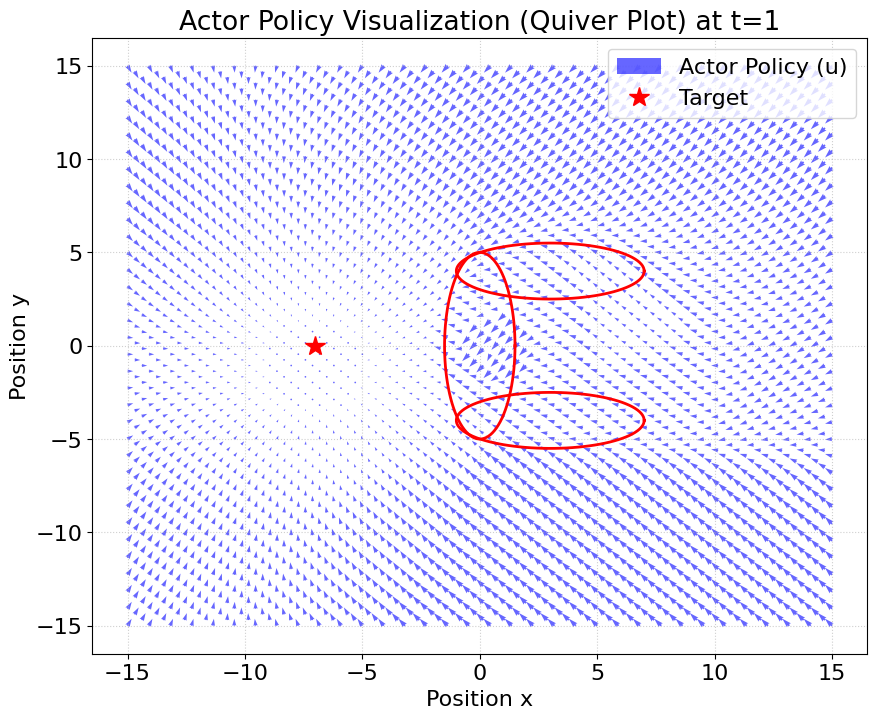

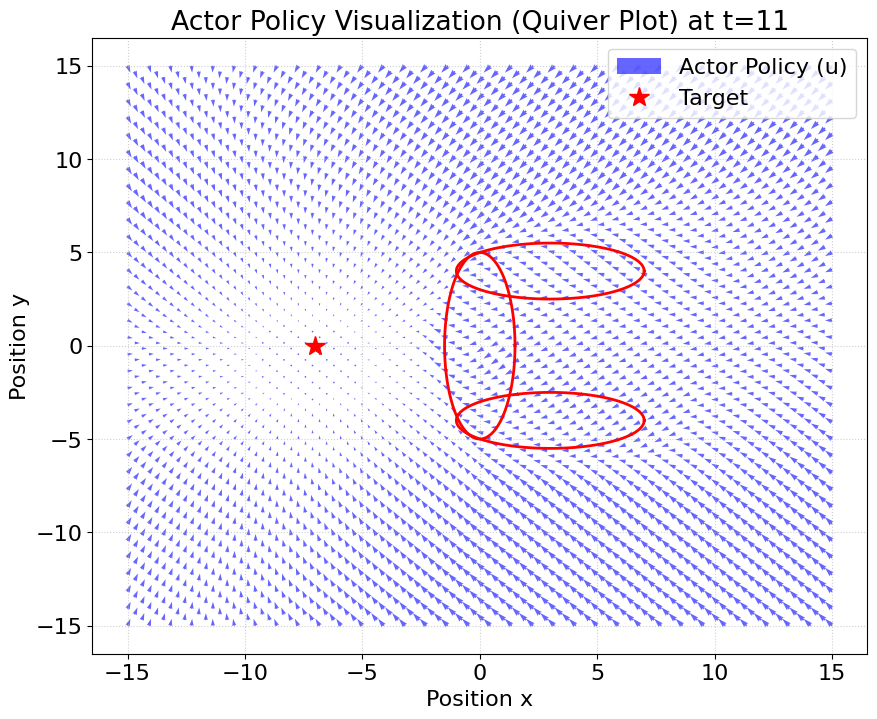

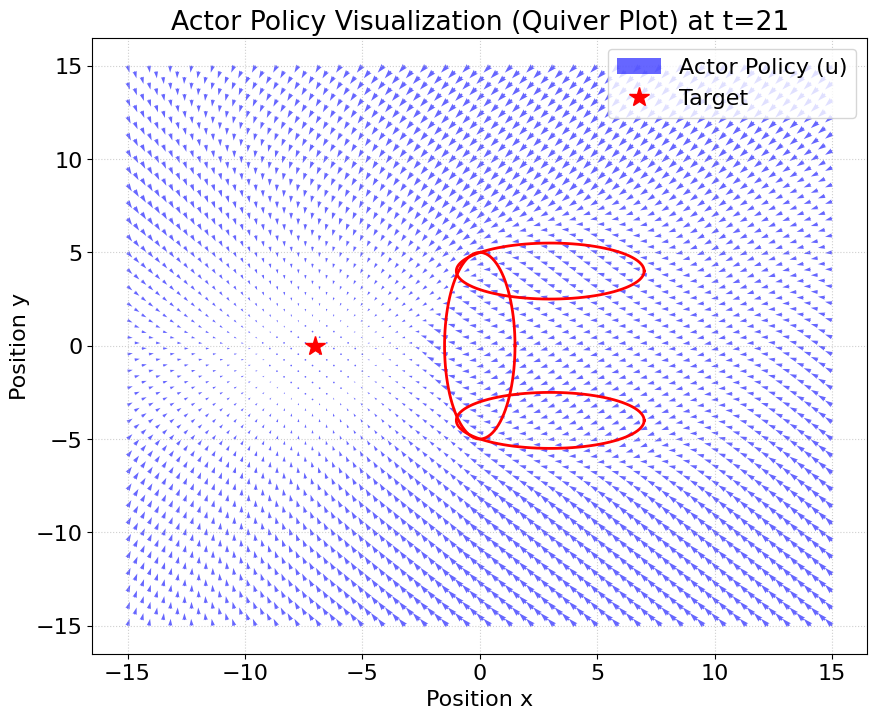

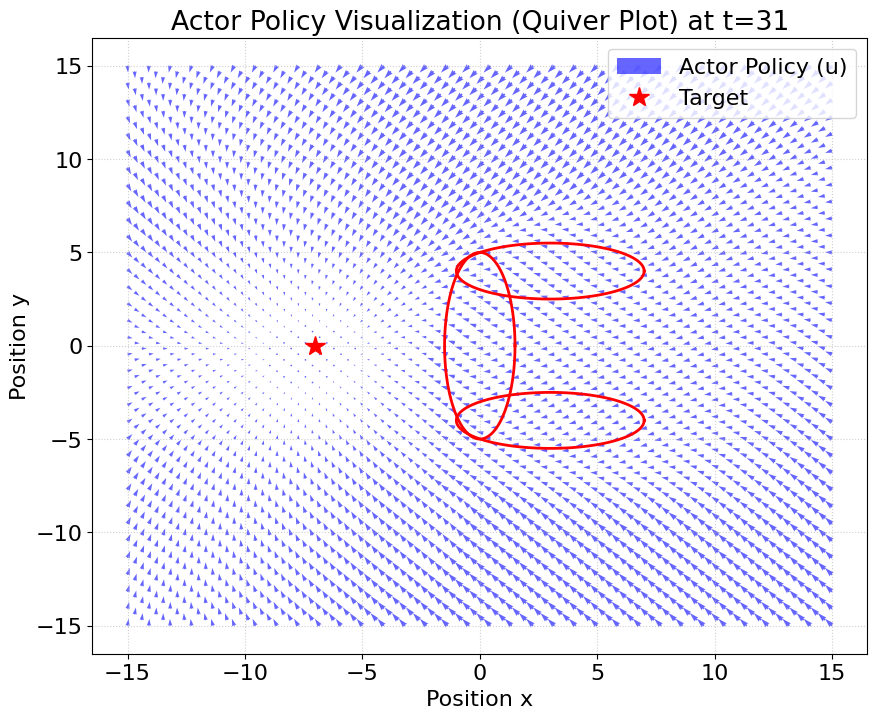

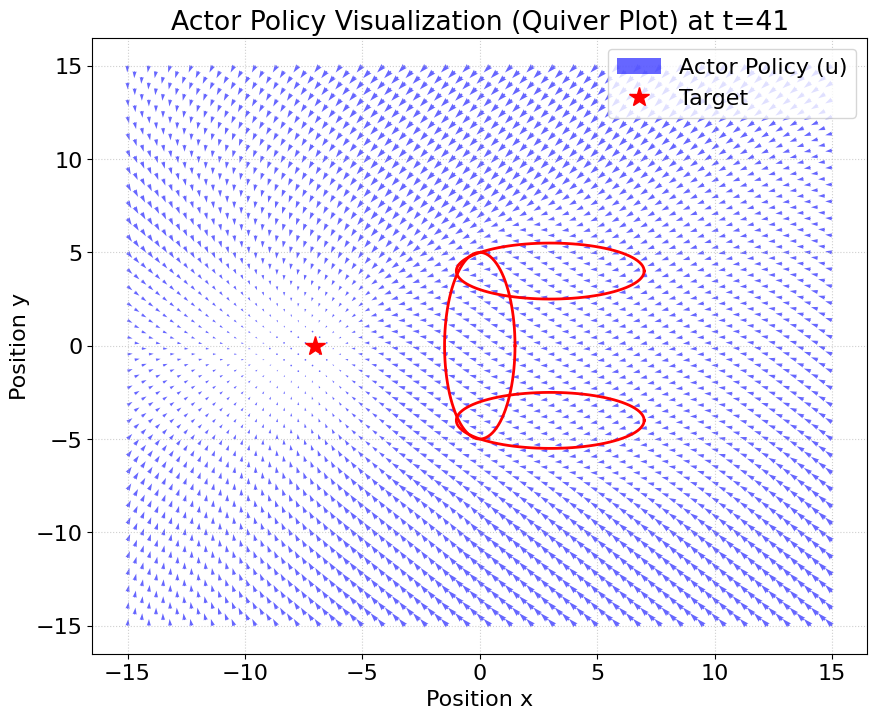

In [40]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
iter_count += 1
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

# Train the critic again with the new data in the buffer 
train_critic()

for t in range(1, N, 10):
  plot_critic(critic, t, show=False)
  
  
# Train the constrained actor again with the new critic

# Augmented Lagrangian parameters reset 
cons_actor.rho_x = 1000.0   
cons_actor.lambda_x = jnp.zeros_like(cons_actor.lambda_x)

train_constr_actor()

for t in range(1, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/24 | Violating: 13/24
Actor Only -> Avg. max violation: 0.4518


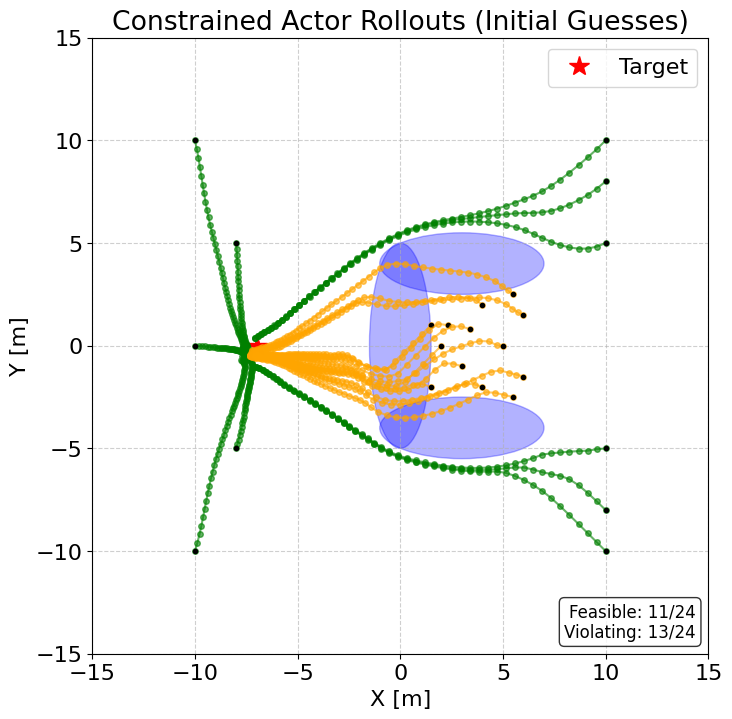

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=9: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. 

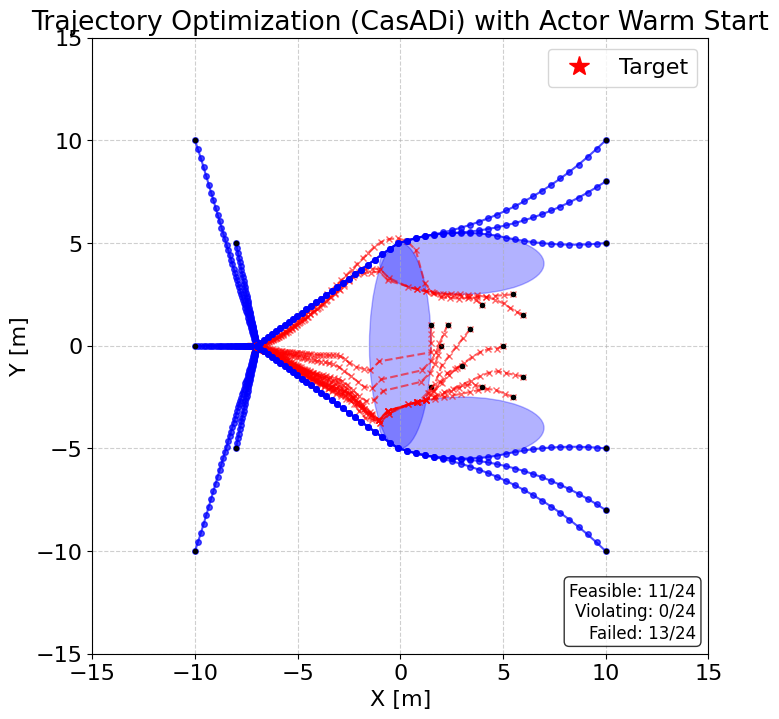

In [41]:
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()


--- CACTO Iteration 5 ---

Start solving 300 TO problems
Computing warm start guesses via Actor...


Risoluzione OCP:   1%|          | 2/300 [00:01<02:41,  1.85traj/s]

i=1, X=[3.03342556 2.20729419]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:   1%|▏         | 4/300 [00:02<02:58,  1.66traj/s]

i=3, X=[3.67258113 0.60558944]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


...

i=261, X=[13.78690172 -0.58050308]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP:  96%|█████████▌| 287/300 [02:04<00:06,  1.99traj/s]

i=286, X=[ 6.82718603 -0.4597083 ]: OCP failed | Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


Risoluzione OCP: 100%|██████████| 300/300 [02:11<00:00,  2.29traj/s]


--- Finished ---
Successfully solved: 269 / 300
States Buffer size: (13450, 3) samples
Time taken: 133.220 s
--- Start training critic ---
Epoch 1/50 | MSE: 339.7409 | RMSE: 18.4321
Epoch 5/50 | MSE: 826.1227 | RMSE: 28.7424
Epoch 10/50 | MSE: 1141.9386 | RMSE: 33.7926
Epoch 15/50 | MSE: 337.2421 | RMSE: 18.3642
Epoch 20/50 | MSE: 618.1578 | RMSE: 24.8628
Epoch 25/50 | MSE: 559.6329 | RMSE: 23.6566
Epoch 30/50 | MSE: 802.8455 | RMSE: 28.3345
Epoch 35/50 | MSE: 349.8062 | RMSE: 18.7031
Epoch 40/50 | MSE: 521.6703 | RMSE: 22.8401
Epoch 45/50 | MSE: 1271.5266 | RMSE: 35.6585
Epoch 50/50 | MSE: 415.5483 | RMSE: 20.3850
Final Critic MSE: 415.55
Final Critic RMSE: 20.39
--- Critic training has finished ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 50 epochs ---
Epoch 1/50 | Mean Q+ALM: -1311.3215 | Max Viol: 0.00179 | Rho: 1200.0 | dQ/du norm: 3.669492
Epoch 5/50 | Mean Q+ALM: -1311.2609 | Max Viol: 0.00157 | Rho: 2488.3 | dQ/du norm: 3.642467
E

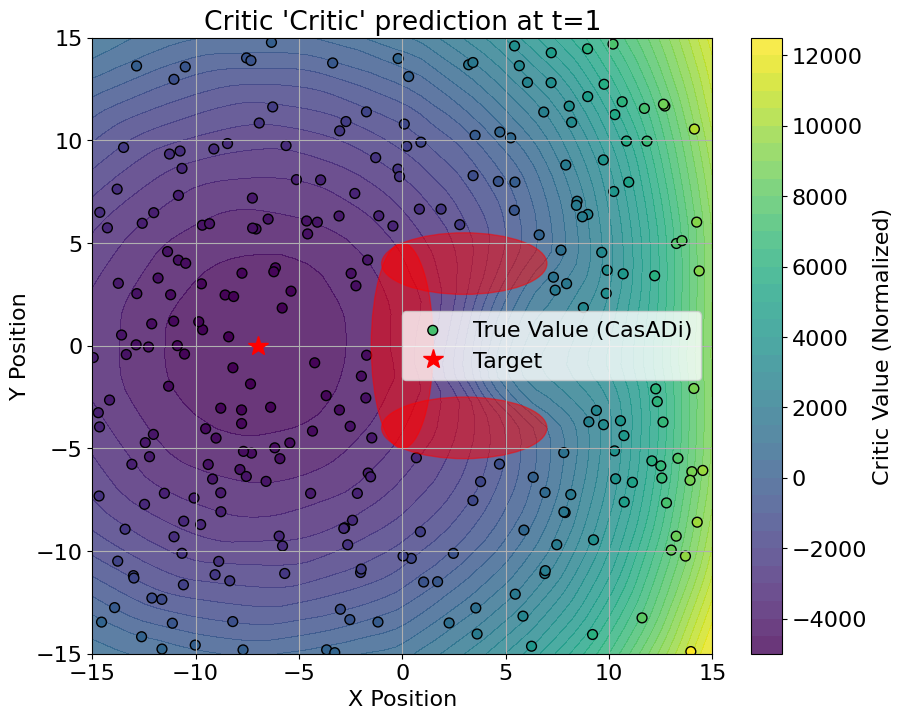

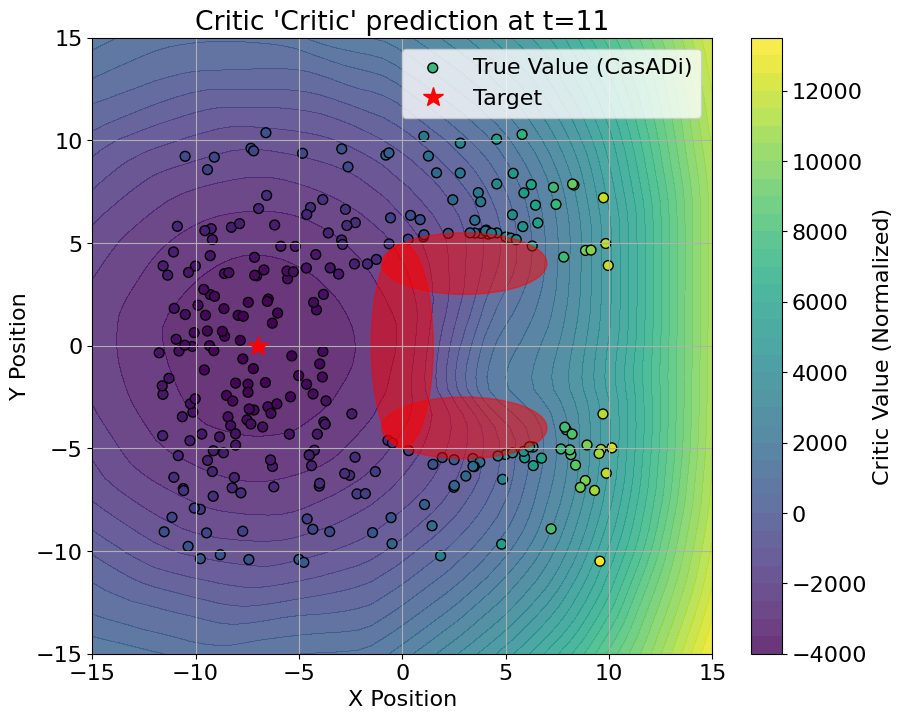

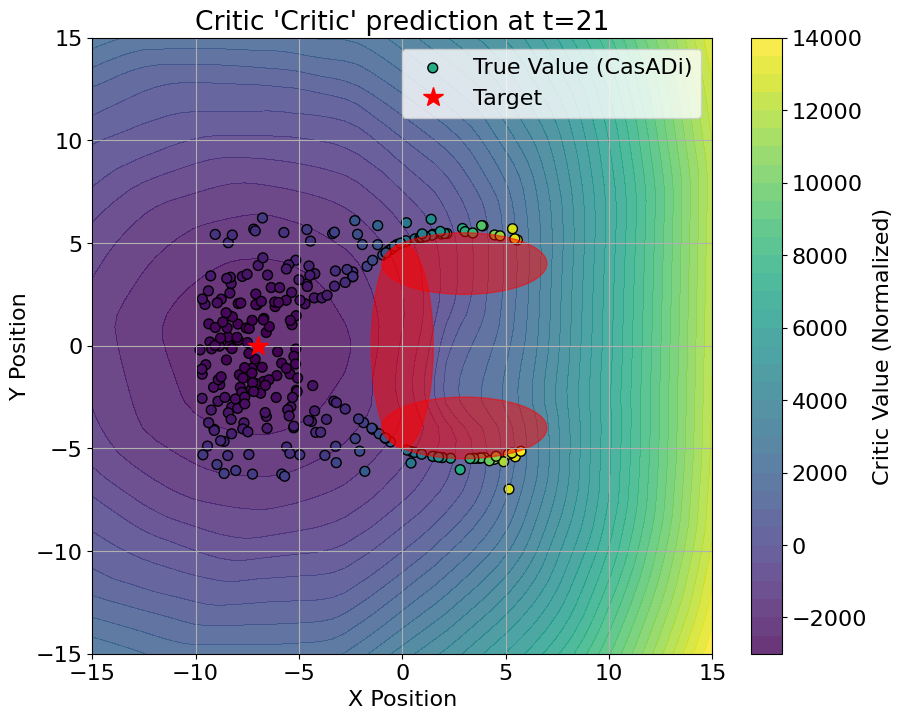

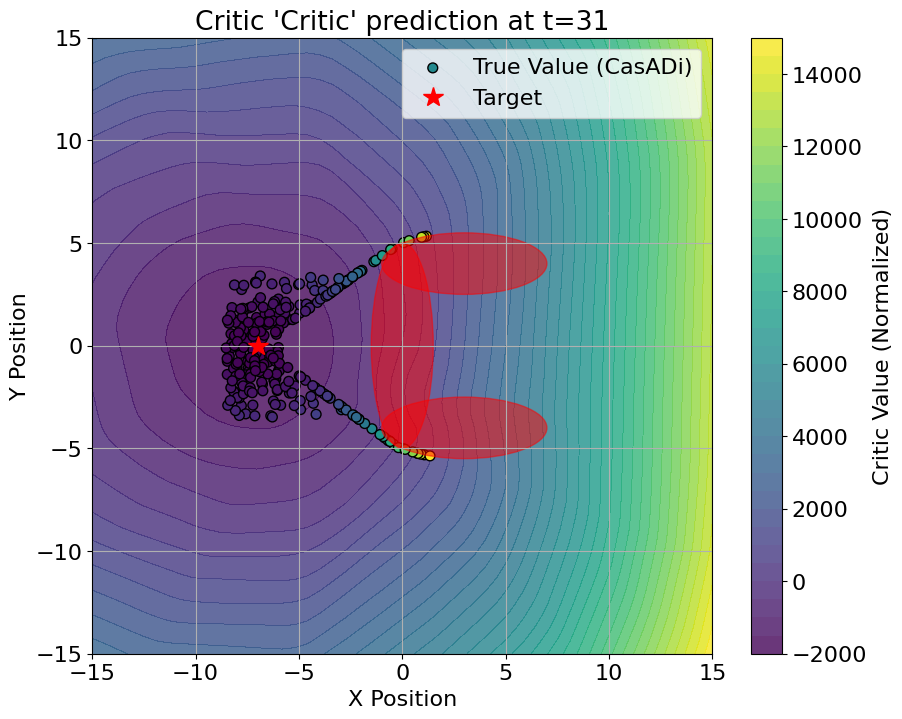

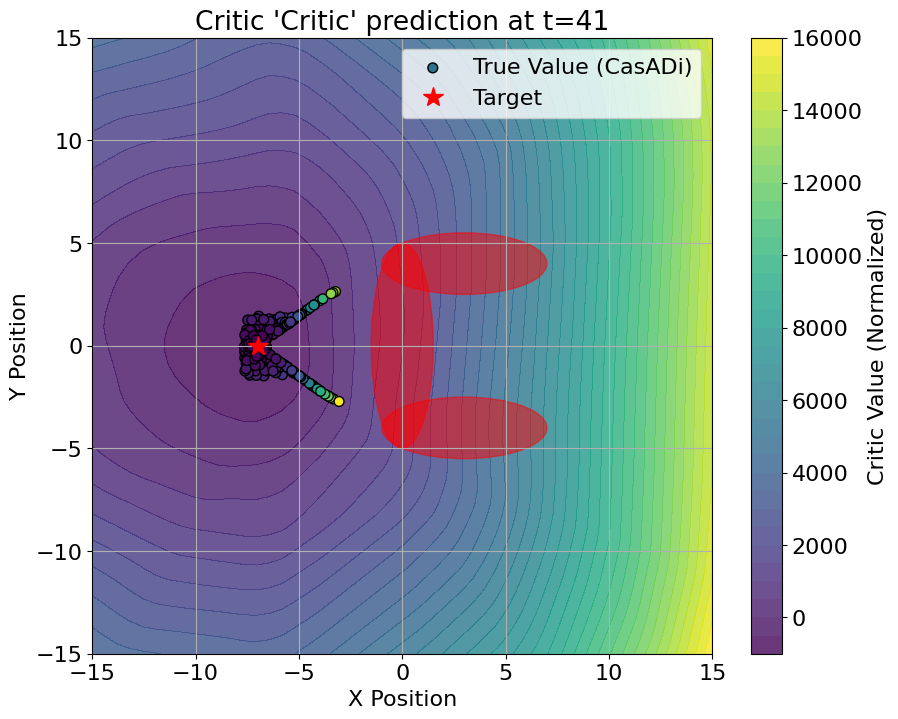

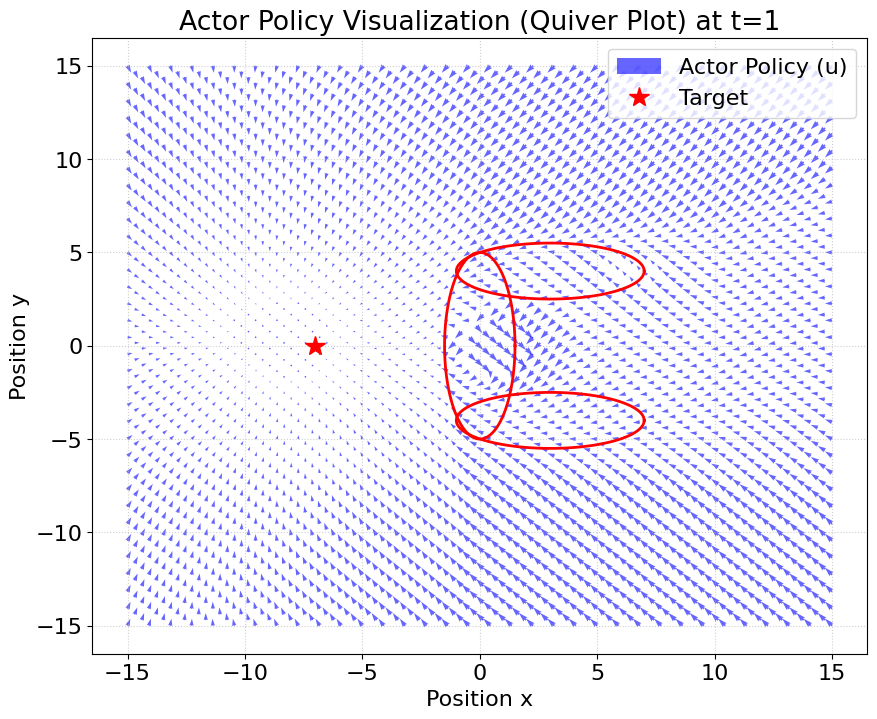

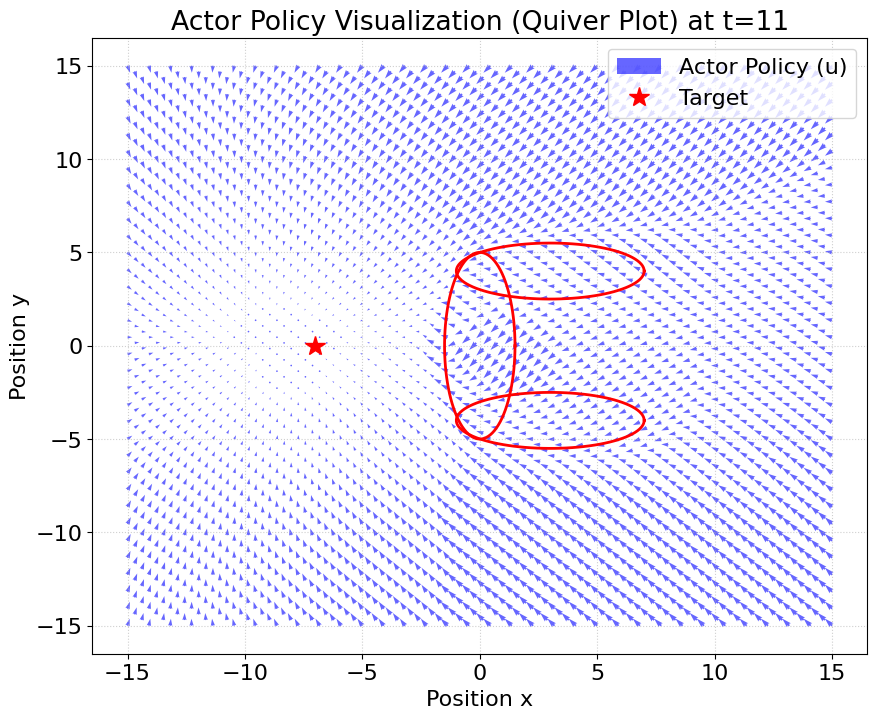

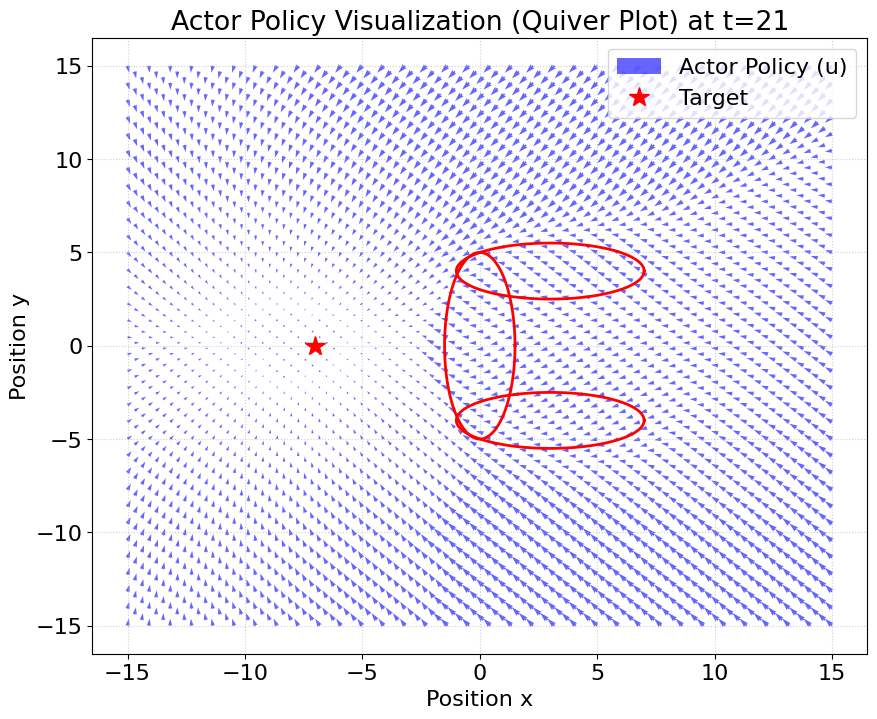

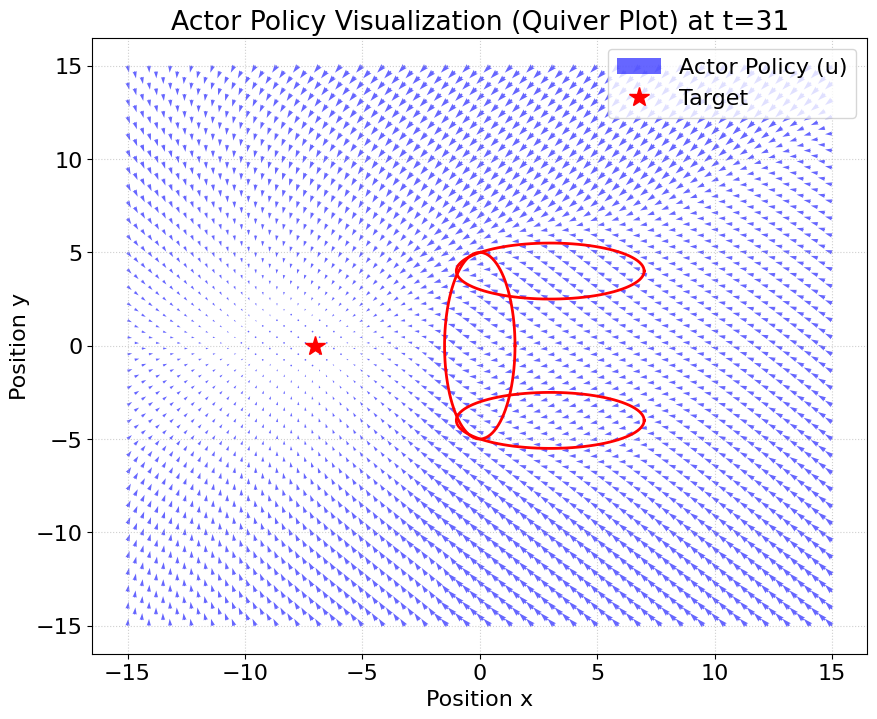

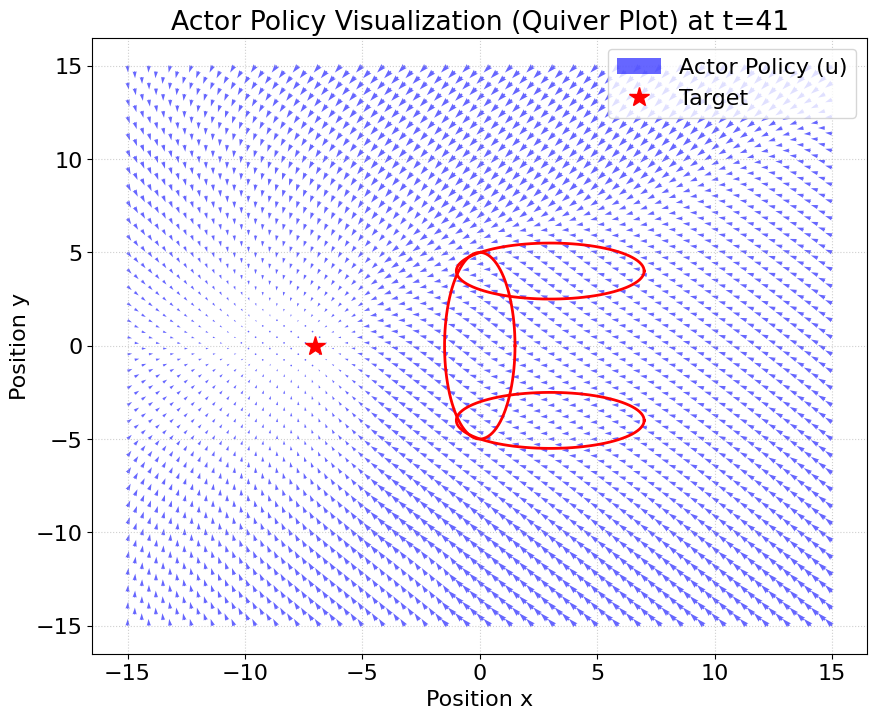

In [42]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
iter_count += 1
print(f"\n--- CACTO Iteration {iter_count} ---\n")
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

# Train the critic again with the new data in the buffer 
train_critic()

for t in range(1, N, 10):
  plot_critic(critic, t, show=False)
  
  
# Train the constrained actor again with the new critic

# Augmented Lagrangian parameters reset 
cons_actor.rho_x = 1000.0   
cons_actor.lambda_x = jnp.zeros_like(cons_actor.lambda_x)

train_constr_actor()

for t in range(1, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/24 | Violating: 13/24
Actor Only -> Avg. max violation: 0.3974


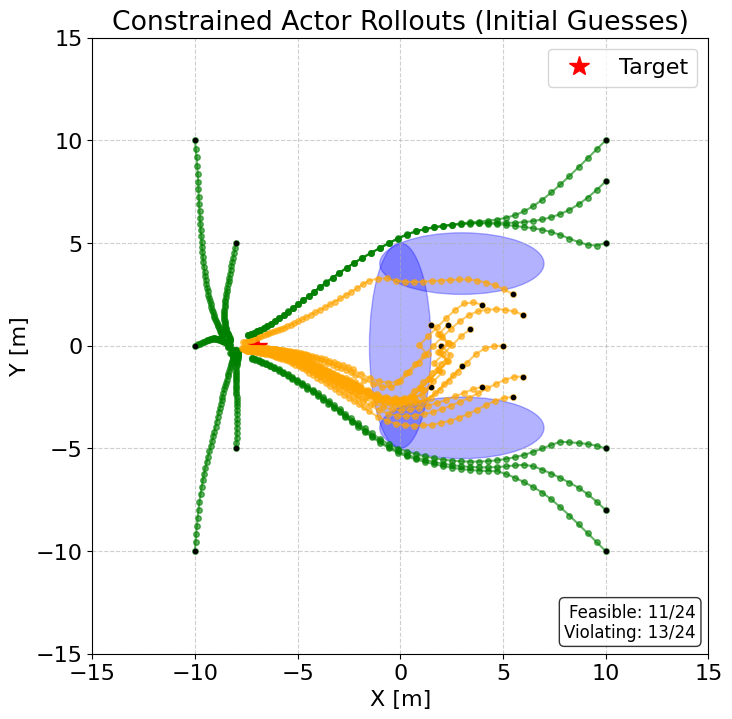

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=6: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=7: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=8: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=9: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. 

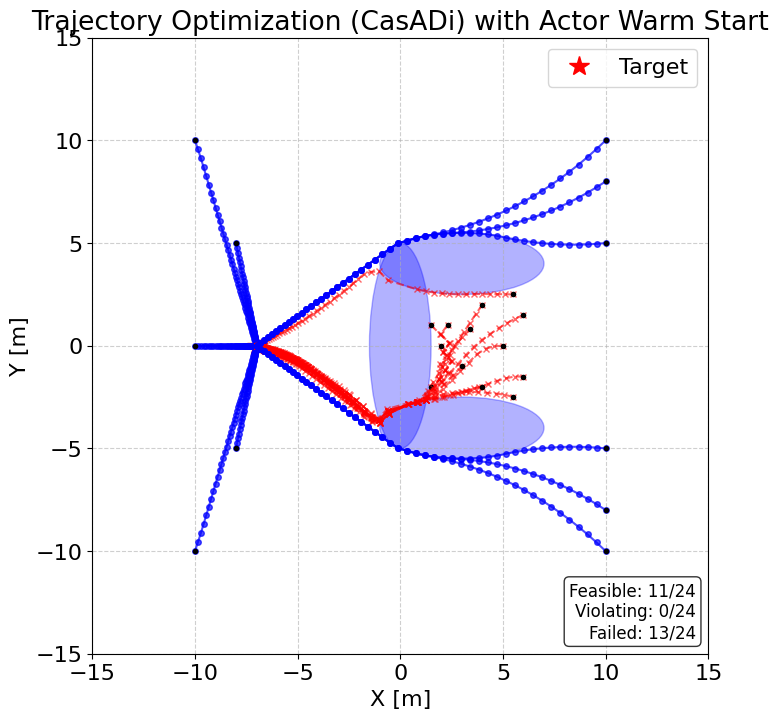

In [43]:
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()